# 03b — Multi-object tracking benchmark (DanceTrack, SORT / ByteTrack / OC-SORT / BoT-SORT)

Notebook có 3 chế độ, đổi `MODE` ở cell cấu hình:

| MODE | Dữ liệu | Chạy ở đâu | Dùng để |
|---|---|---|---|
| `dry` | tổng hợp, tạo tại chỗ | CPU, offline | kiểm tra toàn bộ notebook; **không bao giờ công bố** |
| `smoke` | 3 sequence val ngắn nhất + 1 sequence dev ngắn nhất, 3 cấu hình/tracker | Colab GPU | đo FPS, thời gian CMC, ước ngân sách; **không công bố điểm** |
| `full` | 25 val + 8 dev, mặc định + 20 cấu hình ngẫu nhiên/tracker | Colab GPU + CPU | kết quả chính thức (cần smoke hợp lệ trong cùng `RUN_ID`) |

**Hai tầng.** Tầng A sinh detections cố định một lần (GPU) cho hai nguồn: **(a)** RT-DETR-R18vd chỉ train COCO (chọn từ AP lớp `person` của 03a trên COCO, không nhìn DanceTrack), **(b)** checkpoint YOLOX công bố cho DanceTrack, tiền xử lý `imagenet_rgb` đã kiểm bằng smoke (precision 0.864 / recall 0.986 so với GT). Tầng B chạy 4 tracker trên các detections đó (CPU) rồi chấm bằng TrackEval đã ghim.

**Quy tắc đã đóng băng (registry, status = approved).** Tuning chỉ trên 8 sequence dev của train; chọn cấu hình dev-HOTA cao nhất, hòa thì chỉ số nhỏ hơn; cấu hình 0 = mặc định công bố, báo riêng. Val chạy đúng 2 cấu hình/tracker (mặc định, tuned). Bootstrap theo video 10.000 lần, cùng lần lấy mẫu cho mọi hệ thống, kết luận chỉ khi CI cặp loại trừ 0 **và** |ΔHOTA| ≥ 2.0. Không có điểm tổng hợp; hai nguồn detections không bao giờ nằm chung một bảng xếp hạng.

**Giới hạn phải nhớ.** (1) Nguồn (b) mang cờ `DETECTOR_TRAIN_DATA_UNVERIFIED`: registry ghi nó được train trên DanceTrack nhưng chưa xác minh val có nằm trong dữ liệu train hay không, nên không gọi là held-out. (2) BoT-SORT trong thư viện này **không có ReID** (IoU + bù chuyển động camera). (3) Chỉ 3 sequence val có camera di chuyển: kết quả theo camera chỉ mô tả. (4) DanceTrack là video nhảy, không ngoại suy sang video bài giảng. (5) FPS = chỉ thời gian `update` (không gồm detector và decode ảnh).

**Giấy phép.** `trackers` Apache-2.0, `supervision` MIT, RT-DETR-R18vd Apache-2.0. DanceTrack: annotation CC BY 4.0, dữ liệu chỉ cho nghiên cứu phi thương mại; không phát hành lại ảnh. Bundle chỉ chứa JSON/CSV/PNG; track thô ở Drive.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, subprocess, time, shutil, zipfile, re, platform, traceback, pickle
from datetime import datetime, timezone

# ============================ CẤU HÌNH ============================
MODE = 'full'              # 'dry' (tổng hợp, CPU) | 'smoke' (3 val + 1 dev, không công bố) | 'full'
RUN_ID = 'track-03b-261027-v1'
LICENSE_ACK = True       # smoke/full: đặt True sau khi đọc điều khoản DanceTrack (in ở cell dữ liệu)
GPU_BUDGET_HOURS = 12.0   # tầng A (detections), phần còn lại sau 03a
TIER_B_MAX_HOURS = 10.0   # trần thời gian tường tầng B (CPU)
ALLOW_OVER_BUDGET = False # chỉ đặt True sau khi người duyệt ngân sách đồng ý
# ===================================================================
assert MODE in ('dry', 'smoke', 'full')

IN_COLAB = Path('/content').exists()
if IN_COLAB and MODE != 'dry':
    from google.colab import drive
    drive.mount('/content/drive')
WORK = Path('/content/track03b') if IN_COLAB else Path.cwd() / 'track03b-work'
PERSIST = Path('/content/drive/MyDrive/DetTrack') if (IN_COLAB and MODE != 'dry') else WORK / 'persistent'
OUT = PERSIST / (RUN_ID + ('-dry' if MODE == 'dry' else ''))
for p in (WORK, OUT, OUT / 'figures', OUT / 'tables', OUT / 'dets', OUT / 'runs', OUT / 'scores'):
    p.mkdir(parents=True, exist_ok=True)
if MODE != 'dry' and not LICENSE_ACK:
    print('Đặt LICENSE_ACK = True sau khi đọc điều khoản DanceTrack (xem cell dữ liệu); notebook sẽ dừng ở đó.')
if os.environ.get('DT_SKIP_PIP') != '1':
    pkgs = ['trackers==2.6.1', 'supervision==0.31.2', 'scipy', 'opencv-python-headless', 'requests', 'huggingface_hub']
    if MODE != 'dry':
        pkgs += ['transformers==4.57.6', 'timm', 'safetensors', 'loguru', 'thop', 'tabulate']
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *pkgs], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--no-deps',
                    'https://github.com/JonathonLuiten/TrackEval/archive/12c8791b303e0a0b50f753af204249e622d0281a.zip'], check=True)
try:
    import torch
    GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
except ImportError:
    torch, GPU = None, None
print('MODE:', MODE, '| GPU:', GPU)
if MODE != 'dry' and GPU is None:
    print('CẢNH BÁO: không có GPU. Tầng A sẽ rất chậm và smoke-budget-gate sẽ KHÔNG hợp lệ (full bị từ chối).')

Mounted at /content/drive
MODE: full | GPU: None
CẢNH BÁO: không có GPU. Tầng A sẽ rất chậm và smoke-budget-gate sẽ KHÔNG hợp lệ (full bị từ chối).


In [2]:
SOURCES = {'experiments/scripts/detection_tracking_qualification.py': '"""Dataset qualification helpers for detection (03a) and tracking (03b).\n\nPure functions so the Colab notebook and the unit tests share one implementation.\nNothing here downloads data or runs a model.\n"""\n\nfrom __future__ import annotations\n\nimport hashlib\nimport json\nimport re\nimport zipfile\nfrom pathlib import Path\nfrom typing import Any, Callable, Iterable\n\nimport numpy as np\n\n# Frozen by the claim-freeze decision report (2026-10-26).\nCOCO_TAXONOMY = {  # COCO category id -> name\n    1: "person", 44: "bottle", 62: "chair", 72: "tv", 73: "laptop",\n    74: "mouse", 76: "keyboard", 77: "cell phone", 84: "book", 85: "clock",\n}\nPRACTICAL_THRESHOLDS = {"delta_map_50_95": 0.02, "delta_hota": 2.0}\nBOOTSTRAP = {"resamples": 10000, "ci": 0.95, "method": "paired_percentile"}\nCOCO_SIZE_EDGES = (32 ** 2, 96 ** 2)  # COCO small/medium/large area edges\n\n\n# --------------------------------------------------------------------------\n# Hashing, archives\n# --------------------------------------------------------------------------\ndef sha256_file(path: Path, chunk: int = 1 << 20) -> str:\n    digest = hashlib.sha256()\n    with Path(path).open("rb") as handle:\n        for block in iter(lambda: handle.read(chunk), b""):\n            digest.update(block)\n    return digest.hexdigest()\n\n\ndef canonical_json_sha256(value: Any) -> str:\n    return hashlib.sha256(\n        json.dumps(value, sort_keys=True, separators=(",", ":"), ensure_ascii=False).encode("utf-8")\n    ).hexdigest()\n\n\ndef safe_extract(archive: Path, destination: Path,\n                 keep: Callable[[str], bool] = lambda name: True) -> list[str]:\n    """Extract members accepted by `keep`; reject traversal and symlinks. CRC checked."""\n    destination = Path(destination).resolve()\n    extracted: list[str] = []\n    with zipfile.ZipFile(archive) as zf:\n        for info in zf.infolist():\n            name = info.filename\n            if info.is_dir() or name.startswith("__MACOSX/") or name.endswith(".DS_Store"):\n                continue\n            if not keep(name):\n                continue\n            target = (destination / name).resolve()\n            if not target.is_relative_to(destination):\n                raise ValueError(f"Unsafe archive path: {name}")\n            if (info.external_attr >> 16) & 0o170000 == 0o120000:\n                raise ValueError(f"Symlink in archive: {name}")\n            if target.exists() and target.stat().st_size == info.file_size:\n                extracted.append(name)\n                continue\n            target.parent.mkdir(parents=True, exist_ok=True)\n            with zf.open(info) as src, target.open("wb") as dst:\n                dst.write(src.read())\n            extracted.append(name)\n    return extracted\n\n\ndef reconcile(raw: int, eligible: int, excluded: int, unresolved: int) -> dict[str, int]:\n    """Enforce raw = eligible + excluded + unresolved; never drop units silently."""\n    if raw != eligible + excluded + unresolved:\n        raise ValueError(\n            f"Denominator mismatch: raw={raw} eligible={eligible} "\n            f"excluded={excluded} unresolved={unresolved}")\n    return dict(raw=raw, eligible=eligible, excluded=excluded, unresolved=unresolved)\n\n\ndef exact_overlap(left: Iterable[str], right: Iterable[str]) -> list[str]:\n    return sorted(set(left) & set(right))\n\n\n# --------------------------------------------------------------------------\n# Box helpers\n# --------------------------------------------------------------------------\ndef size_stratum(area: float) -> str:\n    small, medium = COCO_SIZE_EDGES\n    return "small" if area < small else "medium" if area < medium else "large"\n\n\ndef iou_matrix_xywh(boxes: np.ndarray) -> np.ndarray:\n    """Pairwise IoU for an (n,4) xywh array; diagonal set to 0."""\n    n = len(boxes)\n    if n == 0:\n        return np.zeros((0, 0))\n    x1, y1 = boxes[:, 0], boxes[:, 1]\n    x2, y2 = x1 + boxes[:, 2], y1 + boxes[:, 3]\n    iw = np.clip(np.minimum(x2[:, None], x2[None]) - np.maximum(x1[:, None], x1[None]), 0, None)\n    ih = np.clip(np.minimum(y2[:, None], y2[None]) - np.maximum(y1[:, None], y1[None]), 0, None)\n    inter = iw * ih\n    area = boxes[:, 2] * boxes[:, 3]\n    union = area[:, None] + area[None] - inter\n    iou = np.divide(inter, union, out=np.zeros_like(inter, dtype=float), where=union > 0)\n    np.fill_diagonal(iou, 0.0)\n    return iou\n\n\n# --------------------------------------------------------------------------\n# Detection A: LVVO -> COCO\n# --------------------------------------------------------------------------\ndef lvvo_to_coco(dataset_root: Path) -> dict[str, Any]:\n    """Convert the released LVVO 1k four-class labels to COCO JSON.\n\n    Image ids are 1-based over sorted file stems (stable). Invalid boxes and\n    unreadable pairs go to `excluded`, never silently dropped. Images with zero\n    valid boxes stay in the image list as valid negatives.\n    """\n    from PIL import Image\n\n    root = Path(dataset_root)\n    meta = json.loads((root / "dataset_info.json").read_text(encoding="utf-8"))\n    categories = [{"id": int(v), "name": k} for k, v in sorted(meta["categories"].items(), key=lambda kv: int(kv[1]))]\n    class_names = {c["id"]: c["name"] for c in categories}\n    image_paths = {p.stem: p for p in (root / "images").glob("*.jpg")}\n    label_paths = {p.stem: p for p in (root / "labels").glob("*.json")}\n    images, annotations, excluded, ledger = [], [], [], []\n    next_ann = 1\n    for index, stem in enumerate(sorted(image_paths.keys() | label_paths.keys()), start=1):\n        ip, lp = image_paths.get(stem), label_paths.get(stem)\n        if ip is None or lp is None:\n            excluded.append(dict(stem=stem, reason="missing_pair"))\n            continue\n        try:\n            with Image.open(ip) as im:\n                im.load()\n                width, height = im.size\n            labels = json.loads(lp.read_text(encoding="utf-8"))\n        except Exception as exc:  # decode/parse failure is counted, not hidden\n            excluded.append(dict(stem=stem, reason=f"read_error:{type(exc).__name__}"))\n            continue\n        valid_boxes = 0\n        for obj in labels.get("objects", []):\n            b = obj.get("boundingBox", {})\n            x1, y1, x2, y2 = (b.get(k) for k in ("xmin", "ymin", "xmax", "ymax"))\n            numeric = all(isinstance(v, (int, float)) for v in (x1, y1, x2, y2))\n            cid = obj.get("class")\n            if not (numeric and 0 <= x1 < x2 <= width and 0 <= y1 < y2 <= height) or cid not in class_names:\n                excluded.append(dict(stem=stem, reason="invalid_box_or_class", box=[x1, y1, x2, y2], cls=cid))\n                continue\n            w, h = x2 - x1, y2 - y1\n            annotations.append(dict(id=next_ann, image_id=index, category_id=int(cid),\n                                    bbox=[float(x1), float(y1), float(w), float(h)],\n                                    area=float(w * h), iscrowd=0))\n            next_ann += 1\n            valid_boxes += 1\n        images.append(dict(id=index, file_name=ip.name, width=width, height=height))\n        inst = re.match(r"i(\\d+)_", stem)\n        course = re.search(r"_c(\\d+)_", stem)\n        video = re.search(r"_v(\\d+)_", stem)\n        ledger.append(dict(image_id=index, stem=stem, file_name=ip.name, width=width, height=height,\n                           n_boxes=valid_boxes,\n                           group="/".join(f"{k}{m.group(1)}" for k, m in\n                                          (("i", inst), ("c", course), ("v", video)) if m),\n                           sha256=sha256_file(ip)))\n    return dict(coco=dict(images=images, annotations=annotations, categories=categories),\n                excluded=excluded, ledger=ledger, class_names=class_names,\n                stems_total=len(image_paths.keys() | label_paths.keys()),\n                released_images=len(image_paths), released_labels=len(label_paths))\n\n\ndef dhash64(path: Path) -> int:\n    from PIL import Image\n    with Image.open(path) as im:\n        arr = np.asarray(im.convert("L").resize((9, 8), Image.Resampling.LANCZOS))\n    bits = (arr[:, 1:] > arr[:, :-1]).ravel()\n    value = 0\n    for bit in bits:\n        value = (value << 1) | int(bit)\n    return value\n\n\ndef near_duplicate_pairs(hashes: dict[str, int], groups: dict[str, str],\n                         sha: dict[str, str], max_distance: int = 4) -> list[dict[str, Any]]:\n    """All non-identical pairs within dHash Hamming distance; review flags only."""\n    keys = sorted(hashes)\n    values = np.array([hashes[k] for k in keys], dtype=np.uint64)\n    pairs = []\n    for i in range(len(keys) - 1):\n        xor = values[i] ^ values[i + 1:]\n        dist = np.array([int(v).bit_count() for v in xor])\n        for j in np.nonzero(dist <= max_distance)[0]:\n            other = keys[i + 1 + int(j)]\n            if sha[keys[i]] == sha[other]:\n                continue\n            pairs.append(dict(left=keys[i], right=other, distance=int(dist[j]),\n                              same_group=groups[keys[i]] == groups[other]))\n    return pairs\n\n\n# --------------------------------------------------------------------------\n# Detection B: COCO subset\n# --------------------------------------------------------------------------\ndef select_coco_subset(coco: dict[str, Any], n_images: int, seed: int,\n                       taxonomy: dict[int, str] = COCO_TAXONOMY) -> dict[str, Any]:\n    """Seeded subset: per-class quota of images, balanced over box-size strata, then fill.\n\n    Eligible image = at least one non-crowd taxonomy box. Result is deterministic\n    for (coco, n_images, seed).\n    """\n    rng = np.random.default_rng(seed)\n    by_image: dict[int, list[dict]] = {}\n    for ann in coco["annotations"]:\n        if ann["category_id"] in taxonomy and not ann.get("iscrowd", 0):\n            by_image.setdefault(ann["image_id"], []).append(ann)\n    eligible = sorted(by_image)\n    # (class, stratum) -> sorted candidate image ids\n    cell: dict[tuple[int, str], list[int]] = {}\n    for image_id in eligible:\n        for ann in by_image[image_id]:\n            cell.setdefault((ann["category_id"], size_stratum(ann["area"])), []).append(image_id)\n    cell = {k: sorted(set(v)) for k, v in cell.items()}\n    class_images = {c: sorted({i for (cc, _), v in cell.items() if cc == c for i in v}) for c in taxonomy}\n    quota = max(1, n_images // len(taxonomy))\n    selected: set[int] = set()\n    for cid in sorted(taxonomy, key=lambda c: (len(class_images[c]), c)):  # rarest first\n        members = set(class_images[cid])\n        have = lambda: len(selected & members)\n        strata = [s for s in ("small", "medium", "large") if cell.get((cid, s))]\n        pools = {s: list(rng.permutation(cell[(cid, s)])) for s in strata}\n        while strata and have() < quota and len(selected) < n_images:\n            for s in list(strata):\n                while pools[s] and pools[s][-1] in selected:\n                    pools[s].pop()\n                if not pools[s]:\n                    strata.remove(s)\n                    continue\n                selected.add(int(pools[s].pop()))\n                if have() >= quota or len(selected) >= n_images:\n                    break\n    remaining = [i for i in eligible if i not in selected]\n    need = min(n_images, len(eligible)) - len(selected)\n    if need > 0:\n        selected.update(int(i) for i in rng.permutation(remaining)[:need])\n    ids = sorted(selected)\n    keep = set(ids)\n    anns = [a for a in coco["annotations"] if a["image_id"] in keep and a["category_id"] in taxonomy]\n    return dict(image_ids=ids, annotations=anns,\n                eligible_images=len(eligible), seed=seed, n_images=n_images,\n                quota_per_class=quota)\n\n\n# --------------------------------------------------------------------------\n# Tracking: MOT-format GT\n# --------------------------------------------------------------------------\nMOT_MEMBER = re.compile(\n    r"(?:^|.*/)(?P<split>train|val|test)/(?P<seq>[^/]+)/"\n    r"(?P<kind>seqinfo\\.ini|gt/gt\\.txt|img1/(?P<frame>\\d+)\\.jpg)$")\n\n\n_MEMBER_TAIL = re.compile(\n    r"(?:^|.*/)(?P<seq>[^/]+)/(?P<kind>seqinfo\\.ini|gt/gt\\.txt|img1/(?P<frame>\\d+)\\.jpg)$")\n_SPLIT_DIR = re.compile(r"^(train|val|test)\\d*$", re.I)\n\n\ndef parse_mot_member(name: str, default_split: str | None = None) -> dict[str, str] | None:\n    """Classify an archive member of a MOT-style dataset.\n\n    The split is the nearest ancestor directory named train*/val*/test* (so `train1/seq/...`\n    counts as train), else `default_split` (typically taken from the archive file name).\n    """\n    m = _MEMBER_TAIL.match(name)\n    if not m or m["seq"] in (".", ".."):\n        return None\n    dirs = name.split("/")\n    ancestors = dirs[: -(2 if m["kind"] == "seqinfo.ini" else 3)]  # drop seq dir (+ gt/img1) and file\n    split = next((_SPLIT_DIR.match(p).group(1).lower() for p in reversed(ancestors) if _SPLIT_DIR.match(p)),\n                 default_split)\n    if split is None:\n        return None\n    return dict(split=split, seq=m["seq"], kind=m["kind"], frame=m["frame"])\n\n\ndef parse_seqinfo(text: str) -> dict[str, str]:\n    out = {}\n    for line in text.splitlines():\n        if "=" in line:\n            key, value = line.split("=", 1)\n            out[key.strip()] = value.strip()\n    return out\n\n\ndef sample_frame_indices(seq_length: int, pairs: int = 8) -> list[int]:\n    """Frame numbers (1-based): first, last, and `pairs` consecutive pairs spread over the video."""\n    if seq_length <= 0:\n        return []\n    picks = {1, seq_length}\n    for k in range(pairs):\n        t = 1 + int(round(k * max(seq_length - 2, 0) / max(pairs, 1)))\n        picks.update({t, min(t + 1, seq_length)})\n    return sorted(picks)\n\n\ndef parse_mot_gt(text: str) -> np.ndarray:\n    rows = [r for r in (line.strip().split(",") for line in text.splitlines()) if len(r) >= 6]\n    if not rows:\n        return np.zeros((0, 9))\n    width = max(len(r) for r in rows)\n    arr = np.full((len(rows), max(width, 9)), np.nan)\n    for i, r in enumerate(rows):\n        arr[i, :len(r)] = [float(v) for v in r]\n    return arr\n\n\ndef mot_sequence_stats(gt: np.ndarray, seq_length: int, im_width: int, im_height: int) -> dict[str, Any]:\n    """Per-sequence EDA: density, track lengths, ID integrity, occlusion proxy."""\n    if len(gt) == 0:\n        return dict(boxes=0, tracks=0, issues=["empty_gt"])\n    frames, ids = gt[:, 0].astype(int), gt[:, 1].astype(int)\n    boxes = gt[:, 2:6]\n    dup_frame_id = len(gt) - len({(f, i) for f, i in zip(frames, ids)})\n    bad_size = int(((boxes[:, 2] <= 0) | (boxes[:, 3] <= 0)).sum())\n    out_of_range = int(((frames < 1) | (frames > seq_length)).sum())\n    off_image = int(((boxes[:, 0] + boxes[:, 2] < 0) | (boxes[:, 1] + boxes[:, 3] < 0) |\n                     (boxes[:, 0] > im_width) | (boxes[:, 1] > im_height)).sum())\n    track_len, gap_tracks = [], 0\n    for tid in np.unique(ids):\n        f = np.sort(frames[ids == tid])\n        track_len.append(len(f))\n        if f[-1] - f[0] + 1 != len(f):\n            gap_tracks += 1\n    per_frame = np.bincount(frames[(frames >= 1) & (frames <= seq_length)], minlength=seq_length + 1)[1:]\n    occluded = 0\n    for f in np.unique(frames):\n        b = boxes[frames == f]\n        if len(b) > 1:\n            occluded += int((iou_matrix_xywh(b).max(axis=1) > 0.3).sum())\n    conf = gt[:, 6] if gt.shape[1] > 6 else np.ones(len(gt))\n    return dict(\n        boxes=int(len(gt)), tracks=int(len(track_len)), frames_with_boxes=int((per_frame > 0).sum()),\n        seq_length=int(seq_length), boxes_per_frame_mean=float(per_frame.mean()),\n        boxes_per_frame_max=int(per_frame.max()),\n        track_len_min=int(min(track_len)), track_len_median=float(np.median(track_len)),\n        track_len_max=int(max(track_len)), tracks_with_gaps=int(gap_tracks),\n        duplicate_frame_id_rows=int(dup_frame_id), nonpositive_size_rows=bad_size,\n        frame_out_of_range_rows=out_of_range, off_image_rows=off_image,\n        ignored_conf0_rows=int((np.nan_to_num(conf, nan=1.0) == 0).sum()),\n        occluded_box_fraction=float(occluded / len(gt)),\n        box_height_median=float(np.median(boxes[:, 3])),\n        ids_valid=bool((ids >= 0).all() and (gt[:, 1] == ids).all()),  # DanceTrack ids start at 0\n    )\n\n\ndef mot_blocking_issues(stats: dict[str, Any]) -> int:\n    return int(stats.get("duplicate_frame_id_rows", 0) + stats.get("nonpositive_size_rows", 0)\n               + stats.get("frame_out_of_range_rows", 0) + (0 if stats.get("ids_valid", True) else 1)\n               + (1 if "empty_gt" in stats.get("issues", []) else 0))\n\n\ndef camera_motion_pixels(gray_pairs: list[tuple[np.ndarray, np.ndarray]]) -> float:\n    """Median global shift (px) between consecutive frames via phase correlation.\n\n    A descriptive proxy for static vs moving camera, not a ground-truth label.\n    """\n    import cv2\n\n    shifts = []\n    for a, b in gray_pairs:\n        (dx, dy), _ = cv2.phaseCorrelate(np.float32(a), np.float32(b))\n        shifts.append(float(np.hypot(dx, dy)))\n    return float(np.median(shifts)) if shifts else float("nan")\n\n\n# --------------------------------------------------------------------------\n# Decision\n# --------------------------------------------------------------------------\ndef qualification_decision(*, license_verified: bool, license_ack: bool, blocking_qa: int,\n                           exact_leakage: int, acquired: bool, claim_scope_ok: bool = True) -> dict[str, str]:\n    """keep / repair / restrict / reject for one dataset, with the reason."""\n    if not acquired:\n        return dict(decision="HOLD", reason="data not acquired in this run")\n    if not license_verified:\n        return dict(decision="REJECT", reason="license not verified from official source (plan rule)")\n    if not license_ack:\n        return dict(decision="HOLD", reason="license text shown but not acknowledged by the user")\n    if exact_leakage:\n        return dict(decision="REPAIR", reason=f"{exact_leakage} exact dev/eval overlaps")\n    if blocking_qa:\n        return dict(decision="REPAIR", reason=f"{blocking_qa} blocking QA issues")\n    if not claim_scope_ok:\n        return dict(decision="RESTRICT", reason="claim scope narrower than requested")\n    return dict(decision="KEEP", reason="all gates passed for the scoped protocol")\n', 'experiments/scripts/detection_tracking_eda.py': '"""Statistics for the detection/tracking EDA notebook (compute only, no plotting).\n\nEvery function is deterministic for a fixed seed and unit-tested on cases with a\nhand-derived answer. Cluster-aware statistics are used wherever units are not\nindependent (LVVO source groups, MOT sequences).\n"""\n\nfrom __future__ import annotations\n\nimport io\nfrom collections import OrderedDict\nfrom typing import Iterable, Sequence\n\nimport numpy as np\nimport pandas as pd\nfrom scipy import stats\n\nfrom experiments.scripts.detection_tracking_qualification import iou_matrix_xywh\n\n\n# --------------------------------------------------------------------------\n# Dependence between units\n# --------------------------------------------------------------------------\ndef design_effect(groups: Sequence, values: Sequence[float]) -> dict[str, float]:\n    """One-way ANOVA estimate of the intra-class correlation and the design effect.\n\n    deff = 1 + (m - 1) * icc with m = sum(n_i^2) / N; n_eff = N / deff.\n    """\n    g = np.asarray(groups)\n    v = np.asarray(values, dtype=float)\n    uniq, inv, n_i = np.unique(g, return_inverse=True, return_counts=True)\n    k, n = len(uniq), len(v)\n    if k < 2 or n <= k:\n        return dict(n=n, k=k, icc=float("nan"), deff=float("nan"), n_eff=float("nan"))\n    means = np.bincount(inv, weights=v) / n_i\n    grand = v.mean()\n    msb = (n_i * (means - grand) ** 2).sum() / (k - 1)\n    msw = ((v - means[inv]) ** 2).sum() / (n - k)\n    n0 = (n - (n_i ** 2).sum() / n) / (k - 1)\n    denom = msb + (n0 - 1) * msw\n    icc = 0.0 if denom <= 0 else max(0.0, (msb - msw) / denom)\n    m = (n_i ** 2).sum() / n\n    deff = 1 + (m - 1) * icc\n    return dict(n=n, k=k, icc=float(icc), deff=float(deff), n_eff=float(n / deff))\n\n\ndef cluster_bootstrap_mean_ci(groups: Sequence, values: Sequence[float], resamples: int = 5000,\n                              seed: int = 0, level: float = 0.95) -> dict[str, float]:\n    """Percentile CI for the pooled mean, resampling whole groups (ratio estimator)."""\n    g = np.asarray(groups)\n    v = np.asarray(values, dtype=float)\n    uniq, inv = np.unique(g, return_inverse=True)\n    sums = np.bincount(inv, weights=v)\n    counts = np.bincount(inv).astype(float)\n    rng = np.random.default_rng(seed)\n    draw = rng.integers(0, len(uniq), size=(resamples, len(uniq)))\n    est = sums[draw].sum(axis=1) / counts[draw].sum(axis=1)\n    lo, hi = np.quantile(est, [(1 - level) / 2, 1 - (1 - level) / 2])\n    return dict(mean=float(v.mean()), lo=float(lo), hi=float(hi), groups=int(len(uniq)))\n\n\nclass _UnionFind:\n    def __init__(self):\n        self.parent: dict = {}\n\n    def find(self, x):\n        self.parent.setdefault(x, x)\n        while self.parent[x] != x:\n            self.parent[x] = self.parent[self.parent[x]]\n            x = self.parent[x]\n        return x\n\n    def union(self, a, b):\n        ra, rb = self.find(a), self.find(b)\n        if ra != rb:\n            self.parent[max(ra, rb)] = min(ra, rb)\n\n\ndef connected_components(nodes: Iterable, edges: Iterable[tuple]) -> dict:\n    """Map every node to a component label (smallest member). Isolated nodes are their own component."""\n    uf = _UnionFind()\n    for n in nodes:\n        uf.find(n)\n    for a, b in edges:\n        uf.union(a, b)\n    return {n: uf.find(n) for n in uf.parent}\n\n\ndef merged_group_labels(items_to_group: dict, edges: Iterable[tuple]) -> dict:\n    """Merge source groups that are linked by at least one near-duplicate edge between items."""\n    uf = _UnionFind()\n    for item, grp in items_to_group.items():\n        uf.find(grp)\n    for a, b in edges:\n        uf.union(items_to_group[a], items_to_group[b])\n    return {item: uf.find(grp) for item, grp in items_to_group.items()}\n\n\ndef ncc(a: np.ndarray, b: np.ndarray) -> float:\n    """Normalised cross-correlation of two equally-sized arrays (objective similarity, in [-1, 1])."""\n    x = np.asarray(a, dtype=float).ravel()\n    y = np.asarray(b, dtype=float).ravel()\n    x, y = x - x.mean(), y - y.mean()\n    d = np.sqrt((x * x).sum() * (y * y).sum())\n    return 0.0 if d == 0 else float((x * y).sum() / d)\n\n\ndef content_crop(gray: np.ndarray, dark: float = 12.0) -> np.ndarray:\n    """Remove letter/pillar-box bars: drop outer rows/columns that are uniformly very dark."""\n    g = np.asarray(gray, dtype=float)\n    cols = np.flatnonzero((g.mean(axis=0) > dark) | (g.std(axis=0) > 6))\n    rows = np.flatnonzero((g.mean(axis=1) > dark) | (g.std(axis=1) > 6))\n    if len(cols) == 0 or len(rows) == 0:\n        return g\n    return g[rows[0]:rows[-1] + 1, cols[0]:cols[-1] + 1]\n\n\ndef _resize(arr: np.ndarray, size: int) -> np.ndarray:\n    from PIL import Image\n    return np.asarray(Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8)).resize((size, size), Image.Resampling.BILINEAR), dtype=float)\n\n\ndef ink_mask(gray: np.ndarray, size: int = 128, delta: float = 40.0) -> np.ndarray:\n    """Foreground (\'ink\') mask of a slide-like frame after removing bars: |pixel - median| > delta."""\n    small = _resize(content_crop(gray), size)\n    return np.abs(small - np.median(small)) > delta\n\n\ndef slide_jaccard(a: np.ndarray, b: np.ndarray, size: int = 128, delta: float = 40.0) -> float:\n    """Jaccard overlap of the ink masks of the central slide region of two frames, in [0, 1].\n\n    Letter/pillar bars are removed and only the central 60% x 80% of the remaining frame is compared, so\n    window chrome, participant lists and webcam overlays at the edges (shared by all frames of a lecture)\n    do not inflate the score. It is a weak screening measure, not proof of identity: the notebook shows\n    calibration examples because it can still score different slides with a similar layout highly.\n    """\n    def central(g):\n        c = content_crop(g)\n        h, w = c.shape\n        return c[int(.1 * h):int(.9 * h), int(.12 * w):int(.72 * w)]\n\n    ma, mb = ink_mask(central(a), size, delta), ink_mask(central(b), size, delta)\n    union = (ma | mb).sum()\n    return float((ma & mb).sum() / union) if union else 0.0\n\n# --------------------------------------------------------------------------\n# Two-sample comparison with multiplicity control\n# --------------------------------------------------------------------------\ndef compare_samples(a: Sequence[float], b: Sequence[float]) -> dict[str, float]:\n    """KS statistic, Mann-Whitney p and Cliff\'s delta (positive: a tends to exceed b)."""\n    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)\n    ks = stats.ks_2samp(a, b)\n    mw = stats.mannwhitneyu(a, b, alternative="two-sided")\n    return dict(n_a=len(a), n_b=len(b), median_a=float(np.median(a)), median_b=float(np.median(b)),\n                ks=float(ks.statistic), p_ks=float(ks.pvalue), p_mw=float(mw.pvalue),\n                cliffs_delta=float(2 * mw.statistic / (len(a) * len(b)) - 1))\n\n\ndef holm_adjust(p: Sequence[float]) -> np.ndarray:\n    """Holm-Bonferroni adjusted p-values (monotone, capped at 1)."""\n    p = np.asarray(p, dtype=float)\n    order = np.argsort(p)\n    m = len(p)\n    adj = np.empty(m)\n    running = 0.0\n    for rank, idx in enumerate(order):\n        running = max(running, (m - rank) * p[idx])\n        adj[idx] = min(1.0, running)\n    return adj\n\n\ndef effect_label(delta: float) -> str:\n    """Romano thresholds for |Cliff\'s delta|."""\n    d = abs(delta)\n    return "negligible" if d < 0.147 else "small" if d < 0.33 else "medium" if d < 0.474 else "large"\n\n\ndef max_overlap_stats(boxes: np.ndarray) -> dict[str, np.ndarray]:\n    """For (n,4) xywh boxes of one image: per-box max IoU and max containment with any other box.\n\n    Containment = intersection / area of the smaller box (1.0 means one box lies inside the other).\n    """\n    n = len(boxes)\n    if n < 2:\n        return dict(max_iou=np.zeros(n), max_containment=np.zeros(n))\n    x1, y1 = boxes[:, 0], boxes[:, 1]\n    x2, y2 = x1 + boxes[:, 2], y1 + boxes[:, 3]\n    iw = np.clip(np.minimum(x2[:, None], x2[None]) - np.maximum(x1[:, None], x1[None]), 0, None)\n    ih = np.clip(np.minimum(y2[:, None], y2[None]) - np.maximum(y1[:, None], y1[None]), 0, None)\n    inter = iw * ih\n    area = boxes[:, 2] * boxes[:, 3]\n    smaller = np.minimum(area[:, None], area[None])\n    contain = np.divide(inter, smaller, out=np.zeros_like(inter, dtype=float), where=smaller > 0)\n    np.fill_diagonal(contain, 0.0)\n    return dict(max_iou=iou_matrix_xywh(boxes).max(axis=1), max_containment=contain.max(axis=1))\n\n\n# --------------------------------------------------------------------------\n# MOT ground-truth analytics\n# --------------------------------------------------------------------------\ndef mot_track_table(gt: np.ndarray) -> pd.DataFrame:\n    """One row per identity: appearances, span, number and length of gaps, median height."""\n    frames, ids = gt[:, 0].astype(int), gt[:, 1].astype(int)\n    rows = []\n    order = np.lexsort((frames, ids))\n    f_sorted, i_sorted, h_sorted = frames[order], ids[order], gt[order, 5]\n    bounds = np.flatnonzero(np.diff(i_sorted)) + 1\n    for f, h, tid in zip(np.split(f_sorted, bounds), np.split(h_sorted, bounds),\n                         i_sorted[np.r_[0, bounds]]):\n        gaps = np.diff(f) - 1\n        gaps = gaps[gaps > 0]\n        rows.append(dict(id=int(tid), n_frames=len(f), span=int(f[-1] - f[0] + 1), n_gaps=len(gaps),\n                         max_gap=int(gaps.max()) if len(gaps) else 0, missing=int(gaps.sum()),\n                         h_median=float(np.median(h))))\n    return pd.DataFrame(rows)\n\n\ndef mot_gap_lengths(gt: np.ndarray) -> np.ndarray:\n    """Lengths (frames) of every interruption of an identity (re-appearance after absence)."""\n    frames, ids = gt[:, 0].astype(int), gt[:, 1].astype(int)\n    order = np.lexsort((frames, ids))\n    f, i = frames[order], ids[order]\n    d = np.diff(f) - 1\n    same = i[1:] == i[:-1]\n    return d[same & (d > 0)]\n\n\ndef mot_motion(gt: np.ndarray, moving_eps: float = 0.01) -> dict[str, np.ndarray]:\n    """Per-step normalised speed (centre displacement / box height per frame) and turn angles.\n\n    Only consecutive frames are used. Turn angle (deg, 0-180) is computed for pairs of steps\n    where both speeds exceed `moving_eps`; large angles indicate non-linear motion.\n    """\n    frames, ids = gt[:, 0].astype(int), gt[:, 1].astype(int)\n    order = np.lexsort((frames, ids))\n    f, i, g = frames[order], ids[order], gt[order]\n    cx, cy, h = g[:, 2] + g[:, 4] / 2, g[:, 3] + g[:, 5] / 2, np.maximum(g[:, 5], 1e-6)\n    step = (i[1:] == i[:-1]) & (f[1:] - f[:-1] == 1)\n    dx, dy = (cx[1:] - cx[:-1])[step], (cy[1:] - cy[:-1])[step]\n    speed = np.hypot(dx, dy) / h[1:][step]\n    # angle between consecutive steps of the same track\n    idx = np.flatnonzero(step)\n    pair = (idx[1:] == idx[:-1] + 1)\n    d1x, d1y, d2x, d2y = dx[:-1][pair], dy[:-1][pair], dx[1:][pair], dy[1:][pair]\n    s1, s2 = speed[:-1][pair], speed[1:][pair]\n    ok = (s1 > moving_eps) & (s2 > moving_eps)\n    cos = (d1x * d2x + d1y * d2y)[ok] / (np.hypot(d1x, d1y)[ok] * np.hypot(d2x, d2y)[ok])\n    return dict(speed=speed, turn_deg=np.degrees(np.arccos(np.clip(cos, -1, 1))))\n\n\ndef mot_frame_overlap(gt: np.ndarray, close_iou: float = 0.5, occ_iou: float = 0.3) -> dict[str, np.ndarray]:\n    """Per-box max IoU with another GT box in the same frame, and per-frame close-pair counts."""\n    frames = gt[:, 0].astype(int)\n    boxes = gt[:, 2:6]\n    max_iou = np.zeros(len(gt))\n    uniq, start = np.unique(frames, return_index=True)\n    order = np.argsort(frames, kind="stable")\n    sorted_frames = frames[order]\n    bounds = np.r_[np.searchsorted(sorted_frames, uniq, side="left"), len(order)]\n    close_pairs = np.zeros(len(uniq), dtype=int)\n    for k in range(len(uniq)):\n        rows = order[bounds[k]:bounds[k + 1]]\n        if len(rows) < 2:\n            continue\n        iou = iou_matrix_xywh(boxes[rows])\n        max_iou[rows] = iou.max(axis=1)\n        close_pairs[k] = int((np.triu(iou, 1) > close_iou).sum())\n    return dict(max_iou=max_iou, close_pairs=close_pairs, frames=uniq,\n                occluded=max_iou > occ_iou)\n\n\ndef id_lifelines(gt: np.ndarray, occ_iou: float = 0.3) -> pd.DataFrame:\n    """Run-length segments per identity: (id, start, end, occluded).\n\n    A segment is a maximal run of consecutive frames with the same occlusion flag (box IoU > occ_iou\n    with another box of that frame). Gaps in presence split segments, so absences stay blank in a Gantt.\n    """\n    occ = mot_frame_overlap(gt, occ_iou=occ_iou)["max_iou"] > occ_iou\n    frames, ids = gt[:, 0].astype(int), gt[:, 1].astype(int)\n    order = np.lexsort((frames, ids))\n    f, i, o = frames[order], ids[order], occ[order]\n    brk = np.flatnonzero((np.diff(i) != 0) | (np.diff(f) != 1) | (o[1:] != o[:-1])) + 1\n    starts, ends = np.r_[0, brk], np.r_[brk, len(f)] - 1\n    return pd.DataFrame(dict(id=i[starts], start=f[starts], end=f[ends], occluded=o[starts]))\n\n\ndef id_confusion_pairs(gt: np.ndarray, near: float = 0.5, cross_near: float = 1.0) -> dict[str, float]:\n    """Counts that predict ID switches: how often two identities are close, and how often they swap sides.\n\n    close_pair_frames: (pair, frame) cases with centre distance < near * mean box height.\n    crossings: consecutive co-present frames where the x-order of two identities flips while the pair is\n    within cross_near * mean box height at both frames (trajectories cross, not just drift far apart).\n    """\n    frames = gt[:, 0].astype(int)\n    order = np.argsort(frames, kind="stable")\n    uniq, start = np.unique(frames[order], return_index=True)\n    bounds = np.r_[start, len(order)]\n    close = crossings = 0\n    prev: dict[tuple[int, int], tuple[int, float]] = {}\n    for k, fr in enumerate(uniq):\n        g = gt[order[bounds[k]:bounds[k + 1]]]\n        if len(g) < 2:\n            continue\n        ids = g[:, 1].astype(int)\n        cx, cy, h = g[:, 2] + g[:, 4] / 2, g[:, 3] + g[:, 5] / 2, g[:, 5]\n        hm = (h[:, None] + h[None]) / 2\n        dx = cx[:, None] - cx[None]\n        dist = np.hypot(dx, cy[:, None] - cy[None]) / np.maximum(hm, 1e-6)\n        for a, b in zip(*np.triu_indices(len(g), 1)):\n            key = (min(ids[a], ids[b]), max(ids[a], ids[b]))\n            sign = dx[a, b] if ids[a] < ids[b] else -dx[a, b]\n            near_now = dist[a, b] < cross_near\n            close += dist[a, b] < near\n            if key in prev and prev[key][0] == fr - 1 and near_now and prev[key][2] and sign * prev[key][1] < 0:\n                crossings += 1\n            prev[key] = (fr, sign, near_now)\n    return dict(close_pair_frames=int(close), crossings=int(crossings))\n\n\n# --------------------------------------------------------------------------\n# Frozen stratification and dev subset (decided on train before any tracker score exists)\n# --------------------------------------------------------------------------\ndef tertile_edges(train_values: Sequence[float]) -> tuple[float, float]:\n    """Cut points at the 1/3 and 2/3 quantiles of the train distribution."""\n    lo, hi = np.quantile(np.asarray(train_values, dtype=float), [1 / 3, 2 / 3])\n    return float(lo), float(hi)\n\n\ndef assign_tier(values: Sequence[float], edges: tuple[float, float]) -> list[str]:\n    """low: v <= e1 < mid: v <= e2 < high. Edges come from train and are applied unchanged to val."""\n    lo, hi = edges\n    return ["low" if v <= lo else "mid" if v <= hi else "high" for v in values]\n\n\ndef stratify_sequences(df: pd.DataFrame, axes: dict[str, str], moving_px: float = 1.0,\n                       cam_col: str = "cam_shift_median") -> tuple[pd.DataFrame, dict[str, tuple[float, float]]]:\n    """Add one tier column per axis (name -> feature column) plus `camera` (static/moving).\n\n    Edges use train rows only. No composite difficulty score is built.\n    """\n    train = df[df.split == "train"]\n    edges = {name: tertile_edges(train[col]) for name, col in axes.items()}\n    out = df.copy()\n    for name, col in axes.items():\n        out[f"tier_{name}"] = assign_tier(out[col], edges[name])\n    out["camera"] = np.where(out[cam_col] > moving_px, "moving", "static")\n    return out, edges\n\n\ndef select_dev_subset(strata: pd.DataFrame, n: int, seed: int, tier_cols: Sequence[str],\n                      min_per_tier: int = 2, require_moving: bool = True, max_tries: int = 20000) -> list[str]:\n    """Seeded random draw of n train sequences covering every tier of every axis >= min_per_tier times.\n\n    The first draw satisfying the constraints is returned (deterministic for a seed). Raises if none exists.\n    """\n    pool = strata[strata.split == "train"].reset_index(drop=True)\n    rng = np.random.default_rng(seed)\n    for _ in range(max_tries):\n        pick = pool.iloc[rng.choice(len(pool), size=n, replace=False)]\n        if require_moving and not (pick.camera == "moving").any():\n            continue\n        if all((pick[c].value_counts().reindex(["low", "mid", "high"]).fillna(0) >= min_per_tier).all() for c in tier_cols):\n            return sorted(pick.seq.tolist())\n    raise ValueError("no dev subset satisfies the coverage constraints; relax min_per_tier or n")\n\n\ndef coverage_vs_reference(dev: pd.DataFrame, ref: pd.DataFrame, cols: Sequence[str]) -> pd.DataFrame:\n    """Per feature: dev range, reference range, and the dev sequences outside the reference range."""\n    rows = {}\n    for c in cols:\n        lo, hi = ref[c].min(), ref[c].max()\n        out = dev[(dev[c] < lo) | (dev[c] > hi)]\n        rows[c] = dict(dev_min=dev[c].min(), dev_max=dev[c].max(), ref_min=lo, ref_max=hi,\n                       n_outside=len(out), outside=",".join(out.seq))\n    return pd.DataFrame(rows).T\n\n\n# --------------------------------------------------------------------------\n# HTTP range access to a remote ZIP (read only the members we need)\n# --------------------------------------------------------------------------\nclass HttpRangeFile(io.RawIOBase):\n    """Seekable read-only file over an HTTP server that supports Range requests."""\n\n    def __init__(self, url: str, block: int = 1 << 20, cache_blocks: int = 64, session=None):\n        import requests\n        self.url, self.block = url, block\n        self.session = session or requests.Session()\n        head = self.session.get(url, headers={"Range": "bytes=0-0"}, timeout=60)\n        head.raise_for_status()\n        self.size = int(head.headers["Content-Range"].split("/")[-1])\n        self.pos = 0\n        self._cache: OrderedDict[int, bytes] = OrderedDict()\n        self._max = cache_blocks\n\n    def seekable(self):\n        return True\n\n    def readable(self):\n        return True\n\n    def tell(self):\n        return self.pos\n\n    def seek(self, offset, whence=0):\n        self.pos = offset if whence == 0 else self.pos + offset if whence == 1 else self.size + offset\n        return self.pos\n\n    def _block(self, index: int) -> bytes:\n        if index in self._cache:\n            self._cache.move_to_end(index)\n            return self._cache[index]\n        start = index * self.block\n        end = min(start + self.block, self.size) - 1\n        last = None\n        for attempt in range(4):\n            try:\n                r = self.session.get(self.url, headers={"Range": f"bytes={start}-{end}"}, timeout=120)\n                r.raise_for_status()\n                break\n            except Exception as exc:  # retry transient network errors\n                last = exc\n        else:\n            raise ConnectionError(f"{self.url}: {last!r}")\n        self._cache[index] = r.content\n        if len(self._cache) > self._max:\n            self._cache.popitem(last=False)\n        return r.content\n\n    def read(self, n=-1):\n        if n < 0 or self.pos + n > self.size:\n            n = self.size - self.pos\n        if n <= 0:\n            return b""\n        out = bytearray()\n        while n > 0:\n            idx, off = divmod(self.pos, self.block)\n            chunk = self._block(idx)[off:off + n]\n            if not chunk:\n                break\n            out += chunk\n            self.pos += len(chunk)\n            n -= len(chunk)\n        return bytes(out)\n\n    def readinto(self, b):\n        data = self.read(len(b))\n        b[:len(data)] = data\n        return len(data)\n', 'experiments/scripts/detection_scoring.py': '"""Detection scoring for benchmark 03a: pycocotools mAP@[.50:.95] plus a paired-bootstrap-ready cache.\n\nPrimary numbers always come from pycocotools (`coco_summary`). `DetectionCache` re-derives the\nsame AP from the per-image matches pycocotools already computed, so the bootstrap can resample\nimages/groups without re-running matching. Equality with pycocotools (and with a physically\nreplicated dataset) is unit-tested.\n"""\n\nfrom __future__ import annotations\n\nimport contextlib\nimport io\nimport re\nfrom typing import Any, Iterable, Sequence\n\nimport numpy as np\n\nSTAT_NAMES = ["ap_50_95", "ap50", "ap75", "ap_small", "ap_medium", "ap_large",\n              "ar_1", "ar_10", "ar_100", "ar_small", "ar_medium", "ar_large"]\n\n\ndef _coco(gt: dict[str, Any]):\n    from pycocotools.coco import COCO\n    coco = COCO()\n    coco.dataset = {k: v for k, v in gt.items()}\n    coco.dataset.setdefault("info", {})\n    coco.dataset.setdefault("licenses", [])\n    with contextlib.redirect_stdout(io.StringIO()):\n        coco.createIndex()\n    return coco\n\n\ndef _load_res(coco, preds: list[dict]):\n    with contextlib.redirect_stdout(io.StringIO()):\n        return coco.loadRes(preds)\n\n\ndef clean_predictions(preds: Iterable[dict], image_ids: set[int] | None = None,\n                      cat_ids: set[int] | None = None) -> list[dict]:\n    """Keep only predictions for evaluated images/classes; normalise to COCO result format."""\n    out = []\n    for p in preds:\n        if image_ids is not None and p["image_id"] not in image_ids:\n            continue\n        if cat_ids is not None and p["category_id"] not in cat_ids:\n            continue\n        out.append(dict(image_id=int(p["image_id"]), category_id=int(p["category_id"]),\n                        bbox=[float(v) for v in p["bbox"]], score=float(p["score"])))\n    return out\n\n\ndef is_score_less(preds: Sequence[dict]) -> bool:\n    """True when every box carries the same score (e.g. Florence-2 <OD>): AP is then bounded."""\n    return len(preds) > 0 and len({round(float(p["score"]), 9) for p in preds}) == 1\n\n\ndef apply_failure_policy(preds: Iterable[dict], image_ids: Sequence[int], failed: Iterable[int]) -> dict[str, Any]:\n    """Failed images keep their GT but contribute no predictions (counted as misses).\n\n    Returns the predictions to score on all images and the list of successful image ids, so both\n    \'all images, failures = misses\' and \'successful images only\' can be reported.\n    """\n    failed = set(failed)\n    all_ids = [i for i in image_ids]\n    preds_all = [p for p in preds if p["image_id"] not in failed]\n    ok = [i for i in all_ids if i not in failed]\n    return dict(preds=preds_all, image_ids_all=all_ids, image_ids_success=ok, n_failed=len(failed & set(all_ids)))\n\n\ndef coco_summary(gt: dict[str, Any], preds: list[dict], image_ids: Sequence[int] | None = None,\n                 cat_ids: Sequence[int] | None = None) -> dict[str, float]:\n    """Standard pycocotools bbox evaluation; returns the 12 summary statistics (-1 where undefined)."""\n    from pycocotools.cocoeval import COCOeval\n    coco = _coco(gt)\n    image_ids = list(image_ids) if image_ids is not None else sorted(coco.getImgIds())\n    cat_ids = list(cat_ids) if cat_ids is not None else sorted(coco.getCatIds())\n    preds = clean_predictions(preds, set(image_ids), set(cat_ids))\n    if not preds:\n        return {name: 0.0 for name in STAT_NAMES}\n    dt = _load_res(coco, preds)\n    ev = COCOeval(coco, dt, "bbox")\n    ev.params.imgIds, ev.params.catIds = image_ids, cat_ids\n    with contextlib.redirect_stdout(io.StringIO()):\n        ev.evaluate()\n        ev.accumulate()\n        ev.summarize()\n    return dict(zip(STAT_NAMES, (float(s) for s in ev.stats)))\n\n\nclass DetectionCache:\n    """Per-image match results from pycocotools, re-aggregated under image multiplicities.\n\n    Only the headline setting is cached (area range \'all\', maxDets = 100, IoU .50:.05:.95).\n    """\n\n    def __init__(self, gt: dict[str, Any], preds: list[dict], image_ids: Sequence[int] | None = None,\n                 cat_ids: Sequence[int] | None = None, max_dets: int = 100):\n        from pycocotools.cocoeval import COCOeval\n        coco = _coco(gt)\n        self.image_ids = list(image_ids) if image_ids is not None else sorted(coco.getImgIds())\n        self.cat_ids = list(cat_ids) if cat_ids is not None else sorted(coco.getCatIds())\n        self.cat_names = {c["id"]: c["name"] for c in gt["categories"] if c["id"] in set(self.cat_ids)}\n        preds = clean_predictions(preds, set(self.image_ids), set(self.cat_ids))\n        self.rec_thrs = np.linspace(0.0, 1.0, 101)\n        n_img = len(self.image_ids)\n        T = 10\n        self.per_cat: dict[int, dict[str, np.ndarray]] = {}\n        if preds:\n            dt = _load_res(coco, preds)\n        else:   # no detections at all: only the GT counts matter\n            dt = _load_res(coco, [dict(image_id=self.image_ids[0], category_id=self.cat_ids[0], bbox=[0, 0, 1, 1], score=0.0)])\n            dt.dataset["annotations"] = []\n            dt.anns, dt.imgToAnns = {}, {}\n        ev = COCOeval(coco, dt, "bbox")\n        ev.params.imgIds, ev.params.catIds = self.image_ids, self.cat_ids\n        ev.params.areaRng, ev.params.areaRngLbl = [[0 ** 2, 1e5 ** 2]], ["all"]\n        ev.params.maxDets = [max_dets]\n        with contextlib.redirect_stdout(io.StringIO()):\n            ev.evaluate()\n        for k, cid in enumerate(self.cat_ids):\n            scores, tp, ign, img_idx = [], [], [], []\n            npig_img = np.zeros(n_img, dtype=np.int64)\n            for i in range(n_img):\n                e = ev.evalImgs[k * n_img + i]\n                if e is None:\n                    continue\n                npig_img[i] = int((np.asarray(e["gtIgnore"]) == 0).sum())\n                d = len(e["dtScores"])\n                if d:\n                    scores.append(np.asarray(e["dtScores"], dtype=float))\n                    tp.append(np.asarray(e["dtMatches"]) > 0)\n                    ign.append(np.asarray(e["dtIgnore"], dtype=bool))\n                    img_idx.append(np.full(d, i, dtype=np.int64))\n            self.per_cat[cid] = dict(\n                scores=np.concatenate(scores) if scores else np.zeros(0),\n                tp=np.concatenate(tp, axis=1) if tp else np.zeros((T, 0), dtype=bool),\n                ign=np.concatenate(ign, axis=1) if ign else np.zeros((T, 0), dtype=bool),\n                img_idx=np.concatenate(img_idx) if img_idx else np.zeros(0, dtype=np.int64),\n                npig_img=npig_img)\n            # Stable score order computed once: weights only repeat detections, so the sort never has to be redone.\n            self.per_cat[cid]["order"] = np.argsort(-self.per_cat[cid]["scores"], kind="mergesort")\n\n    def _class_ap(self, c: dict[str, np.ndarray], w: np.ndarray) -> np.ndarray | None:\n        """AP per IoU threshold for one class under integer image weights; None if no GT."""\n        npig = int((w * c["npig_img"]).sum())\n        if npig == 0:\n            return None\n        reps = w[c["img_idx"]]\n        order = c["order"]\n        sel = np.repeat(order, reps[order])         # copies of one detection stay adjacent, as in a replicated dataset\n        if len(sel) == 0:\n            return np.zeros(c["tp"].shape[0])\n        tp, ign = c["tp"][:, sel], c["ign"][:, sel]\n        tps = tp & ~ign\n        fps = ~tp & ~ign\n        tp_sum = np.cumsum(tps, axis=1).astype(float)\n        fp_sum = np.cumsum(fps, axis=1).astype(float)\n        ap = np.zeros(tp.shape[0])\n        nd = tp.shape[1]\n        for t in range(tp.shape[0]):\n            rc = tp_sum[t] / npig\n            pr = tp_sum[t] / (fp_sum[t] + tp_sum[t] + np.spacing(1))\n            pr = np.maximum.accumulate(pr[::-1])[::-1]\n            inds = np.searchsorted(rc, self.rec_thrs, side="left")\n            q = np.where(inds < nd, pr[np.minimum(inds, nd - 1)], 0.0)\n            ap[t] = q.mean()\n        return ap\n\n    def metrics(self, weights: np.ndarray | None = None) -> dict[str, Any]:\n        n = len(self.image_ids)\n        w = np.ones(n, dtype=np.int64) if weights is None else np.asarray(weights, dtype=np.int64)\n        per_class = {}\n        for cid, c in self.per_cat.items():\n            ap = self._class_ap(c, w)\n            if ap is not None:\n                per_class[self.cat_names.get(cid, cid)] = ap\n        if not per_class:\n            return dict(map_50_95=float("nan"), ap50=float("nan"), per_class_ap={})\n        mat = np.stack(list(per_class.values()))\n        return dict(map_50_95=float(mat.mean()), ap50=float(mat[:, 0].mean()), ap75=float(mat[:, 5].mean()),\n                    per_class_ap={k: float(v.mean()) for k, v in per_class.items()},\n                    per_class_ap50={k: float(v[0]) for k, v in per_class.items()})\n\n    def map_fn(self, key: str = "map_50_95"):\n        return lambda w: self.metrics(w)[key]\n\n    def precision_recall(self, conf: float, weights: np.ndarray | None = None) -> dict[str, float]:\n        """Diagnostic only: pooled precision/recall at IoU 0.5 for detections with score >= conf."""\n        n = len(self.image_ids)\n        w = np.ones(n, dtype=np.int64) if weights is None else np.asarray(weights, dtype=np.int64)\n        tp_tot = fp_tot = gt_tot = 0\n        for c in self.per_cat.values():\n            keep = (c["scores"] >= conf) & ~c["ign"][0]\n            wt = w[c["img_idx"]][keep]\n            tp_tot += int((wt * c["tp"][0][keep]).sum())\n            fp_tot += int((wt * ~c["tp"][0][keep]).sum())\n            gt_tot += int((w * c["npig_img"]).sum())\n        p = tp_tot / (tp_tot + fp_tot) if tp_tot + fp_tot else 0.0\n        r = tp_tot / gt_tot if gt_tot else 0.0\n        return dict(precision=p, recall=r, tp=tp_tot, fp=fp_tot, fn=gt_tot - tp_tot)\n\n\n# --------------------------------------------------------------------------\n# Open-vocabulary label mapping (frozen taxonomy map)\n# --------------------------------------------------------------------------\n_ARTICLES = re.compile(r"^(a|an|the)\\s+", re.I)\n\n\ndef normalise_label(label: str) -> str:\n    return re.sub(r"\\s+", " ", _ARTICLES.sub("", label.strip().lower()))\n\n\ndef map_open_vocab(preds: Iterable[dict], taxonomy_map: dict[str, list[str]],\n                   name_to_id: dict[str, int]) -> dict[str, Any]:\n    """Map free-text `label` of each prediction to a taxonomy category id.\n\n    Unmapped labels are kept out of scoring but counted (`unknown_concept_rate`); the reported\n    `taxonomy_mapping_coverage` is the share of predicted boxes whose label was mapped.\n    """\n    lookup = {normalise_label(s): cat for cat, syns in taxonomy_map.items() for s in syns}\n    lookup.update({normalise_label(cat): cat for cat in taxonomy_map})\n    mapped, unknown, total = [], 0, 0\n    for p in preds:\n        total += 1\n        cat = lookup.get(normalise_label(p["label"]))\n        if cat is None:\n            unknown += 1\n            continue\n        mapped.append(dict(image_id=p["image_id"], category_id=name_to_id[cat], bbox=p["bbox"], score=p["score"]))\n    return dict(preds=mapped, unknown_concept_rate=unknown / total if total else 0.0,\n                taxonomy_mapping_coverage=(total - unknown) / total if total else 0.0, n_boxes=total)\n', 'experiments/scripts/detection_runner.py': '"""Runner for benchmark 03a (object detection): adapters, resumable inference, scoring and budget gate.\n\nModel-specific imports are lazy, so the scoring/bookkeeping logic is importable and unit-testable\nwithout a GPU. All adapters share one decoding path (PIL RGB, no EXIF rotation) and one output\ncontract: a list of {label, bbox=[x, y, w, h] in pixels, score}.\n"""\n\nfrom __future__ import annotations\n\nimport hashlib\nimport json\nimport os\nimport time\nfrom dataclasses import dataclass, field\nfrom pathlib import Path\nfrom typing import Any, Callable, Iterable, Sequence\n\nimport numpy as np\n\nfrom experiments.scripts import detection_scoring as ds\n\n# SHA-256 of the vendored Florence-2 checkout used by the product (florence_runtime.py).\nFLORENCE_ASSET_SHA256 = {\n    "model.safetensors": "03075d2d2d2bbd3e180b9ba0afae4aa8563226e2d32911656966e05b2f2ee060",\n    "config.json": "c666d0fe0172d46e115e8fba6cd93cd83714575b33a73005cab8d24ce2a3aa8f",\n    "configuration_florence2.py": "4b351d78012df1bcd0f21ce8b8cb3a82fa6f1790a65b2985d21d6e626f76b603",\n    "modeling_florence2.py": "d0bd64290a87a46cbb9f4eccfa8c58227b1fd301b9039b1b687d413ead6effac",\n    "preprocessor_config.json": "2f5921bbc53c7cc04251e1027b45b1cec726276be6db23d1bb40641bfbe2cf29",\n    "processing_florence2.py": "f146023a507c009f425a49ee39aa037f4f25c64e14336e3e4f3f1d7377a68e98",\n    "tokenizer.json": "847bbeab6174d66a88898f729d52fa8d355fafe1bea101cf960dd404581df70e",\n    "tokenizer_config.json": "79ffcf43af8ebda99d165f61d243180da2e2639952e41e71e11611c18770489c",\n    "vocab.json": "394fdc63c71aabe0a9b97117f5d62fb5fcc4d59b2b3ea929a3929e6a53217b3c",\n}\n\n# Fixed inference settings (registered before any score is seen).\nDEFAULTS = dict(\n    conf=0.001,         # mAP needs the full precision-recall curve; 0.25 is only for P/R diagnostics\n    iou_nms=0.7,        # ultralytics default NMS IoU\n    max_det=100,\n    diag_conf=0.25,\n    imgsz=640,\n    gdino_box_threshold=0.01,\n    florence_task="<OD>",\n    florence_num_beams=3,\n    florence_max_new_tokens=1024,\n    warmup_images=3,\n    max_seconds_per_image=120.0,\n)\n\n\n@dataclass\nclass Candidate:\n    id: str\n    display: str\n    family: str\n    vocabulary: str               # \'closed\' (COCO-80 names) or \'open\' (free text mapped to the taxonomy)\n    adapter: str\n    params: dict[str, Any] = field(default_factory=dict)\n    score_less: bool = False\n    tracks: tuple[str, ...] = ("D-A", "D-B")   # closed COCO models have no LVVO classes: D-B only\n\n\nCANDIDATES: list[Candidate] = [\n    Candidate("yolov8n", "YOLOv8n (COCO-80)", "cnn_realtime", "closed", "yolo", dict(weights="yolov8n.pt"), tracks=("D-B",)),\n    Candidate("yolo11n", "YOLO11n (COCO-80)", "cnn_realtime", "closed", "yolo", dict(weights="yolo11n.pt"), tracks=("D-B",)),\n    Candidate("rtdetr_r18", "RT-DETR-R18vd (COCO-80, HF PekingU/rtdetr_r18vd)", "detr_realtime", "closed", "rtdetr_hf",\n              dict(repo="PekingU/rtdetr_r18vd"), tracks=("D-B",)),\n    Candidate("florence2_base", "Florence-2-base <OD> (open, score-less)", "vlm", "open", "florence",\n              dict(task=DEFAULTS["florence_task"]), score_less=True),\n    # Extra D-A baseline: <OD> has a fixed vocabulary without table/chart/photo/illustration (smoke shows 0 mapped\n    # boxes), so prompted detection is added for D-A only. It deviates from the registered <OD>-only decision and\n    # must be approved before it enters any ranking.\n    Candidate("florence2_base_ovd", "Florence-2-base <OPEN_VOCABULARY_DETECTION> (open, score-less)", "vlm", "open",\n              "florence", dict(task="<OPEN_VOCABULARY_DETECTION>"), score_less=True, tracks=("D-A",)),\n    Candidate("grounding_dino_base", "GroundingDINO-base (open)", "open_vocab_detector", "open", "gdino",\n              dict(repo="IDEA-Research/grounding-dino-base")),\n]\n\n\n# --------------------------------------------------------------------------\n# Image decoding shared by all adapters\n# --------------------------------------------------------------------------\ndef load_rgb(path: str | Path) -> np.ndarray:\n    from PIL import Image\n    with Image.open(path) as im:\n        return np.asarray(im.convert("RGB"))\n\n\ndef xyxy_to_xywh(box: Sequence[float]) -> list[float]:\n    x1, y1, x2, y2 = (float(v) for v in box)\n    return [round(x1, 2), round(y1, 2), round(x2 - x1, 2), round(y2 - y1, 2)]\n\n\n# --------------------------------------------------------------------------\n# Adapters\n# --------------------------------------------------------------------------\nclass Adapter:\n    """predict(rgb) -> list[{label, bbox, score}]; load() may be slow; close() frees memory."""\n    device = "cpu"\n\n    def load(self) -> None: ...\n\n    def predict(self, rgb: np.ndarray) -> list[dict]:\n        raise NotImplementedError\n\n    def close(self) -> None:\n        import gc\n        for attr in ("model", "processor"):\n            if hasattr(self, attr):\n                setattr(self, attr, None)\n        gc.collect()\n        try:\n            import torch\n            if torch.cuda.is_available():\n                torch.cuda.empty_cache()\n        except ImportError:\n            pass\n\n\nclass YoloAdapter(Adapter):\n    def __init__(self, weights: str, device: str = "cuda", half: bool = True, imgsz: int = DEFAULTS["imgsz"], **_):\n        self.weights, self.device, self.half, self.imgsz = weights, device, half and device == "cuda", imgsz\n\n    def load(self):\n        from ultralytics import YOLO\n        self.model = YOLO(self.weights)\n\n    def predict(self, rgb):\n        bgr = np.ascontiguousarray(rgb[:, :, ::-1])          # ultralytics treats ndarrays as BGR\n        r = self.model.predict(bgr, imgsz=self.imgsz, conf=DEFAULTS["conf"], iou=DEFAULTS["iou_nms"],\n                               max_det=DEFAULTS["max_det"], half=self.half, device=self.device, verbose=False)[0]\n        names = r.names\n        return [dict(label=names[int(c)], bbox=xyxy_to_xywh(b), score=float(s))\n                for b, s, c in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy(), r.boxes.cls.cpu().numpy())]\n\n\nclass RtDetrHfAdapter(Adapter):\n    def __init__(self, repo: str, device: str = "cuda", half: bool = True, **_):\n        self.repo, self.device, self.half = repo, device, half and device == "cuda"\n\n    def load(self):\n        import torch\n        from transformers import RTDetrForObjectDetection, RTDetrImageProcessor\n        self.processor = RTDetrImageProcessor.from_pretrained(self.repo)\n        self.model = RTDetrForObjectDetection.from_pretrained(self.repo).to(self.device).eval()\n        if self.half:\n            self.model = self.model.half()\n        self.id2label = self.model.config.id2label\n        self._torch = torch\n\n    def predict(self, rgb):\n        torch = self._torch\n        h, w = rgb.shape[:2]\n        inputs = self.processor(images=rgb, return_tensors="pt").to(self.device)\n        if self.half:\n            inputs["pixel_values"] = inputs["pixel_values"].half()\n        with torch.no_grad():\n            out = self.model(**inputs)\n        res = self.processor.post_process_object_detection(out, target_sizes=[(h, w)], threshold=DEFAULTS["conf"])[0]\n        order = np.argsort(-res["scores"].float().cpu().numpy())[:DEFAULTS["max_det"]]\n        return [dict(label=self.id2label[int(res["labels"][i])], bbox=xyxy_to_xywh(res["boxes"][i].float().cpu().numpy()),\n                     score=float(res["scores"][i])) for i in order]\n\n\ndef find_phrase_spans(prompt_ids: Sequence[int], phrase_ids: Sequence[Sequence[int]]) -> list[tuple[int, int]]:\n    """Token span of each phrase inside the tokenised prompt, searched left to right in prompt order.\n\n    The prompt is "p1. p2. p3." so phrases appear in the order given; a phrase that cannot be found\n    raises, because a silently missing class would change the benchmark.\n    """\n    spans, pos = [], 0\n    for k, ids in enumerate(phrase_ids):\n        ids = list(ids)\n        for start in range(pos, len(prompt_ids) - len(ids) + 1):\n            if list(prompt_ids[start:start + len(ids)]) == ids:\n                spans.append((start, start + len(ids)))\n                pos = start + len(ids)\n                break\n        else:\n            raise ValueError(f"phrase #{k} not found in the tokenised prompt")\n    return spans\n\n\nclass GroundingDinoAdapter(Adapter):\n    """Open-vocabulary detector. `phrases` are joined into one prompt ("a. b. c.").\n\n    Each of the 900 queries is assigned the prompt phrase with the highest token score (max over the phrase\'s\n    tokens); queries below `gdino_box_threshold` are dropped. Phrase-level assignment replaces the library\'s\n    text-threshold labels, which at a low threshold concatenate many phrases into one unusable label.\n    """\n\n    def __init__(self, repo: str, phrases: Sequence[str], device: str = "cuda", half: bool = False, **_):\n        self.repo, self.phrases, self.device, self.half = repo, list(phrases), device, half and device == "cuda"\n\n    def load(self):\n        import torch\n        from transformers import AutoModelForZeroShotObjectDetection, AutoProcessor\n        self.processor = AutoProcessor.from_pretrained(self.repo)\n        self.model = AutoModelForZeroShotObjectDetection.from_pretrained(self.repo).to(self.device).eval()\n        if self.half:\n            self.model = self.model.half()\n        self._torch = torch\n        self.prompt = ". ".join(self.phrases) + "."\n        tok = self.processor.tokenizer\n        prompt_ids = tok(self.prompt)["input_ids"]\n        self.spans = find_phrase_spans(prompt_ids, [tok(p, add_special_tokens=False)["input_ids"] for p in self.phrases])\n\n    def predict(self, rgb):\n        torch = self._torch\n        h, w = rgb.shape[:2]\n        inputs = self.processor(images=rgb, text=self.prompt, return_tensors="pt").to(self.device)\n        if self.half:\n            inputs["pixel_values"] = inputs["pixel_values"].half()\n        with torch.no_grad():\n            out = self.model(**inputs)\n        prob = out.logits[0].float().sigmoid()                                   # (queries, tokens)\n        phrase_score = torch.stack([prob[:, a:b].max(dim=1).values for a, b in self.spans], dim=1)\n        best, which = phrase_score.max(dim=1)\n        keep = torch.nonzero(best >= DEFAULTS["gdino_box_threshold"]).flatten()\n        order = keep[torch.argsort(-best[keep])][:DEFAULTS["max_det"]]\n        boxes = out.pred_boxes[0].float()[order].cpu().numpy()                    # normalised cx, cy, w, h\n        scores, idx = best[order].cpu().numpy(), which[order].cpu().numpy()\n        res = []\n        for (cx, cy, bw, bh), s, k in zip(boxes, scores, idx):\n            x1, y1, x2, y2 = (cx - bw / 2) * w, (cy - bh / 2) * h, (cx + bw / 2) * w, (cy + bh / 2) * h\n            x1, x2 = float(np.clip(x1, 0, w)), float(np.clip(x2, 0, w))\n            y1, y2 = float(np.clip(y1, 0, h)), float(np.clip(y2, 0, h))\n            if x2 > x1 and y2 > y1:\n                res.append(dict(label=self.phrases[int(k)], bbox=xyxy_to_xywh((x1, y1, x2, y2)), score=float(s)))\n        return res\n\n\nclass FlorenceAdapter(Adapter):\n    """Vendored Florence-2-base, `<OD>` task, same loading path as the product (fp32, eager attention).\n\n    Frames are padded to a square with black bars (the vendored model needs square feature maps) and the\n    boxes are mapped back. Florence-2 returns no confidence: every box gets score 1.0 (score-less AP).\n    """\n\n    def __init__(self, model_dir: str | Path, device: str = "cuda", task: str = DEFAULTS["florence_task"],\n                 phrases: Sequence[str] | None = None, **_):\n        self.model_dir, self.device, self.task = str(model_dir), device, task\n        self.phrases = list(phrases or [])      # only used by <OPEN_VOCABULARY_DETECTION>: one prompt per phrase\n\n    def load(self):\n        import torch\n        import transformers\n        from transformers import AutoModelForCausalLM, AutoProcessor\n        for cls in (getattr(transformers, "PreTrainedTokenizer", None), getattr(transformers, "PreTrainedTokenizerFast", None)):\n            if cls is not None and not hasattr(cls, "additional_special_tokens"):\n                cls.additional_special_tokens = property(lambda s: [str(t) for t in getattr(s, "added_tokens_encoder", {}).keys()])\n        self._torch = torch\n        self.processor = AutoProcessor.from_pretrained(self.model_dir, trust_remote_code=True, use_fast=True)\n        self.model = AutoModelForCausalLM.from_pretrained(self.model_dir, dtype=torch.float32, trust_remote_code=True,\n                                                          attn_implementation="eager").to(self.device).eval()\n        if hasattr(self.model, "language_model") and hasattr(self.model.language_model, "tie_weights"):\n            self.model.language_model.tie_weights()\n\n    def _generate(self, canvas, text: str, side: int):\n        torch = self._torch\n        inputs = self.processor(text=text, images=canvas, return_tensors="pt")\n        inputs = {k: v.to(self.device) for k, v in inputs.items()}\n        with torch.no_grad():\n            ids = self.model.generate(input_ids=inputs["input_ids"], pixel_values=inputs["pixel_values"],\n                                      max_new_tokens=DEFAULTS["florence_max_new_tokens"],\n                                      num_beams=DEFAULTS["florence_num_beams"], do_sample=False,\n                                      eos_token_id=self.processor.tokenizer.eos_token_id,\n                                      pad_token_id=self.processor.tokenizer.pad_token_id)\n        decoded = self.processor.batch_decode(ids, skip_special_tokens=False)[0]\n        return self.processor.post_process_generation(decoded, task=self.task, image_size=(side, side))[self.task]\n\n    def predict(self, rgb):\n        from PIL import Image\n        h, w = rgb.shape[:2]\n        side = max(h, w)\n        ox, oy = (side - w) // 2, (side - h) // 2\n        canvas = Image.new("RGB", (side, side), (0, 0, 0))\n        canvas.paste(Image.fromarray(rgb), (ox, oy))\n        if self.task == "<OPEN_VOCABULARY_DETECTION>":\n            runs = [(self._generate(canvas, self.task + phrase, side), phrase) for phrase in self.phrases]\n        else:\n            runs = [(self._generate(canvas, self.task, side), None)]\n        out = []\n        for parsed, phrase in runs:\n            boxes = parsed.get("bboxes", [])\n            labels = [phrase] * len(boxes) if phrase is not None else parsed.get("labels", [])\n            for box, label in zip(boxes, labels):\n                x1, x2 = (float(v) for v in np.clip([box[0] - ox, box[2] - ox], 0, w))\n                y1, y2 = (float(v) for v in np.clip([box[1] - oy, box[3] - oy], 0, h))\n                if x2 > x1 and y2 > y1:\n                    out.append(dict(label=str(label), bbox=xyxy_to_xywh((x1, y1, x2, y2)), score=1.0))\n        return out\n\n\ndef build_adapter(c: Candidate, device: str, florence_dir: str | Path | None = None,\n                  phrases: Sequence[str] | None = None) -> Adapter:\n    if c.adapter == "yolo":\n        return YoloAdapter(device=device, **c.params)\n    if c.adapter == "rtdetr_hf":\n        return RtDetrHfAdapter(device=device, **c.params)\n    if c.adapter == "gdino":\n        return GroundingDinoAdapter(device=device, phrases=phrases or [], **c.params)\n    if c.adapter == "florence":\n        if florence_dir is None:\n            raise ValueError("Florence-2 needs the verified vendored directory")\n        return FlorenceAdapter(florence_dir, device=device, phrases=phrases, **c.params)\n    raise ValueError(c.adapter)\n\n\n# --------------------------------------------------------------------------\n# Florence asset verification (same rule as florence_runtime.verify_florence_model)\n# --------------------------------------------------------------------------\ndef florence_asset_digest(path: Path, name: str) -> str:\n    digest = hashlib.sha256()\n    if name != "model.safetensors":                       # text assets are hashed with normalised newlines\n        digest.update(Path(path).read_bytes().replace(b"\\r\\n", b"\\n").replace(b"\\r", b"\\n"))\n    else:\n        with open(path, "rb") as fh:\n            for chunk in iter(lambda: fh.read(1 << 20), b""):\n                digest.update(chunk)\n    return digest.hexdigest()\n\n\ndef verify_florence_assets(model_dir: str | Path) -> dict[str, bool]:\n    root = Path(model_dir)\n    return {name: (root / name).is_file() and florence_asset_digest(root / name, name) == expected\n            for name, expected in FLORENCE_ASSET_SHA256.items()}\n\n\n# --------------------------------------------------------------------------\n# Resumable inference with failure bookkeeping\n# --------------------------------------------------------------------------\ndef _cuda_sync():\n    try:\n        import torch\n        if torch.cuda.is_available():\n            torch.cuda.synchronize()\n    except ImportError:\n        pass\n\n\ndef read_rows(path: Path) -> list[dict]:\n    if not Path(path).exists():\n        return []\n    return [json.loads(line) for line in Path(path).read_text(encoding="utf-8").splitlines() if line.strip()]\n\n\ndef run_track(adapter: Adapter, items: Sequence[tuple[int, Path, tuple[int, int]]], out_path: Path,\n              warmup: int = DEFAULTS["warmup_images"], max_seconds: float = DEFAULTS["max_seconds_per_image"],\n              progress: Callable[[int, int], None] | None = None) -> dict[str, Any]:\n    """Run `adapter` on (image_id, path, (width, height)) items, appending one JSON line per image.\n\n    Resumable: ids already present in `out_path` are skipped. Failures (decode error, size mismatch,\n    exception, OOM, soft timeout) are recorded with a reason and never dropped.\n    """\n    out_path = Path(out_path)\n    out_path.parent.mkdir(parents=True, exist_ok=True)\n    done = {r["image_id"] for r in read_rows(out_path)}\n    todo = [it for it in items if it[0] not in done]\n    peak_mb = None\n    try:\n        import torch\n        if torch.cuda.is_available():\n            torch.cuda.reset_peak_memory_stats()\n    except ImportError:\n        torch = None\n    # warm-up on the first images (results discarded) so latency excludes one-off compilation/cache effects\n    for _, path, _size in todo[:warmup]:\n        try:\n            adapter.predict(load_rgb(path))\n        except Exception:\n            break\n    with open(out_path, "a", encoding="utf-8") as fh:\n        for n, (image_id, path, (w, h)) in enumerate(todo):\n            row: dict[str, Any] = dict(image_id=image_id, ok=False, reason=None, latency_ms=None, dets=[])\n            try:\n                rgb = load_rgb(path)\n                if rgb.shape[1] != w or rgb.shape[0] != h:\n                    row["reason"] = f"size_mismatch:{rgb.shape[1]}x{rgb.shape[0]}!={w}x{h}"\n                else:\n                    _cuda_sync()\n                    t0 = time.perf_counter()\n                    dets = adapter.predict(rgb)\n                    _cuda_sync()\n                    dt = time.perf_counter() - t0\n                    row["latency_ms"] = round(dt * 1000, 2)\n                    if dt > max_seconds:\n                        row["reason"] = "timeout"\n                    else:\n                        row.update(ok=True, dets=dets)\n            except Exception as exc:  # noqa: BLE001 - every failure is recorded, none hidden\n                row["reason"] = f"{type(exc).__name__}:{str(exc)[:160]}"\n                if "out of memory" in str(exc).lower():\n                    row["reason"] = "oom"\n                    try:\n                        import torch as _t\n                        _t.cuda.empty_cache()\n                    except Exception:\n                        pass\n            fh.write(json.dumps(row) + "\\n")\n            fh.flush()\n            if progress and (n % 50 == 0):\n                progress(n, len(todo))\n    try:\n        import torch as _t\n        if _t.cuda.is_available():\n            peak_mb = round(_t.cuda.max_memory_allocated() / 1e6, 1)\n    except ImportError:\n        pass\n    rows = read_rows(out_path)\n    return dict(n_items=len(items), n_rows=len(rows), n_ok=sum(r["ok"] for r in rows), peak_vram_mb=peak_mb)\n\n\n# --------------------------------------------------------------------------\n# Scoring one candidate on one track\n# --------------------------------------------------------------------------\ndef latency_stats(rows: Sequence[dict]) -> dict[str, float]:\n    v = np.array([r["latency_ms"] for r in rows if r.get("ok") and r.get("latency_ms") is not None], dtype=float)\n    if len(v) == 0:\n        return dict(n=0)\n    return dict(n=int(len(v)), median_ms=float(np.median(v)), mean_ms=float(v.mean()), p95_ms=float(np.quantile(v, .95)),\n                total_s=float(v.sum() / 1000))\n\n\ndef score_track(gt: dict[str, Any], rows: Sequence[dict], vocabulary: str, taxonomy_map: dict[str, list[str]],\n                image_ids: Sequence[int] | None = None, score_less: bool = False) -> dict[str, Any]:\n    """Score raw rows against `gt`.\n\n    Closed vocabularies are matched by exact class name; open vocabularies go through the frozen taxonomy\n    map. Failed images keep their GT and count as misses (\'all images\'); \'successful only\' is reported too.\n    """\n    name_to_id = {c["name"]: c["id"] for c in gt["categories"]}\n    image_ids = list(image_ids) if image_ids is not None else [im["id"] for im in gt["images"]]\n    idset = set(image_ids)\n    failed = {r["image_id"] for r in rows if not r["ok"] and r["image_id"] in idset}\n    seen = {r["image_id"] for r in rows}\n    missing = idset - seen                                   # never attempted: also counted, not dropped\n    raw = [dict(image_id=r["image_id"], label=d["label"], bbox=d["bbox"], score=d["score"])\n           for r in rows if r["ok"] and r["image_id"] in idset for d in r["dets"]]\n    tmap = {n: [n] for n in name_to_id} if vocabulary == "closed" else taxonomy_map\n    if vocabulary == "closed":\n        keep = [p for p in raw if p["label"] in name_to_id]\n        outside = len(raw) - len(keep)\n        mapped = dict(preds=[dict(image_id=p["image_id"], category_id=name_to_id[p["label"]], bbox=p["bbox"], score=p["score"]) for p in keep],\n                      unknown_concept_rate=outside / len(raw) if raw else 0.0,\n                      taxonomy_mapping_coverage=(len(raw) - outside) / len(raw) if raw else 1.0, n_boxes=len(raw))\n        mapped["outside_taxonomy_boxes"] = outside          # closed models also predict COCO classes outside the 10\n    else:\n        mapped = ds.map_open_vocab(raw, tmap, name_to_id)\n    policy = ds.apply_failure_policy(mapped["preds"], image_ids, failed | missing)\n    all_stats = ds.coco_summary(gt, policy["preds"], policy["image_ids_all"])\n    ok_stats = ds.coco_summary(gt, policy["preds"], policy["image_ids_success"]) if policy["image_ids_success"] else None\n    cache = ds.DetectionCache(gt, policy["preds"], policy["image_ids_all"])\n    m = cache.metrics()\n    return dict(\n        n_images=len(image_ids), n_failed=len(failed), n_not_attempted=len(missing),\n        failure_reasons={k: sum(1 for r in rows if not r["ok"] and (r["reason"] or "").split(":")[0] == k)\n                         for k in {(r["reason"] or "").split(":")[0] for r in rows if not r["ok"]}},\n        scored=all_stats, scored_success_only=ok_stats, per_class_ap=m["per_class_ap"], per_class_ap50=m.get("per_class_ap50", {}),\n        diagnostic_at_conf=dict(conf=DEFAULTS["diag_conf"], **cache.precision_recall(DEFAULTS["diag_conf"])),\n        mapping=dict(coverage=mapped["taxonomy_mapping_coverage"], unknown_rate=mapped["unknown_concept_rate"],\n                     n_boxes=mapped["n_boxes"], outside_taxonomy=mapped.get("outside_taxonomy_boxes")),\n        score_less=bool(score_less or ds.is_score_less(mapped["preds"])), latency=latency_stats(rows),\n        n_predictions=len(mapped["preds"]))\n\n\n# --------------------------------------------------------------------------\n# Budget gate (registered rule: stop and ask when the measured estimate exceeds the budget)\n# --------------------------------------------------------------------------\ndef estimate_gpu_hours(median_ms: dict[str, float], n_images: dict[str, int], overhead: float = 1.3,\n                       load_minutes: float = 3.0) -> dict[str, Any]:\n    """median_ms keys \'candidate|track\'; n_images keys by track. Returns per-job and total GPU hours."""\n    jobs = {}\n    for key, ms in median_ms.items():\n        track = key.split("|")[1]\n        jobs[key] = (ms / 1000 * n_images[track] * overhead + load_minutes * 60) / 3600\n    return dict(per_job_hours=jobs, total_hours=float(sum(jobs.values())))\n', 'experiments/scripts/paired_bootstrap.py': '"""Paired cluster bootstrap and the pre-registered decision rule (shared by detection and tracking).\n\nUnits are images or videos; `groups` lets dependent units (LVVO source groups) be resampled together.\nThe same multiplicity matrix is applied to every compared system, so differences are paired.\n"""\n\nfrom __future__ import annotations\n\nfrom typing import Callable, Sequence\n\nimport numpy as np\n\n\ndef cluster_multiplicities(n_units: int, groups: Sequence | None, resamples: int, seed: int) -> np.ndarray:\n    """(resamples, n_units) integer matrix: how often each unit appears in each bootstrap sample.\n\n    Whole groups are drawn with replacement; every unit of a drawn group is included.\n    With `groups=None` each unit is its own group (plain bootstrap).\n    """\n    rng = np.random.default_rng(seed)\n    if groups is None:\n        labels = np.arange(n_units)\n    else:\n        labels = np.asarray(groups)\n        assert len(labels) == n_units\n    uniq, inv = np.unique(labels, return_inverse=True)\n    k = len(uniq)\n    draws = rng.integers(0, k, size=(resamples, k))\n    group_counts = np.stack([np.bincount(row, minlength=k) for row in draws])      # (R, k)\n    return group_counts[:, inv].astype(np.int64)\n\n\ndef metric_series(metric: Callable[[np.ndarray], float], multiplicities: np.ndarray) -> tuple[float, np.ndarray]:\n    """Point estimate and per-resample values of one system, reusable across every pair it appears in."""\n    ones = np.ones(multiplicities.shape[1], dtype=np.int64)\n    return float(metric(ones)), np.array([metric(m) for m in multiplicities], dtype=float)\n\n\ndef paired_bootstrap(metric_a: Callable[[np.ndarray], float], metric_b: Callable[[np.ndarray], float],\n                     multiplicities: np.ndarray, level: float = 0.95) -> dict[str, float]:\n    """Bootstrap the paired difference a - b. Metrics take a per-unit multiplicity vector."""\n    return paired_from_series(metric_series(metric_a, multiplicities), metric_series(metric_b, multiplicities), level)\n\n\ndef paired_from_series(series_a: tuple[float, np.ndarray], series_b: tuple[float, np.ndarray],\n                       level: float = 0.95) -> dict[str, float]:\n    """Paired difference a - b from two precomputed series evaluated on the same resamples."""\n    (a_hat, a), (b_hat, b) = series_a, series_b\n    d = a - b\n    lo_q, hi_q = (1 - level) / 2, 1 - (1 - level) / 2\n    return dict(a=a_hat, b=b_hat, delta=a_hat - b_hat,\n                delta_lo=float(np.nanquantile(d, lo_q)), delta_hi=float(np.nanquantile(d, hi_q)),\n                a_lo=float(np.nanquantile(a, lo_q)), a_hi=float(np.nanquantile(a, hi_q)),\n                b_lo=float(np.nanquantile(b, lo_q)), b_hi=float(np.nanquantile(b, hi_q)),\n                resamples=int(len(d)), nan_resamples=int(np.isnan(d).sum()))\n\n\ndef decide_difference(result: dict[str, float], practical_threshold: float) -> str:\n    """Pre-registered rule: \'a_better\' / \'b_better\' needs the paired CI to exclude 0 AND |delta| >= threshold."""\n    d, lo, hi = result["delta"], result["delta_lo"], result["delta_hi"]\n    if lo > 0 and d >= practical_threshold:\n        return "a_better"\n    if hi < 0 and -d >= practical_threshold:\n        return "b_better"\n    return "indistinguishable"\n', 'experiments/scripts/tracking_scoring.py': '"""Tracking scoring for benchmark 03b: HOTA / CLEAR / Identity via the pinned TrackEval metric code.\n\nSequences are scored from in-memory MOT arrays (frame,id,x,y,w,h,conf,...), reproducing the\n`MotChallenge2DBox` data path with preprocessing disabled (ground-truth rows with flag 0 are dropped,\nall tracker rows kept, ids made contiguous, IoU similarity on xywh boxes). Per-sequence results are\nkept so combined scores can be recomputed on video bootstrap resamples. Agreement with the official\nTrackEval evaluator is unit-tested on randomised sequences.\n"""\n\nfrom __future__ import annotations\n\nfrom typing import Any, Sequence\n\nimport numpy as np\n\nPINNED_TRACKEVAL_COMMIT = "12c8791b303e0a0b50f753af204249e622d0281a"\nINSTALL_HINT = (f"pip install --no-deps https://github.com/JonathonLuiten/TrackEval/archive/"\n                f"{PINNED_TRACKEVAL_COMMIT}.zip")\nHOTA_ALPHAS = np.arange(0.05, 0.99, 0.05)  # 19 localisation thresholds used by TrackEval\n\n\ndef load_trackeval():\n    """Import TrackEval, restoring the NumPy aliases (np.float/np.int/np.bool) that its 2022 code uses."""\n    import builtins\n\n    import numpy\n\n    for name in ("float", "int", "bool"):\n        if name not in numpy.__dict__:\n            setattr(numpy, name, getattr(builtins, name))\n    try:\n        import trackeval\n    except ImportError as exc:  # pragma: no cover - environment guard\n        raise ImportError(f"TrackEval is not installed. Install the pinned commit: {INSTALL_HINT}") from exc\n    return trackeval\n\n\ndef box_iou_xywh(a: np.ndarray, b: np.ndarray) -> np.ndarray:\n    """IoU matrix (len(a), len(b)) for xywh boxes."""\n    a, b = np.atleast_2d(a).reshape(-1, 4), np.atleast_2d(b).reshape(-1, 4)\n    if len(a) == 0 or len(b) == 0:\n        return np.zeros((len(a), len(b)))\n    ax2, ay2, bx2, by2 = a[:, 0] + a[:, 2], a[:, 1] + a[:, 3], b[:, 0] + b[:, 2], b[:, 1] + b[:, 3]\n    iw = np.clip(np.minimum(ax2[:, None], bx2[None]) - np.maximum(a[:, 0][:, None], b[:, 0][None]), 0, None)\n    ih = np.clip(np.minimum(ay2[:, None], by2[None]) - np.maximum(a[:, 1][:, None], b[:, 1][None]), 0, None)\n    inter = iw * ih\n    union = (a[:, 2] * a[:, 3])[:, None] + (b[:, 2] * b[:, 3])[None] - inter\n    return np.divide(inter, union, out=np.zeros_like(inter), where=union > 0)\n\n\ndef _split_by_frame(arr: np.ndarray, seq_length: int) -> list[np.ndarray]:\n    frames = arr[:, 0].astype(int) if len(arr) else np.zeros(0, int)\n    if len(arr) and (frames.min() < 1 or frames.max() > seq_length):\n        raise ValueError(f"frame index outside 1..{seq_length}")\n    return [arr[frames == t + 1] for t in range(seq_length)]\n\n\ndef prepare_sequence(gt: np.ndarray, pred: np.ndarray, seq_length: int) -> dict[str, Any]:\n    """Build the TrackEval `data` dict for one sequence (no distractor preprocessing)."""\n    gt = np.asarray(gt, dtype=float).reshape(-1, max(np.asarray(gt).shape[-1], 6)) if len(gt) else np.zeros((0, 9))\n    pred = np.asarray(pred, dtype=float).reshape(-1, max(np.asarray(pred).shape[-1], 6)) if len(pred) else np.zeros((0, 7))\n    if gt.shape[1] > 6:\n        gt = gt[np.nan_to_num(gt[:, 6], nan=1.0) != 0]          # zero-marked ground-truth rows are not evaluated\n    gt_frames, pred_frames = _split_by_frame(gt, seq_length), _split_by_frame(pred, seq_length)\n    gt_ids_all = np.unique(gt[:, 1].astype(int)) if len(gt) else np.zeros(0, int)\n    pr_ids_all = np.unique(pred[:, 1].astype(int)) if len(pred) else np.zeros(0, int)\n    gmap = {v: i for i, v in enumerate(gt_ids_all)}\n    pmap = {v: i for i, v in enumerate(pr_ids_all)}\n    data: dict[str, Any] = dict(num_timesteps=seq_length, gt_ids=[], tracker_ids=[], similarity_scores=[],\n                                num_gt_ids=len(gt_ids_all), num_tracker_ids=len(pr_ids_all),\n                                num_gt_dets=int(len(gt)), num_tracker_dets=int(len(pred)))\n    for g, p in zip(gt_frames, pred_frames):\n        g_ids = np.array([gmap[int(i)] for i in g[:, 1]], dtype=int)\n        p_ids = np.array([pmap[int(i)] for i in p[:, 1]], dtype=int)\n        if len(set(g_ids.tolist())) != len(g_ids) or len(set(p_ids.tolist())) != len(p_ids):\n            raise ValueError("an identity appears twice in the same frame")\n        data["gt_ids"].append(g_ids)\n        data["tracker_ids"].append(p_ids)\n        data["similarity_scores"].append(box_iou_xywh(g[:, 2:6], p[:, 2:6]))\n    return data\n\n\ndef _metrics(threshold: float):\n    te = load_trackeval()\n    return [te.metrics.HOTA(), te.metrics.CLEAR({"THRESHOLD": threshold, "PRINT_CONFIG": False}),\n            te.metrics.Identity({"THRESHOLD": threshold, "PRINT_CONFIG": False})]\n\n\ndef evaluate_sequence(gt: np.ndarray, pred: np.ndarray, seq_length: int, threshold: float = 0.5) -> dict[str, dict]:\n    """Per-sequence raw TrackEval results, keyed by metric name (HOTA, CLEAR, Identity)."""\n    data = prepare_sequence(gt, pred, seq_length)\n    return {m.get_name(): m.eval_sequence(data) for m in _metrics(threshold)}\n\n\ndef combine(results: Sequence[dict[str, dict]], threshold: float = 0.5) -> dict[str, dict]:\n    """Combine per-sequence results the way TrackEval does (pooled counts, not an average of scores)."""\n    keyed = {f"s{i}": r for i, r in enumerate(results)}\n    return {m.get_name(): m.combine_sequences({k: v[m.get_name()] for k, v in keyed.items()})\n            for m in _metrics(threshold)}\n\n\ndef summarize(combined: dict[str, dict]) -> dict[str, float]:\n    """Headline scalars in percent (HOTA family averaged over the 19 alphas, as TrackEval reports)."""\n    h, c, i = combined["HOTA"], combined["CLEAR"], combined["Identity"]\n    return dict(\n        HOTA=100 * float(np.mean(h["HOTA"])), DetA=100 * float(np.mean(h["DetA"])),\n        AssA=100 * float(np.mean(h["AssA"])), LocA=100 * float(np.mean(h["LocA"])),\n        IDF1=100 * float(i["IDF1"]), IDP=100 * float(i["IDP"]), IDR=100 * float(i["IDR"]),\n        MOTA=100 * float(c["MOTA"]), IDSW=int(c["IDSW"]), Frag=int(c["Frag"]),\n        MT=int(c["MT"]), PT=int(c["PT"]), ML=int(c["ML"]),\n        TP=int(c["CLR_TP"]), FN=int(c["CLR_FN"]), FP=int(c["CLR_FP"]))\n\n\ndef score_sequences(per_seq: Sequence[dict[str, dict]]) -> dict[str, float]:\n    return summarize(combine(per_seq))\n\n\ndef metric_on_resample(per_seq: Sequence[dict[str, dict]], key: str = "HOTA"):\n    """Metric function for `paired_bootstrap`: combined score of the videos in a multiplicity vector."""\n    def fn(weights: np.ndarray) -> float:\n        picked = [per_seq[i] for i, w in enumerate(np.asarray(weights, dtype=int)) for _ in range(w)]\n        return float("nan") if not picked else summarize(combine(picked))[key]\n    return fn\n\n\ndef format_mot_rows(rows: np.ndarray) -> str:\n    """Serialise (frame,id,x,y,w,h,conf,...) rows to MOT text."""\n    return "\\n".join(",".join(f"{v:.6g}" for v in r) for r in rows)\n', 'experiments/scripts/tracking_runner.py': '"""Tracking runner for benchmark 03b: frozen tracker specs, detection I/O, one-sequence runs, scoring and decisions.\n\nPure functions; heavy imports (`trackers`, `supervision`, `cv2`) are lazy so the module imports anywhere.\nTwo tiers (see the phase plan): tier A produces fixed detections (GPU, once); tier B (this module) tracks and scores\non CPU. The tracker search space comes from the frozen registry file and is refused unless its status is `approved`.\n"""\n\nfrom __future__ import annotations\n\nimport hashlib\nimport json\nimport time\nfrom dataclasses import dataclass, field\nfrom pathlib import Path\nfrom typing import Any, Callable, Sequence\n\nimport numpy as np\n\nfrom experiments.scripts import paired_bootstrap as pb\nfrom experiments.scripts import tracking_scoring as ts\n\nPRACTICAL_HOTA_THRESHOLD = 2.0     # HOTA points; pre-registered in the DanceTrack registry\nDEFAULT_WARMUP_FRAMES = 5\nBUDGET_OVERHEAD = 1.3\n\n# Source (b) detector input, settled by the Colab smoke (precision 0.864 / recall 0.986 vs GT; raw BGR gave 0.003 / 0.041).\nYOLOX_INPUT_SIZE = (800, 1440)\nYOLOX_MEAN = (0.485, 0.456, 0.406)\nYOLOX_STD = (0.229, 0.224, 0.225)\nYOLOX_NMS = 0.7\nDET_SCORE_FLOOR = 0.1             # ByteTrack-style trackers need low-score boxes\nUNVERIFIED_FLAG = "DETECTOR_TRAIN_DATA_UNVERIFIED"\n\n\n# --------------------------------------------------------------------------\n# Detection I/O (MOT det rows: frame, id=-1, x, y, w, h, conf)\n# --------------------------------------------------------------------------\ndef det_rows(frame: int, boxes_xywh: np.ndarray, scores: np.ndarray) -> np.ndarray:\n    boxes_xywh = np.asarray(boxes_xywh, float).reshape(-1, 4)\n    out = np.full((len(boxes_xywh), 7), -1.0)\n    out[:, 0], out[:, 2:6], out[:, 6] = frame, boxes_xywh, np.asarray(scores, float).reshape(-1)\n    return out\n\n\ndef write_mot_dets(path: str | Path, rows: np.ndarray) -> np.ndarray:\n    """Write MOT det rows and return the values as stored (6 significant digits).\n\n    Checksum and track on the returned array, never on `rows`: the file is what is frozen, and a checksum of the\n    unrounded input would not match what is read back later.\n    """\n    Path(path).parent.mkdir(parents=True, exist_ok=True)\n    Path(path).write_text(ts.format_mot_rows(np.asarray(rows, float).reshape(-1, 7)) + "\\n", encoding="utf-8")\n    return read_mot_dets(path)\n\n\ndef read_mot_dets(path: str | Path) -> np.ndarray:\n    text = Path(path).read_text(encoding="utf-8").strip()\n    if not text:\n        return np.zeros((0, 7))\n    return np.array([[float(v) for v in line.split(",")[:7]] for line in text.splitlines()], dtype=float)\n\n\ndef dets_checksum(rows: np.ndarray) -> str:\n    """Content hash of a detection set: stable across file formatting, changes when any value changes."""\n    rows = np.ascontiguousarray(np.asarray(rows, dtype="<f8").reshape(-1, 7))\n    return hashlib.sha256(rows.tobytes()).hexdigest()\n\n\ndef dets_by_frame(rows: np.ndarray, seq_length: int) -> list[np.ndarray]:\n    return ts._split_by_frame(np.asarray(rows, float).reshape(-1, 7), seq_length)\n\n\n# --------------------------------------------------------------------------\n# Source (b): YOLOX input / output handling\n# --------------------------------------------------------------------------\ndef yolox_letterbox(img_bgr: np.ndarray, size: tuple[int, int] = YOLOX_INPUT_SIZE) -> tuple[np.ndarray, float]:\n    """(1,3,H,W) float32 network input: letterbox pad 114, BGR->RGB, /255, ImageNet mean/std. Returns (input, scale)."""\n    import cv2\n\n    scale = min(size[0] / img_bgr.shape[0], size[1] / img_bgr.shape[1])\n    resized = cv2.resize(img_bgr, (int(img_bgr.shape[1] * scale), int(img_bgr.shape[0] * scale)))\n    canvas = np.full((*size, 3), 114, dtype=np.uint8)\n    canvas[:resized.shape[0], :resized.shape[1]] = resized\n    x = canvas[:, :, ::-1].astype("float32") / 255.0\n    x = (x - np.array(YOLOX_MEAN, "float32")) / np.array(YOLOX_STD, "float32")\n    return np.ascontiguousarray(x.transpose(2, 0, 1), dtype="float32")[None], scale\n\n\ndef yolox_outputs_to_rows(out: np.ndarray | None, scale: float, frame: int) -> np.ndarray:\n    """YOLOX `postprocess` rows (x1,y1,x2,y2,obj,cls,cls_id) in letterbox pixels -> MOT det rows in image pixels."""\n    if out is None or len(out) == 0:\n        return np.zeros((0, 7))\n    out = np.asarray(out, float)\n    xyxy = out[:, :4] / scale\n    xywh = np.column_stack([xyxy[:, 0], xyxy[:, 1], xyxy[:, 2] - xyxy[:, 0], xyxy[:, 3] - xyxy[:, 1]])\n    return det_rows(frame, xywh, out[:, 4] * out[:, 5])\n\n\n# --------------------------------------------------------------------------\n# Tracker specs and search-space sampling\n# --------------------------------------------------------------------------\n@dataclass(frozen=True)\nclass TrackerSpec:\n    id: str                              # sort | bytetrack | ocsort | botsort\n    cls: str                             # e.g. trackers.SORTTracker\n    defaults: dict[str, Any]\n    search: dict[str, dict[str, Any]]\n    needs_frame: bool = False            # BoT-SORT skips CMC silently when no frame is passed\n    version: str = ""\n\n\ndef load_specs(path: str | Path) -> dict[str, TrackerSpec]:\n    """Specs from the frozen search-space registry. Refuses a file that was not approved by the user."""\n    reg = json.loads(Path(path).read_text(encoding="utf-8"))\n    if reg.get("status") != "approved":\n        raise ValueError(f"search space is {reg.get(\'status\')!r}, not \'approved\': refuse to run before the freeze")\n    version = reg["library"]["version"]\n    return {fam: TrackerSpec(id=fam, cls=body["cls"], defaults=dict(body["defaults"]), search=dict(body["search"]),\n                             needs_frame=(fam == "botsort"), version=version)\n            for fam, body in reg["trackers"].items()}\n\n\ndef _draw(param: str, rule: dict[str, Any], seed: int, index: int):\n    """One parameter value, drawn from a stream keyed by (seed, config index, parameter name).\n\n    Keying by name makes a shared parameter (e.g. lost_track_buffer) identical across trackers for the same config\n    index, and adding a parameter to one tracker never shifts the draws of another.\n    """\n    key = int(hashlib.sha256(param.encode()).hexdigest()[:8], 16)\n    rng = np.random.default_rng([seed, index, key])\n    if rule["type"] == "choice":\n        return rule["values"][int(rng.integers(len(rule["values"])))]\n    if rule["type"] == "uniform":\n        return round(float(rng.uniform(rule["low"], rule["high"])), 4)\n    raise ValueError(f"unknown search rule {rule[\'type\']!r} for {param}")\n\n\ndef sample_configs(spec: TrackerSpec, n: int, seed: int) -> list[dict[str, Any]]:\n    """Config 0 = published defaults (reported separately); configs 1..n = seeded random search."""\n    configs = [dict(spec.defaults)]\n    for i in range(1, n + 1):\n        cfg = dict(spec.defaults)\n        cfg.update({p: _draw(p, rule, seed, i) for p, rule in sorted(spec.search.items())})\n        configs.append(cfg)\n    return configs\n\n\ndef params_digest(params: dict[str, Any]) -> str:\n    return hashlib.sha256(json.dumps(params, sort_keys=True, default=float).encode()).hexdigest()\n\n\ndef build_tracker(spec: TrackerSpec, params: dict[str, Any], frame_rate: float):\n    """Instantiate the library tracker. `frame_rate` is the sequence rate (the library default 30 would mis-scale buffers)."""\n    import trackers\n\n    cls = getattr(trackers, spec.cls.split(".")[-1])\n    return cls(**{**params, "frame_rate": float(frame_rate)})\n\n\n# --------------------------------------------------------------------------\n# Running one sequence\n# --------------------------------------------------------------------------\ndef _to_detections(rows: np.ndarray):\n    import supervision as sv\n\n    if len(rows) == 0:\n        return sv.Detections.empty()\n    xyxy = np.column_stack([rows[:, 2], rows[:, 3], rows[:, 2] + rows[:, 4], rows[:, 3] + rows[:, 5]])\n    return sv.Detections(xyxy=xyxy, confidence=rows[:, 6], class_id=np.zeros(len(rows), dtype=int))\n\n\ndef run_sequence(tracker, dets: np.ndarray, seq_length: int, frames: Callable[[int], np.ndarray | None] | None = None,\n                 needs_frame: bool = False, warmup: int = DEFAULT_WARMUP_FRAMES) -> dict[str, Any]:\n    """Track one sequence. Only `tracker.update` is timed (decode and detector excluded).\n\n    Unconfirmed tracks (`tracker_id == -1`) are dropped. Failures are returned with a reason, never raised:\n    `exception:*`, `duplicate_id_in_frame:<t>`, `frame_missing:<t>`.\n    """\n    per_frame = dets_by_frame(dets, seq_length)\n    out_rows: list[np.ndarray] = []\n    times: list[float] = []\n    n_unconfirmed = 0\n    result: dict[str, Any] = dict(ok=True, reason=None, n_frames=seq_length)\n    for t in range(1, seq_length + 1):\n        image = frames(t) if (frames is not None and needs_frame) else None\n        if needs_frame and image is None:\n            result.update(ok=False, reason=f"frame_missing:{t}")\n            break\n        try:\n            detections = _to_detections(per_frame[t - 1])\n            t0 = time.perf_counter()\n            tracked = tracker.update(detections, image) if needs_frame else tracker.update(detections)\n            times.append(time.perf_counter() - t0)\n        except Exception as exc:  # noqa: BLE001 - every failure is recorded with its reason\n            result.update(ok=False, reason=f"exception:{type(exc).__name__}:{str(exc)[:160]}")\n            break\n        if len(tracked) == 0:\n            continue\n        ids = np.asarray(tracked.tracker_id if tracked.tracker_id is not None else [], dtype=int)\n        keep = ids >= 0\n        n_unconfirmed += int((~keep).sum())\n        ids, xyxy = ids[keep], np.asarray(tracked.xyxy, float)[keep]\n        conf = np.asarray(tracked.confidence if tracked.confidence is not None else np.ones(len(keep)), float)[keep]\n        if len(set(ids.tolist())) != len(ids):\n            result.update(ok=False, reason=f"duplicate_id_in_frame:{t}")\n            break\n        if len(ids):\n            out_rows.append(np.column_stack([np.full(len(ids), t), ids, xyxy[:, 0], xyxy[:, 1],\n                                             xyxy[:, 2] - xyxy[:, 0], xyxy[:, 3] - xyxy[:, 1], conf]))\n    rows = np.vstack(out_rows) if out_rows else np.zeros((0, 7))\n    timed = times[warmup:] if len(times) > warmup else times\n    result.update(rows=rows, n_unconfirmed_dropped=n_unconfirmed, update_seconds=float(sum(times)),\n                  median_update_ms=float(np.median(timed) * 1000) if timed else None,\n                  fps=(len(timed) / sum(timed)) if timed and sum(timed) > 0 else None)\n    return result\n\n\n# --------------------------------------------------------------------------\n# Resumable store: (tracker, config, sequence)\n# --------------------------------------------------------------------------\ndef run_path(store: str | Path, tracker_id: str, config_index: int, seq: str) -> Path:\n    return Path(store) / tracker_id / f"cfg{config_index:02d}" / seq\n\n\ndef run_or_load(store: str | Path, tracker_id: str, config_index: int, seq: str, params: dict[str, Any],\n                dets: np.ndarray, run: Callable[[], dict[str, Any]]) -> dict[str, Any]:\n    """Reuse a finished run only if its parameters and detection checksum match; otherwise rerun and overwrite.\n\n    Failed runs are stored too (with their reason) but are retried, so a transient crash does not stick.\n    """\n    base = run_path(store, tracker_id, config_index, seq)\n    meta_file, rows_file = base.with_suffix(".json"), base.with_suffix(".txt")\n    want = dict(params_sha256=params_digest(params), dets_sha256=dets_checksum(dets))\n    if meta_file.exists() and rows_file.exists():\n        meta = json.loads(meta_file.read_text(encoding="utf-8"))\n        if meta.get("ok") and all(meta.get(k) == v for k, v in want.items()):\n            text = rows_file.read_text(encoding="utf-8").strip()\n            rows = np.array([[float(v) for v in ln.split(",")] for ln in text.splitlines()]) if text else np.zeros((0, 7))\n            return {**meta, "rows": rows, "loaded": True}\n    res = run()\n    base.parent.mkdir(parents=True, exist_ok=True)\n    rows = res.get("rows", np.zeros((0, 7)))\n    meta = {k: v for k, v in res.items() if k != "rows"} | want | dict(tracker=tracker_id, config=config_index, seq=seq)\n    rows_file.write_text(ts.format_mot_rows(rows) + "\\n", encoding="utf-8")\n    meta_file.write_text(json.dumps(meta, indent=1, default=float), encoding="utf-8")\n    return {**meta, "rows": rows, "loaded": False}\n\n\n# --------------------------------------------------------------------------\n# Scoring and decisions\n# --------------------------------------------------------------------------\ndef score_run(gt: np.ndarray, run: dict[str, Any], seq_length: int) -> dict[str, Any]:\n    """Per-sequence TrackEval result of one run, kept for video-level bootstrap. A failed run is not scored as zero."""\n    if not run.get("ok"):\n        return dict(ok=False, reason=run.get("reason"), result=None)\n    return dict(ok=True, reason=None, result=ts.evaluate_sequence(gt, run["rows"], seq_length))\n\n\ndef score_config(scored: dict[str, dict[str, Any]]) -> dict[str, Any]:\n    """Pooled score over sequences. If any sequence failed there is no score: the failures are listed instead."""\n    failed = {seq: s["reason"] for seq, s in scored.items() if not s["ok"]}\n    if failed:\n        return dict(score=None, failed=failed)\n    return dict(score=ts.score_sequences([s["result"] for s in scored.values()]), failed={})\n\n\ndef paired_decision(per_seq_a: Sequence[dict], per_seq_b: Sequence[dict], resamples: int = 10_000, seed: int = 0,\n                    key: str = "HOTA", threshold: float = PRACTICAL_HOTA_THRESHOLD) -> dict[str, Any]:\n    """Paired video bootstrap of a - b with the pre-registered rule (CI excludes 0 and |delta| >= threshold)."""\n    assert len(per_seq_a) == len(per_seq_b), "paired comparison needs the same sequences"\n    mult = pb.cluster_multiplicities(len(per_seq_a), None, resamples, seed)\n    res = pb.paired_bootstrap(ts.metric_on_resample(per_seq_a, key), ts.metric_on_resample(per_seq_b, key), mult)\n    return {**res, "decision": pb.decide_difference(res, threshold), "threshold": threshold, "metric": key}\n\n\ndef estimate_budget(update_ms: dict[str, float], n_frames: int, configs_per_tracker: dict[str, int],\n                    max_hours: float | None = None, overhead: float = BUDGET_OVERHEAD) -> dict[str, Any]:\n    """Tier B wall-clock hours from measured median `update` ms (smoke). Per tracker: ms * frames * configs * overhead."""\n    per = {k: update_ms[k] / 1000 * n_frames * configs_per_tracker[k] * overhead / 3600 for k in update_ms}\n    total = float(sum(per.values()))\n    return dict(per_tracker_hours=per, total_hours=total, within_budget=None if max_hours is None else total <= max_hours)\n', 'experiments/scripts/yolox_checkpoint_smoke.py': '"""Colab smoke for detection source (b): can the DanceTrack YOLOX checkpoint be loaded and does it detect the dancers?\n\nRun in Colab (GPU optional). Checks only what `detection_source_b.smoke_acceptance` lists: load + sha256, boxes that\nagree with the GT of a few val frames, and what the checkpoint says about its own training. It never claims val is\nunseen; the training-data question stays open unless the checkpoint or the upstream exp file settles it.\n\nTwo preprocessings are run because the right one is not assumed: the one that agrees with GT is reported.\n\n    PYTHONPATH=<YOLOX 0.3.0 source> python yolox_checkpoint_smoke.py --frames f1.jpg f2.jpg --gt gt.json\n"""\nimport argparse\nimport hashlib\nimport json\nimport sys\nimport time\nfrom pathlib import Path\n\nREPO, FILE = "noahcao/dancetrack_models", "bytetrack_models/bytetrack_model.pth.tar"\nEXPECTED_BYTES = 792_835_731\nVARIANTS = ("raw_bgr", "imagenet_rgb")\n\n\ndef sha256(path, chunk=1 << 24):\n    h = hashlib.sha256()\n    with open(path, "rb") as f:\n        while block := f.read(chunk):\n            h.update(block)\n    return h.hexdigest()\n\n\ndef describe_checkpoint(ckpt):\n    """Metadata a checkpoint carries about itself; absent keys are reported as absent, not guessed."""\n    state = ckpt.get("model", ckpt)\n    head = {k: tuple(v.shape) for k, v in state.items() if "cls_preds" in k}\n    stem = next((tuple(v.shape) for k, v in state.items() if k.endswith("stem.conv.conv.weight")), None)\n    return dict(\n        top_level_keys=sorted(ckpt.keys()) if isinstance(ckpt, dict) else None,\n        n_tensors=len(state), stem_conv_shape=stem, cls_pred_shapes=head,\n        start_epoch=ckpt.get("start_epoch"),\n        # yolox_x has stem out-channels 80 (width 1.25 * 64); num_classes = cls_preds out-channels\n        num_classes=next(iter(head.values()))[0] if head else None,\n        has_exp_or_train_args=[k for k in ("exp", "args", "exp_name", "dataset") if isinstance(ckpt, dict) and k in ckpt])\n\n\ndef iou_matrix(a, b):\n    """a: Nx4, b: Mx4 as x1,y1,x2,y2."""\n    import numpy as np\n    a, b = np.asarray(a, float).reshape(-1, 4), np.asarray(b, float).reshape(-1, 4)\n    lt, rb = np.maximum(a[:, None, :2], b[None, :, :2]), np.minimum(a[:, None, 2:], b[None, :, 2:])\n    inter = np.prod(np.clip(rb - lt, 0, None), axis=2)\n    area = lambda x: (x[:, 2] - x[:, 0]) * (x[:, 3] - x[:, 1])\n    return inter / (area(a)[:, None] + area(b)[None] - inter + 1e-9)\n\n\ndef build_model(state):\n    import torch\n    from yolox.models import YOLOX, YOLOPAFPN, YOLOXHead\n    depth, width, ncls = 1.33, 1.25, 1  # yolox_x; checked against the checkpoint shapes by load_state_dict(strict=True)\n    model = YOLOX(YOLOPAFPN(depth, width, in_channels=[256, 512, 1024]), YOLOXHead(ncls, width, in_channels=[256, 512, 1024]))\n    model.load_state_dict(state, strict=True)\n    return model.to("cuda" if torch.cuda.is_available() else "cpu").eval(), ncls\n\n\ndef preprocess(img, size, variant):\n    """raw_bgr: letterbox 114, BGR 0-255 (original YOLOX eval). imagenet_rgb: RGB /255 then ImageNet mean/std."""\n    import cv2\n    import numpy as np\n    scale = min(size[0] / img.shape[0], size[1] / img.shape[1])\n    resized = cv2.resize(img, (int(img.shape[1] * scale), int(img.shape[0] * scale)))\n    canvas = 114 * np.ones((*size, 3), dtype="uint8")\n    canvas[:resized.shape[0], :resized.shape[1]] = resized\n    x = canvas.astype("float32")\n    if variant == "imagenet_rgb":\n        x = x[:, :, ::-1] / 255.0\n        x = (x - np.array([0.485, 0.456, 0.406], "float32")) / np.array([0.229, 0.224, 0.225], "float32")\n    return np.ascontiguousarray(x.transpose(2, 0, 1), dtype="float32")[None], scale\n\n\ndef detect(model, ncls, frame_path, gt_xywh, variant, size=(800, 1440), nms=0.7):\n    """Detections at several score thresholds, with precision/recall at IoU 0.5 against the frame GT."""\n    import cv2\n    import numpy as np\n    import torch\n    from yolox.utils import postprocess\n    img = cv2.imread(str(frame_path))\n    assert img is not None, f"cannot read {frame_path}"\n    x, scale = preprocess(img, size, variant)\n    dev = next(model.parameters()).device\n    t = time.time()\n    with torch.no_grad():\n        out = postprocess(model(torch.from_numpy(x).to(dev)), ncls, 0.1, nms)[0]\n    seconds = round(time.time() - t, 3)\n    det = out.cpu().numpy() if out is not None else np.zeros((0, 7))\n    score, boxes = det[:, 4] * det[:, 5], det[:, :4] / scale\n    gt = [[x0, y0, x0 + w, y0 + h] for x0, y0, w, h in gt_xywh]\n    res = dict(seconds=seconds, n_gt=len(gt), by_threshold={})\n    for thr in (0.3, 0.5, 0.7):\n        keep = boxes[score >= thr]\n        if len(keep) and gt:\n            m = iou_matrix(keep, gt)\n            tp_det, tp_gt = int((m.max(1) >= 0.5).sum()), int((m.max(0) >= 0.5).sum())\n        else:\n            tp_det = tp_gt = 0\n        res["by_threshold"][str(thr)] = dict(n_det=int(len(keep)), precision=round(tp_det / max(len(keep), 1), 3),\n                                             recall=round(tp_gt / max(len(gt), 1), 3))\n    return res\n\n\ndef mean_at_half(report, variant, key):\n    rows = [r["by_threshold"]["0.5"][key] for r in report.get("inference", {}).get(variant, {}).values()]\n    return round(sum(rows) / len(rows), 3) if rows else None\n\n\ndef main():\n    ap = argparse.ArgumentParser()\n    ap.add_argument("--frames", required=True, nargs="+", help="DanceTrack val frames (jpg)")\n    ap.add_argument("--gt", required=True, help="json {frame file name: [[x,y,w,h], ...]} for those frames")\n    ap.add_argument("--out", default="yolox-checkpoint-smoke.json")\n    a = ap.parse_args()\n    from huggingface_hub import hf_hub_download\n    import torch\n    path = hf_hub_download(REPO, FILE)\n    size = Path(path).stat().st_size\n    report = dict(repo=REPO, file=FILE, bytes=size, bytes_match_registry=size == EXPECTED_BYTES, sha256=sha256(path),\n                  loaded_strict=False)\n    ckpt = torch.load(path, map_location="cpu", weights_only=False)\n    report["checkpoint"] = describe_checkpoint(ckpt)\n    try:\n        model, ncls = build_model(ckpt.get("model", ckpt))\n        report["loaded_strict"] = True\n        gt = json.loads(Path(a.gt).read_text(encoding="utf-8"))\n        report["inference"] = {v: {Path(f).name: detect(model, ncls, f, gt[Path(f).name], v) for f in a.frames}\n                               for v in VARIANTS}\n    except Exception as e:  # report the failure; the verdict is the plan owner\'s call\n        report["error"] = f"{type(e).__name__}: {e}"[:600]\n    agree = {v: dict(precision=mean_at_half(report, v, "precision"), recall=mean_at_half(report, v, "recall"))\n             for v in VARIANTS}\n    report["agreement_with_gt_at_score_0.5"] = agree\n    best = max(agree, key=lambda v: ((agree[v]["recall"] or 0), (agree[v]["precision"] or 0))) if report.get("inference") else None\n    report["verdict_inputs"] = dict(loads=report["loaded_strict"], best_variant=best,\n                                    training_data_documented=bool(report["checkpoint"]["has_exp_or_train_args"]))\n    Path(a.out).write_text(json.dumps(report, indent=2, ensure_ascii=False), encoding="utf-8")\n    print(json.dumps(report, indent=2, ensure_ascii=False))\n    return 0 if report["loaded_strict"] else 1\n\n\nif __name__ == "__main__":\n    sys.exit(main())\n'}
REGISTRIES = {'mot-dancetrack-261026.json': '{\n  "bootstrap": {\n    "ci": 0.95,\n    "method": "paired_percentile",\n    "resamples": 10000,\n    "unit": "video"\n  },\n  "claim": "T",\n  "counts": [\n    {\n      "blocking": 0,\n      "boxes": 348930,\n      "boxes_per_frame": 9.324166885985534,\n      "cam_shift_median": 0.2858348447339624,\n      "frames": 41796,\n      "occluded": 0.3455736580395167,\n      "sequences": 40,\n      "split": "train",\n      "tracks": 419,\n      "tracks_with_gaps": 274\n    },\n    {\n      "blocking": 0,\n      "boxes": 225148,\n      "boxes_per_frame": 9.366201416263507,\n      "cam_shift_median": 0.3477639785673946,\n      "frames": 25508,\n      "occluded": 0.374640855932947,\n      "sequences": 25,\n      "split": "val",\n      "tracks": 273,\n      "tracks_with_gaps": 209\n    }\n  ],\n  "dataset": "dancetrack",\n  "detection_sources": [\n    "frozen COCO-pretrained detector (phase 4)",\n    "dataset-published YOLOX detections (phase 4)"\n  ],\n  "detector_train_data": {\n    "coco_pretrained": "COCO train2017 only (no exposure to this dataset)",\n    "published_yolox": "trained on this dataset: report separately, not comparable to COCO-pretrained"\n  },\n  "eval_split": "val",\n  "frozen_at": "2026-10-26T13:53:52.402290+00:00",\n  "leakage": {\n    "gt": 0,\n    "names": 0,\n    "sampled_frames": 0\n  },\n  "license": {\n    "fetched_utc": "2026-10-26T13:52:02.389538+00:00",\n    "lines": [\n      "- The annotations of DanceTrack are licensed under a [Creative Commons Attribution 4.0 License](https://creativecommons.org/licenses/by/4.0/).",\n      "- The dataset of DanceTrack is available for **non-commercial** research purposes only.",\n      "- The code of DanceTrack is released under the MIT License."\n    ],\n    "matched": true,\n    "ok": true,\n    "sha256": "7997e05579642e07eba3dcf35021b2425898561f4c27e4bdb1aebb8bc811b65f",\n    "url": "https://raw.githubusercontent.com/DanceTrack/DanceTrack/main/README.md",\n    "verified": true,\n    "verified_via": "official_page"\n  },\n  "license_ack": true,\n  "practical_threshold": 2.0,\n  "redistribution": "forbidden or restricted: store IDs, checksums, metrics only",\n  "scope_limits": [\n    "general video, no extrapolation to lecture video",\n    "few eval videos: wide CI, descriptive conclusions",\n    "camera static/moving is a phase-correlation proxy"\n  ],\n  "sequence_ids_sha256": "244e1157d4d183bc81636d4263f32a62056a007c2a69d9f299ba8272637f5a32",\n  "sequences": {\n    "train": [\n      {\n        "boxes": 4912,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "0b8053212b4aa657cdc9834491c6f156af5ff7c8aad88ab152981b3950d840cc",\n        "seq": "dancetrack0001",\n        "seq_length": 703,\n        "tracks": 7\n      },\n      {\n        "boxes": 9257,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "3f8d49f7bd61e9fcaffdcac9cf488375f7a50b489467ac66ec84414ab51d80f2",\n        "seq": "dancetrack0002",\n        "seq_length": 1203,\n        "tracks": 8\n      },\n      {\n        "boxes": 10559,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "61468c844f10f9d3966be88850b62a6df541d194836ba4ff399b6529433a97a5",\n        "seq": "dancetrack0006",\n        "seq_length": 1202,\n        "tracks": 9\n      },\n      {\n        "boxes": 6850,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "7a2ec4354287fe0d4ba477ddbe1f29c8c19a5fc5cefc6bcf8eecb963e175f2df",\n        "seq": "dancetrack0008",\n        "seq_length": 883,\n        "tracks": 8\n      },\n      {\n        "boxes": 13032,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "b8f0e4e45424449161b04113b636e4b8f0dd81ce5c46df3843034e11e88405a6",\n        "seq": "dancetrack0012",\n        "seq_length": 1203,\n        "tracks": 12\n      },\n      {\n        "boxes": 10720,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "13f67eda2c11e6f9eba23b6ce4eae387f257886ec7da719cb52478e4ffd9ffd9",\n        "seq": "dancetrack0015",\n        "seq_length": 1203,\n        "tracks": 9\n      },\n      {\n        "boxes": 12613,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "7cd790923e3f0ee03c50e1223164268a3d5b24b23cd97fc0e2de4d4c043a6088",\n        "seq": "dancetrack0016",\n        "seq_length": 2163,\n        "tracks": 6\n      },\n      {\n        "boxes": 20174,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "c0a33bc598c91f87c86d78464d68af92eba5799e6f54d0e434e7adfc72eee19f",\n        "seq": "dancetrack0020",\n        "seq_length": 583,\n        "tracks": 40\n      },\n      {\n        "boxes": 13025,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "b09986f5e18f3cdfa5357129dd84168321db9bf22c435ddedb0555e366fba4c5",\n        "seq": "dancetrack0023",\n        "seq_length": 1483,\n        "tracks": 9\n      },\n      {\n        "boxes": 4512,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "879c7fe5f9af4717edc6fed89d04bf65270740d2271bdf9a78a16d9fa6ef7e74",\n        "seq": "dancetrack0024",\n        "seq_length": 763,\n        "tracks": 6\n      },\n      {\n        "boxes": 3445,\n        "camera_proxy": "moving(proxy)",\n        "gt_sha256": "e6673b03656c29691ece6b871bb7968b4393e9ce3f1c22b4c997a093bc7e1ed5",\n        "seq": "dancetrack0027",\n        "seq_length": 403,\n        "tracks": 13\n      },\n      {\n        "boxes": 7886,\n        "camera_proxy": "moving(proxy)",\n        "gt_sha256": "edfbf784e478659a4496edfd8f6521245f5ce56c2575b9b4fb2110bcb2ee0719",\n        "seq": "dancetrack0029",\n        "seq_length": 1263,\n        "tracks": 7\n      },\n      {\n        "boxes": 3360,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "557251cbbaeb8819adecbe8f2117ed4e15c86ab1f5e2e6b60bbeeecfdf374461",\n        "seq": "dancetrack0032",\n        "seq_length": 604,\n        "tracks": 6\n      },\n      {\n        "boxes": 6237,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "1c640d70c5c64eac046276bdb2dc27a9ab15317fd616467133e92634a0923114",\n        "seq": "dancetrack0033",\n        "seq_length": 803,\n        "tracks": 8\n      },\n      {\n        "boxes": 8305,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "f3bb39a3ba9a8692c6f107f579b16b89b2b1621d7c5093e540f2b3355471d607",\n        "seq": "dancetrack0037",\n        "seq_length": 1203,\n        "tracks": 7\n      },\n      {\n        "boxes": 6092,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "689beaf2dc58480e69aa809978ddb4f26078ed03e79f908ef6095160799e3b08",\n        "seq": "dancetrack0039",\n        "seq_length": 1242,\n        "tracks": 5\n      },\n      {\n        "boxes": 13389,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "9f7eb4db67ed1c469e6afef589db12c74e1d083e144475cb0ba15c0ccee1589f",\n        "seq": "dancetrack0044",\n        "seq_length": 1203,\n        "tracks": 13\n      },\n      {\n        "boxes": 15830,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "ee43fccdfc0b6ea213a55d6bc5bc9f7a046e5d0cd08e36b8beaf61bdc8276495",\n        "seq": "dancetrack0045",\n        "seq_length": 1203,\n        "tracks": 14\n      },\n      {\n        "boxes": 9502,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "af38e2c8617b865a19f932856ee6797c1ebe718272b583fa21a340d18b1baf70",\n        "seq": "dancetrack0049",\n        "seq_length": 1203,\n        "tracks": 8\n      },\n      {\n        "boxes": 10808,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "232a11fc95f5e66d62eb4627e9b975b7b0a12343853067c620a9272152daf1d0",\n        "seq": "dancetrack0051",\n        "seq_length": 1203,\n        "tracks": 9\n      },\n      {\n        "boxes": 4462,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "5a9ff69e1ace07862d6d94a189b82887d12391ecfa9e79a17dffe5bc0befa452",\n        "seq": "dancetrack0052",\n        "seq_length": 1203,\n        "tracks": 4\n      },\n      {\n        "boxes": 5954,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "0f79ce4d07c40af19290d32631d152cdaf2d10c3ab7ddfb4c36ccf0547d45e08",\n        "seq": "dancetrack0053",\n        "seq_length": 1204,\n        "tracks": 5\n      },\n      {\n        "boxes": 5820,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "bde33152b4bbc1e5290cbabc5b04f7200c9187a9e7a99214dab278ac9dbc9dd2",\n        "seq": "dancetrack0055",\n        "seq_length": 1203,\n        "tracks": 5\n      },\n      {\n        "boxes": 3004,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "6f463a9bb5ba6ab6cd7a74e665689edd71e5ada16641d1c90993221b0b9232b9",\n        "seq": "dancetrack0057",\n        "seq_length": 622,\n        "tracks": 6\n      },\n      {\n        "boxes": 6015,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "fe2f29fd02249c6af350b77705a8be7b908a3165319062906abc0f30c5419107",\n        "seq": "dancetrack0061",\n        "seq_length": 1203,\n        "tracks": 5\n      },\n      {\n        "boxes": 6227,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "b0e351e6bb2e7c0d1204c8a3bfadaf0e23bcc6949d98a75d73d047ef31c217d9",\n        "seq": "dancetrack0062",\n        "seq_length": 1203,\n        "tracks": 6\n      },\n      {\n        "boxes": 6010,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "29dc5182a8fed3fdf92b42da47636c58ab258430a05c5db338f21d23ec4f7900",\n        "seq": "dancetrack0066",\n        "seq_length": 1202,\n        "tracks": 5\n      },\n      {\n        "boxes": 6002,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "20d652746c32cf04f57751ecc30f41a727f14901985da3d8aab14238e6931010",\n        "seq": "dancetrack0068",\n        "seq_length": 1203,\n        "tracks": 5\n      },\n      {\n        "boxes": 8259,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "8a5b4563310113c20dad1038e1916950e12b30bc76195c1bf477ac9cf8d1a537",\n        "seq": "dancetrack0069",\n        "seq_length": 1403,\n        "tracks": 6\n      },\n      {\n        "boxes": 5905,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "eec2d1a848c062f994ec2b34b1b5c45bf00e56b0f2409b888ac13f698e175287",\n        "seq": "dancetrack0072",\n        "seq_length": 1203,\n        "tracks": 5\n      },\n      {\n        "boxes": 5304,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "0cee01618509b900354aadd67fd833a821f7a9166b0b788d6cda85544d46a1fe",\n        "seq": "dancetrack0074",\n        "seq_length": 1203,\n        "tracks": 5\n      },\n      {\n        "boxes": 5442,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "01a731a6f8b3076908cc6c38c558da8144dad6717f8379053a08ad9222f3fce4",\n        "seq": "dancetrack0075",\n        "seq_length": 803,\n        "tracks": 7\n      },\n      {\n        "boxes": 12040,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "88157a55197c4943f85ee1525309c0e0a986b444577c76f1654b2e5343afabcc",\n        "seq": "dancetrack0080",\n        "seq_length": 1201,\n        "tracks": 16\n      },\n      {\n        "boxes": 12370,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "143d5333a3f79b28cc774f551955c81566165cd93d73c4057dc9684e98125843",\n        "seq": "dancetrack0082",\n        "seq_length": 603,\n        "tracks": 24\n      },\n      {\n        "boxes": 14994,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "9303fbbb9048536d32a313172fc87a9e08080c8da8c4983860703fdb8db2c13d",\n        "seq": "dancetrack0083",\n        "seq_length": 603,\n        "tracks": 25\n      },\n      {\n        "boxes": 9496,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "9f52ec7225974e80916fd22856fbbb656b2810594aede1f9a69302b6b45da0b7",\n        "seq": "dancetrack0086",\n        "seq_length": 603,\n        "tracks": 16\n      },\n      {\n        "boxes": 10699,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "1ed5d362e443873a3dd8276e36ededf645c297fdf05cad6c963448482996a677",\n        "seq": "dancetrack0087",\n        "seq_length": 1003,\n        "tracks": 11\n      },\n      {\n        "boxes": 15787,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "b5d000b95f2a7be6ee519cd394c01473d7f4144787406009b78552686cce347a",\n        "seq": "dancetrack0096",\n        "seq_length": 603,\n        "tracks": 40\n      },\n      {\n        "boxes": 8426,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "fc4ab4b00fa765db1e989e797cc62414cfb9d93a7360e6ff80ecb2f172e8d89a",\n        "seq": "dancetrack0098",\n        "seq_length": 1203,\n        "tracks": 8\n      },\n      {\n        "boxes": 6206,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "ab6f2dc7dbcde9e8acfc82d5d35392da350c026c11d810da7234b451af804e33",\n        "seq": "dancetrack0099",\n        "seq_length": 603,\n        "tracks": 11\n      }\n    ],\n    "val": [\n      {\n        "boxes": 4586,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "a6ce73e1eedb04f299943f92231aa4b6b7ce177af500f3862cd12a690b86fc86",\n        "seq": "dancetrack0004",\n        "seq_length": 1203,\n        "tracks": 4\n      },\n      {\n        "boxes": 4739,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "994864664feeb88f9ae51ea5248f0f9631a4f209fcfdc04492912748943734aa",\n        "seq": "dancetrack0005",\n        "seq_length": 1203,\n        "tracks": 4\n      },\n      {\n        "boxes": 9471,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "83771c676ef958e726ad073d219170bb48d2269698b8a92cd982ec2d369160cc",\n        "seq": "dancetrack0007",\n        "seq_length": 1203,\n        "tracks": 8\n      },\n      {\n        "boxes": 7029,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "71fa468ecc9feaa1afe45bce7c173c300ead8879eaf231f860168353154ac09a",\n        "seq": "dancetrack0010",\n        "seq_length": 1203,\n        "tracks": 6\n      },\n      {\n        "boxes": 12655,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "05ea3b15c4172fc9f5b4559d5a084e0140e90ef05ee8e3c5271624db9ad54dc8",\n        "seq": "dancetrack0014",\n        "seq_length": 1203,\n        "tracks": 12\n      },\n      {\n        "boxes": 2935,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "40afe0df566f65fcd1e1630eb0a8322e0af7049397e3635c8ad090256a774637",\n        "seq": "dancetrack0018",\n        "seq_length": 503,\n        "tracks": 8\n      },\n      {\n        "boxes": 16504,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "eef3d602c3a515d37eeb88c6f401de01646fd5b569dae584535de57431dbcd72",\n        "seq": "dancetrack0019",\n        "seq_length": 2402,\n        "tracks": 7\n      },\n      {\n        "boxes": 7079,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "600911ec4dd1974656913d9839d7a3a509289970746acef51eccfa1974e43659",\n        "seq": "dancetrack0025",\n        "seq_length": 803,\n        "tracks": 9\n      },\n      {\n        "boxes": 3993,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "cd8aaa7953ad174c7bf874b05488210408e4905637d4282f7a08d0933da6e836",\n        "seq": "dancetrack0026",\n        "seq_length": 302,\n        "tracks": 19\n      },\n      {\n        "boxes": 7572,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "dd091b6ad1c4cdb54737582ed0d0850ceacae5a5b64efafc046be8330177cf41",\n        "seq": "dancetrack0030",\n        "seq_length": 1263,\n        "tracks": 6\n      },\n      {\n        "boxes": 11142,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "0e487ba2f4c6996af629a896aab7d615f87b56a741a71c076dcb4c549c608923",\n        "seq": "dancetrack0034",\n        "seq_length": 923,\n        "tracks": 14\n      },\n      {\n        "boxes": 5263,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "89c5e9773e3b619e9deb90783fb51121f02aa6315ebb6ffb8c130aa01eb1e279",\n        "seq": "dancetrack0035",\n        "seq_length": 703,\n        "tracks": 8\n      },\n      {\n        "boxes": 16738,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "91c75f56f96a83d9d0b817ee9450706d2f8fcb8eb9a4cdb5fd86414e24b2990c",\n        "seq": "dancetrack0041",\n        "seq_length": 1003,\n        "tracks": 22\n      },\n      {\n        "boxes": 1675,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "bbbc5a7da20df53b630041e9f3d6fb7273630251639518e1f8a87eaeaa36e9fc",\n        "seq": "dancetrack0043",\n        "seq_length": 183,\n        "tracks": 14\n      },\n      {\n        "boxes": 9410,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "7bc317e6cfd4069bc96a94619ed2e109ad956f0669c9188d87fc40805f469a45",\n        "seq": "dancetrack0047",\n        "seq_length": 1203,\n        "tracks": 8\n      },\n      {\n        "boxes": 11050,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "b4f0e6ffd926afcf8f00ebd41b925c407cf699dbb91f0304898619092b9aa179",\n        "seq": "dancetrack0058",\n        "seq_length": 1601,\n        "tracks": 7\n      },\n      {\n        "boxes": 7614,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "cdbe63f53b65fc9f817623488119ce7e5887ab2b98bdfee4ef405ec0ada9d51c",\n        "seq": "dancetrack0063",\n        "seq_length": 1000,\n        "tracks": 8\n      },\n      {\n        "boxes": 3505,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "8ef8182cd5a68b7fcf639e48e8c34031fd3de7fdd44a0dca8b9ee610370bd918",\n        "seq": "dancetrack0065",\n        "seq_length": 702,\n        "tracks": 5\n      },\n      {\n        "boxes": 8470,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "e4666c17a91307fbb7d0a319997fdab81bb3fe4bb216a078a08450d6443810ea",\n        "seq": "dancetrack0073",\n        "seq_length": 703,\n        "tracks": 14\n      },\n      {\n        "boxes": 10827,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "f27f5e43e743d49903ca06d46aceebb987d807015fd3200380d37f1e86da5071",\n        "seq": "dancetrack0077",\n        "seq_length": 1203,\n        "tracks": 9\n      },\n      {\n        "boxes": 14523,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "fa3c330b143d05a267025a0b0438600b2fc2661d45336e67cafb7fe692ae0e8b",\n        "seq": "dancetrack0079",\n        "seq_length": 1202,\n        "tracks": 18\n      },\n      {\n        "boxes": 18809,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "210a8e080f9a51df802452650a3897e4a69546629cb819b0aec94147ac68251a",\n        "seq": "dancetrack0081",\n        "seq_length": 984,\n        "tracks": 20\n      },\n      {\n        "boxes": 13142,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "0568cc5b0c52cdc42e96acb00b8e334902982c23cdc7c79d9933320ed3c24688",\n        "seq": "dancetrack0090",\n        "seq_length": 1004,\n        "tracks": 14\n      },\n      {\n        "boxes": 11749,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "6ce8a8e56860d094dd8c1fa9735019a38c2b7218355ae2003a1423c9fa6587d2",\n        "seq": "dancetrack0094",\n        "seq_length": 603,\n        "tracks": 25\n      },\n      {\n        "boxes": 4668,\n        "camera_proxy": "static(proxy)",\n        "gt_sha256": "5a5b518c51612761abaaae90e2452c89437fad28e7bb7f71129047b80645de2d",\n        "seq": "dancetrack0097",\n        "seq_length": 1203,\n        "tracks": 4\n      }\n    ]\n  },\n  "source_note": "hf zips: [\'train1.zip\', \'train2.zip\', \'val.zip\']",\n  "tuning_split": "train"\n}', 'stratification-dancetrack-261027.json': '{\n  "approved_by": "user (chat 2026-10-27)",\n  "binds_registry_sequence_ids_sha256": "244e1157d4d183bc81636d4263f32a62056a007c2a69d9f299ba8272637f5a32",\n  "counts": {\n    "camera_moving": {\n      "train": 2,\n      "val": 3\n    }\n  },\n  "created": "2026-10-27T11:26:48.659096+00:00",\n  "dev": {\n    "constraint": "inside the val min-max on every axis; each tier of each axis >= 2 sequences; >= 1 moving camera",\n    "n": 8,\n    "seed": 20261027,\n    "sequences": [\n      "dancetrack0015",\n      "dancetrack0023",\n      "dancetrack0024",\n      "dancetrack0039",\n      "dancetrack0045",\n      "dancetrack0057",\n      "dancetrack0061",\n      "dancetrack0099"\n    ],\n    "source_split": "train"\n  },\n  "edges": {\n    "density": [\n      5.886671418389166,\n      8.784525790349418\n    ],\n    "id_gaps": [\n      1.7142857142857142,\n      4.0\n    ],\n    "speed": [\n      0.014820326743195862,\n      0.02092245358753821\n    ]\n  },\n  "rule": {\n    "axes": {\n      "density": "boxes_per_frame",\n      "id_gaps": "gaps_per_track",\n      "speed": "speed_median"\n    },\n    "camera_proxy": "median phase-correlation shift over 6 consecutive-frame pairs at 480 px width > 1.0 px => moving",\n    "composite_score": null,\n    "tiers": "low: v<=e1, mid: e1<v<=e2, high: v>e2; e1,e2 = 1/3 and 2/3 quantiles of the 40 TRAIN sequences, applied unchanged to val"\n  },\n  "sequences": [\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0001",\n      "split": "train",\n      "tier_density": "mid",\n      "tier_id_gaps": "low",\n      "tier_speed": "low"\n    },\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0002",\n      "split": "train",\n      "tier_density": "mid",\n      "tier_id_gaps": "high",\n      "tier_speed": "low"\n    },\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0006",\n      "split": "train",\n      "tier_density": "mid",\n      "tier_id_gaps": "high",\n      "tier_speed": "low"\n    },\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0008",\n      "split": "train",\n      "tier_density": "mid",\n      "tier_id_gaps": "high",\n      "tier_speed": "mid"\n    },\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0012",\n      "split": "train",\n      "tier_density": "high",\n      "tier_id_gaps": "high",\n      "tier_speed": "low"\n    },\n    {\n      "camera": "static",\n      "role": "dev",\n      "seq": "dancetrack0015",\n      "split": "train",\n      "tier_density": "high",\n      "tier_id_gaps": "mid",\n      "tier_speed": "low"\n    },\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0016",\n      "split": "train",\n      "tier_density": "low",\n      "tier_id_gaps": "high",\n      "tier_speed": "low"\n    },\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0020",\n      "split": "train",\n      "tier_density": "high",\n      "tier_id_gaps": "mid",\n      "tier_speed": "low"\n    },\n    {\n      "camera": "static",\n      "role": "dev",\n      "seq": "dancetrack0023",\n      "split": "train",\n      "tier_density": "mid",\n      "tier_id_gaps": "high",\n      "tier_speed": "mid"\n    },\n    {\n      "camera": "static",\n      "role": "dev",\n      "seq": "dancetrack0024",\n      "split": "train",\n      "tier_density": "mid",\n      "tier_id_gaps": "low",\n      "tier_speed": "mid"\n    },\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0027",\n      "split": "train",\n      "tier_density": "mid",\n      "tier_id_gaps": "mid",\n      "tier_speed": "mid"\n    },\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0029",\n      "split": "train",\n      "tier_density": "mid",\n      "tier_id_gaps": "low",\n      "tier_speed": "mid"\n    },\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0032",\n      "split": "train",\n      "tier_density": "low",\n      "tier_id_gaps": "mid",\n      "tier_speed": "low"\n    },\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0033",\n      "split": "train",\n      "tier_density": "mid",\n      "tier_id_gaps": "mid",\n      "tier_speed": "high"\n    },\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0037",\n      "split": "train",\n      "tier_density": "mid",\n      "tier_id_gaps": "mid",\n      "tier_speed": "mid"\n    },\n    {\n      "camera": "moving",\n      "role": "dev",\n      "seq": "dancetrack0039",\n      "split": "train",\n      "tier_density": "low",\n      "tier_id_gaps": "high",\n      "tier_speed": "mid"\n    },\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0044",\n      "split": "train",\n      "tier_density": "high",\n      "tier_id_gaps": "high",\n      "tier_speed": "high"\n    },\n    {\n      "camera": "static",\n      "role": "dev",\n      "seq": "dancetrack0045",\n      "split": "train",\n      "tier_density": "high",\n      "tier_id_gaps": "high",\n      "tier_speed": "mid"\n    },\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0049",\n      "split": "train",\n      "tier_density": "mid",\n      "tier_id_gaps": "mid",\n      "tier_speed": "mid"\n    },\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0051",\n      "split": "train",\n      "tier_density": "high",\n      "tier_id_gaps": "low",\n      "tier_speed": "mid"\n    },\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0052",\n      "split": "train",\n      "tier_density": "low",\n      "tier_id_gaps": "high",\n      "tier_speed": "low"\n    },\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0053",\n      "split": "train",\n      "tier_density": "low",\n      "tier_id_gaps": "mid",\n      "tier_speed": "high"\n    },\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0055",\n      "split": "train",\n      "tier_density": "low",\n      "tier_id_gaps": "high",\n      "tier_speed": "high"\n    },\n    {\n      "camera": "static",\n      "role": "dev",\n      "seq": "dancetrack0057",\n      "split": "train",\n      "tier_density": "low",\n      "tier_id_gaps": "mid",\n      "tier_speed": "high"\n    },\n    {\n      "camera": "static",\n      "role": "dev",\n      "seq": "dancetrack0061",\n      "split": "train",\n      "tier_density": "low",\n      "tier_id_gaps": "low",\n      "tier_speed": "high"\n    },\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0062",\n      "split": "train",\n      "tier_density": "low",\n      "tier_id_gaps": "low",\n      "tier_speed": "high"\n    },\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0066",\n      "split": "train",\n      "tier_density": "low",\n      "tier_id_gaps": "low",\n      "tier_speed": "high"\n    },\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0068",\n      "split": "train",\n      "tier_density": "low",\n      "tier_id_gaps": "low",\n      "tier_speed": "high"\n    },\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0069",\n      "split": "train",\n      "tier_density": "low",\n      "tier_id_gaps": "mid",\n      "tier_speed": "low"\n    },\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0072",\n      "split": "train",\n      "tier_density": "low",\n      "tier_id_gaps": "mid",\n      "tier_speed": "high"\n    },\n    {\n      "camera": "moving",\n      "role": "train",\n      "seq": "dancetrack0074",\n      "split": "train",\n      "tier_density": "low",\n      "tier_id_gaps": "high",\n      "tier_speed": "mid"\n    },\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0075",\n      "split": "train",\n      "tier_density": "mid",\n      "tier_id_gaps": "low",\n      "tier_speed": "low"\n    },\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0080",\n      "split": "train",\n      "tier_density": "high",\n      "tier_id_gaps": "low",\n      "tier_speed": "high"\n    },\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0082",\n      "split": "train",\n      "tier_density": "high",\n      "tier_id_gaps": "low",\n      "tier_speed": "low"\n    },\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0083",\n      "split": "train",\n      "tier_density": "high",\n      "tier_id_gaps": "low",\n      "tier_speed": "high"\n    },\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0086",\n      "split": "train",\n      "tier_density": "high",\n      "tier_id_gaps": "low",\n      "tier_speed": "mid"\n    },\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0087",\n      "split": "train",\n      "tier_density": "high",\n      "tier_id_gaps": "mid",\n      "tier_speed": "high"\n    },\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0096",\n      "split": "train",\n      "tier_density": "high",\n      "tier_id_gaps": "low",\n      "tier_speed": "mid"\n    },\n    {\n      "camera": "static",\n      "role": "train",\n      "seq": "dancetrack0098",\n      "split": "train",\n      "tier_density": "mid",\n      "tier_id_gaps": "high",\n      "tier_speed": "low"\n    },\n    {\n      "camera": "static",\n      "role": "dev",\n      "seq": "dancetrack0099",\n      "split": "train",\n      "tier_density": "high",\n      "tier_id_gaps": "mid",\n      "tier_speed": "low"\n    },\n    {\n      "camera": "static",\n      "role": "val",\n      "seq": "dancetrack0004",\n      "split": "val",\n      "tier_density": "low",\n      "tier_id_gaps": "high",\n      "tier_speed": "mid"\n    },\n    {\n      "camera": "static",\n      "role": "val",\n      "seq": "dancetrack0005",\n      "split": "val",\n      "tier_density": "low",\n      "tier_id_gaps": "mid",\n      "tier_speed": "low"\n    },\n    {\n      "camera": "static",\n      "role": "val",\n      "seq": "dancetrack0007",\n      "split": "val",\n      "tier_density": "mid",\n      "tier_id_gaps": "mid",\n      "tier_speed": "low"\n    },\n    {\n      "camera": "static",\n      "role": "val",\n      "seq": "dancetrack0010",\n      "split": "val",\n      "tier_density": "low",\n      "tier_id_gaps": "mid",\n      "tier_speed": "low"\n    },\n    {\n      "camera": "static",\n      "role": "val",\n      "seq": "dancetrack0014",\n      "split": "val",\n      "tier_density": "high",\n      "tier_id_gaps": "high",\n      "tier_speed": "low"\n    },\n    {\n      "camera": "static",\n      "role": "val",\n      "seq": "dancetrack0018",\n      "split": "val",\n      "tier_density": "low",\n      "tier_id_gaps": "mid",\n      "tier_speed": "low"\n    },\n    {\n      "camera": "moving",\n      "role": "val",\n      "seq": "dancetrack0019",\n      "split": "val",\n      "tier_density": "mid",\n      "tier_id_gaps": "high",\n      "tier_speed": "high"\n    },\n    {\n      "camera": "static",\n      "role": "val",\n      "seq": "dancetrack0025",\n      "split": "val",\n      "tier_density": "high",\n      "tier_id_gaps": "mid",\n      "tier_speed": "mid"\n    },\n    {\n      "camera": "moving",\n      "role": "val",\n      "seq": "dancetrack0026",\n      "split": "val",\n      "tier_density": "high",\n      "tier_id_gaps": "high",\n      "tier_speed": "high"\n    },\n    {\n      "camera": "static",\n      "role": "val",\n      "seq": "dancetrack0030",\n      "split": "val",\n      "tier_density": "mid",\n      "tier_id_gaps": "low",\n      "tier_speed": "mid"\n    },\n    {\n      "camera": "static",\n      "role": "val",\n      "seq": "dancetrack0034",\n      "split": "val",\n      "tier_density": "high",\n      "tier_id_gaps": "high",\n      "tier_speed": "low"\n    },\n    {\n      "camera": "static",\n      "role": "val",\n      "seq": "dancetrack0035",\n      "split": "val",\n      "tier_density": "mid",\n      "tier_id_gaps": "high",\n      "tier_speed": "mid"\n    },\n    {\n      "camera": "static",\n      "role": "val",\n      "seq": "dancetrack0041",\n      "split": "val",\n      "tier_density": "high",\n      "tier_id_gaps": "high",\n      "tier_speed": "mid"\n    },\n    {\n      "camera": "static",\n      "role": "val",\n      "seq": "dancetrack0043",\n      "split": "val",\n      "tier_density": "high",\n      "tier_id_gaps": "mid",\n      "tier_speed": "low"\n    },\n    {\n      "camera": "static",\n      "role": "val",\n      "seq": "dancetrack0047",\n      "split": "val",\n      "tier_density": "mid",\n      "tier_id_gaps": "mid",\n      "tier_speed": "mid"\n    },\n    {\n      "camera": "static",\n      "role": "val",\n      "seq": "dancetrack0058",\n      "split": "val",\n      "tier_density": "mid",\n      "tier_id_gaps": "low",\n      "tier_speed": "low"\n    },\n    {\n      "camera": "static",\n      "role": "val",\n      "seq": "dancetrack0063",\n      "split": "val",\n      "tier_density": "mid",\n      "tier_id_gaps": "mid",\n      "tier_speed": "low"\n    },\n    {\n      "camera": "static",\n      "role": "val",\n      "seq": "dancetrack0065",\n      "split": "val",\n      "tier_density": "low",\n      "tier_id_gaps": "low",\n      "tier_speed": "high"\n    },\n    {\n      "camera": "moving",\n      "role": "val",\n      "seq": "dancetrack0073",\n      "split": "val",\n      "tier_density": "high",\n      "tier_id_gaps": "low",\n      "tier_speed": "mid"\n    },\n    {\n      "camera": "static",\n      "role": "val",\n      "seq": "dancetrack0077",\n      "split": "val",\n      "tier_density": "high",\n      "tier_id_gaps": "low",\n      "tier_speed": "low"\n    },\n    {\n      "camera": "static",\n      "role": "val",\n      "seq": "dancetrack0079",\n      "split": "val",\n      "tier_density": "high",\n      "tier_id_gaps": "low",\n      "tier_speed": "low"\n    },\n    {\n      "camera": "static",\n      "role": "val",\n      "seq": "dancetrack0081",\n      "split": "val",\n      "tier_density": "high",\n      "tier_id_gaps": "mid",\n      "tier_speed": "low"\n    },\n    {\n      "camera": "static",\n      "role": "val",\n      "seq": "dancetrack0090",\n      "split": "val",\n      "tier_density": "high",\n      "tier_id_gaps": "high",\n      "tier_speed": "mid"\n    },\n    {\n      "camera": "static",\n      "role": "val",\n      "seq": "dancetrack0094",\n      "split": "val",\n      "tier_density": "high",\n      "tier_id_gaps": "high",\n      "tier_speed": "low"\n    },\n    {\n      "camera": "static",\n      "role": "val",\n      "seq": "dancetrack0097",\n      "split": "val",\n      "tier_density": "low",\n      "tier_id_gaps": "mid",\n      "tier_speed": "low"\n    }\n  ],\n  "status": "approved"\n}', 'tracker-search-space-dancetrack-261027.json': '{\n  "approved_by": "user (chat 2026-10-27)",\n  "detection_source_b": {\n    "checked": "2026-10-27",\n    "decision": "source (b) kept for detections; every table using it must carry the flag DETECTOR_TRAIN_DATA_UNVERIFIED and may not be called held-out until the upstream exp file / training split is checked",\n    "evidence": [\n      "HF dataset noahcao/dancetrack file list: only dancetrack_url.xlsx, train1/train2/val/test1/test2 zips (no detections file)",\n      "DanceTrack README: no detection files; trained models published at HF noahcao/dancetrack_models (license tag cc-by-4.0)",\n      "HF noahcao/dancetrack_models: bytetrack_models/bytetrack_model.pth.tar (792,835,731 B), centernet_models/*.pth"\n    ],\n    "needs_to_use": [\n      "ByteTrack/YOLOX code + exp file on Colab (torch, brittle with new numpy)",\n      "confirm which splits the checkpoint was trained on before claiming val is unseen"\n    ],\n    "open_item": "verify training split from DanceTrack/ByteTrack exp files (train-only vs train+val) before any held-out claim",\n    "smoke": {\n      "agreement": "IoU 0.5 against val GT; precision is understated if the detector fires on non-dancers that GT does not label",\n      "checkpoint": {\n        "architecture": "YOLOX-X depth 1.33 width 1.25, 1 class, loads strict=True",\n        "bytes": 792835731,\n        "documents_training_data": false,\n        "file": "bytetrack_models/bytetrack_model.pth.tar",\n        "keys": [\n          "model",\n          "optimizer",\n          "start_epoch"\n        ],\n        "repo": "noahcao/dancetrack_models",\n        "sha256": "b8d1afba08f801f3fe2cb122faf3fc9af6c7856405a0da94cf91cdd5eb9b3321",\n        "start_epoch": 8\n      },\n      "fps_note": "~18 s per frame on Colab CPU for the first run: tier B detections need a GPU",\n      "frames": "9 val frames, 3 sequences (0004, 0026, 0063), frames at 1/4, 1/2, 3/4 of length; letterbox 800x1440, NMS 0.7",\n      "preprocessing": {\n        "imagenet_rgb": {\n          "precision_at_0_5": 0.864,\n          "recall_at_0_5": 0.986,\n          "verdict": "correct: RGB /255 then ImageNet mean/std; the runner must use this"\n        },\n        "raw_bgr": {\n          "precision_at_0_5": 0.003,\n          "recall_at_0_5": 0.041,\n          "verdict": "wrong input scaling for this checkpoint"\n        }\n      },\n      "run": "2026-10-27 Colab CPU, notebook yolox-checkpoint-smoke-colab"\n    },\n    "smoke_acceptance": [\n      "checkpoint loads (state dict keys match YOLOX exp) and sha256 recorded",\n      "inference on >=1 frame returns person boxes",\n      "train-split provenance of the checkpoint documented (DanceTrack train only vs CrowdHuman/MOT mix); val counts as unseen only if val was not in training",\n      "if any check fails: drop source (b), record reason"\n    ],\n    "verdict": "usable as a detector (loads, recall 0.986, precision 0.864 on 9 val frames). NOT established: that val is unseen by it. The checkpoint carries no training metadata and recall ~1.0 on val is what a model that saw val would also give."\n  },\n  "library": {\n    "license": "Apache-2.0",\n    "name": "trackers",\n    "supervision": "0.31.2",\n    "supervision_license": "MIT",\n    "version": "2.6.1"\n  },\n  "protocol": {\n    "environment_conflict": "trackers==2.6.1 requires numpy>=2.0.2 but requirements.lock.txt pins numpy==1.26.4 -> tracking tier B is installed from requirements-tracking.txt in its own environment (Colab); the TrackEval shim in tracking_scoring.load_trackeval covers numpy 2.x and its 7 tests pass under numpy 2.4.6",\n    "frame_rate": "per sequence from seqinfo.ini (library default 30.0 would mis-scale lost_track_buffer)",\n    "interface": {\n      "botsort_reid": "none: the library signature has no appearance model, BoT-SORT here = IoU association + camera motion compensation",\n      "empty_frame": "update(sv.Detections.empty()) returns an empty result",\n      "frame_argument": "SORT/ByteTrack/OC-SORT ignore `frame` (pass None, they warn otherwise); BoT-SORT needs the frame for CMC and silently skips CMC when it is None, so the runner must pass frames for BoT-SORT or set enable_cmc=False explicitly",\n      "rows_with_tracker_id_minus_1": "unconfirmed tracks are returned with tracker_id == -1: drop them before writing MOT output"\n    },\n    "n_configs_excluding_default": 20,\n    "sampling": "random search, seeded; the same seed and the same N for every family; config 0 = published default",\n    "seed": 20261027,\n    "selection": "highest mean dev HOTA; ties -> lower config index",\n    "tuning_split": "dev (8 train sequences, see stratification file)"\n  },\n  "status": "approved",\n  "trackers": {\n    "botsort": {\n      "cls": "trackers.BoTSORTTracker",\n      "defaults": {\n        "cmc_downscale": 2,\n        "cmc_method": "sparseOptFlow",\n        "enable_cmc": true,\n        "frame_rate": 30.0,\n        "high_conf_det_threshold": 0.6,\n        "instant_first_frame_activation": true,\n        "lost_track_buffer": 30,\n        "minimum_consecutive_frames": 2,\n        "minimum_iou_threshold_first_assoc": 0.2,\n        "minimum_iou_threshold_second_assoc": 0.5,\n        "minimum_iou_threshold_unconfirmed_assoc": 0.3,\n        "track_activation_threshold": 0.7\n      },\n      "fixed": {\n        "cmc_downscale": 2,\n        "cmc_method": "sparseOptFlow",\n        "enable_cmc": true,\n        "frame_rate": 30.0,\n        "instant_first_frame_activation": true\n      },\n      "search": {\n        "high_conf_det_threshold": {\n          "high": 0.8,\n          "low": 0.3,\n          "type": "uniform"\n        },\n        "lost_track_buffer": {\n          "type": "choice",\n          "values": [\n            15,\n            30,\n            60,\n            90\n          ]\n        },\n        "minimum_consecutive_frames": {\n          "type": "choice",\n          "values": [\n            1,\n            2,\n            3,\n            5\n          ]\n        },\n        "minimum_iou_threshold_first_assoc": {\n          "high": 0.5,\n          "low": 0.1,\n          "type": "uniform"\n        },\n        "minimum_iou_threshold_second_assoc": {\n          "high": 0.7,\n          "low": 0.3,\n          "type": "uniform"\n        },\n        "minimum_iou_threshold_unconfirmed_assoc": {\n          "high": 0.5,\n          "low": 0.1,\n          "type": "uniform"\n        },\n        "track_activation_threshold": {\n          "high": 0.9,\n          "low": 0.3,\n          "type": "uniform"\n        }\n      }\n    },\n    "bytetrack": {\n      "cls": "trackers.ByteTrackTracker",\n      "defaults": {\n        "frame_rate": 30.0,\n        "high_conf_det_threshold": 0.6,\n        "lost_track_buffer": 30,\n        "minimum_consecutive_frames": 2,\n        "minimum_iou_threshold": 0.1,\n        "track_activation_threshold": 0.7\n      },\n      "fixed": {\n        "frame_rate": 30.0\n      },\n      "search": {\n        "high_conf_det_threshold": {\n          "high": 0.8,\n          "low": 0.3,\n          "type": "uniform"\n        },\n        "lost_track_buffer": {\n          "type": "choice",\n          "values": [\n            15,\n            30,\n            60,\n            90\n          ]\n        },\n        "minimum_consecutive_frames": {\n          "type": "choice",\n          "values": [\n            1,\n            2,\n            3,\n            5\n          ]\n        },\n        "minimum_iou_threshold": {\n          "high": 0.4,\n          "low": 0.05,\n          "type": "uniform"\n        },\n        "track_activation_threshold": {\n          "high": 0.9,\n          "low": 0.3,\n          "type": "uniform"\n        }\n      }\n    },\n    "ocsort": {\n      "cls": "trackers.OCSORTTracker",\n      "defaults": {\n        "delta_t": 3,\n        "direction_consistency_weight": 0.2,\n        "frame_rate": 30.0,\n        "high_conf_det_threshold": 0.6,\n        "lost_track_buffer": 30,\n        "minimum_consecutive_frames": 3,\n        "minimum_iou_threshold": 0.3\n      },\n      "fixed": {\n        "frame_rate": 30.0\n      },\n      "search": {\n        "delta_t": {\n          "type": "choice",\n          "values": [\n            1,\n            2,\n            3,\n            5\n          ]\n        },\n        "direction_consistency_weight": {\n          "high": 0.5,\n          "low": 0.0,\n          "type": "uniform"\n        },\n        "high_conf_det_threshold": {\n          "high": 0.8,\n          "low": 0.3,\n          "type": "uniform"\n        },\n        "lost_track_buffer": {\n          "type": "choice",\n          "values": [\n            15,\n            30,\n            60,\n            90\n          ]\n        },\n        "minimum_consecutive_frames": {\n          "type": "choice",\n          "values": [\n            1,\n            2,\n            3,\n            5\n          ]\n        },\n        "minimum_iou_threshold": {\n          "high": 0.5,\n          "low": 0.1,\n          "type": "uniform"\n        }\n      }\n    },\n    "sort": {\n      "cls": "trackers.SORTTracker",\n      "defaults": {\n        "frame_rate": 30.0,\n        "lost_track_buffer": 30,\n        "minimum_consecutive_frames": 3,\n        "minimum_iou_threshold": 0.3,\n        "track_activation_threshold": 0.25\n      },\n      "fixed": {\n        "frame_rate": 30.0\n      },\n      "search": {\n        "lost_track_buffer": {\n          "type": "choice",\n          "values": [\n            15,\n            30,\n            60,\n            90\n          ]\n        },\n        "minimum_consecutive_frames": {\n          "type": "choice",\n          "values": [\n            1,\n            2,\n            3,\n            5\n          ]\n        },\n        "minimum_iou_threshold": {\n          "high": 0.5,\n          "low": 0.1,\n          "type": "uniform"\n        },\n        "track_activation_threshold": {\n          "high": 0.7,\n          "low": 0.1,\n          "type": "uniform"\n        }\n      }\n    }\n  }\n}'}
for relative, source in SOURCES.items():
    path = WORK / relative
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(source, encoding='utf-8')
    (path.parent / '__init__.py').touch()
(WORK / 'experiments' / '__init__.py').touch()
for name, text in REGISTRIES.items():
    (WORK / 'registry').mkdir(exist_ok=True)
    (WORK / 'registry' / name).write_text(text, encoding='utf-8')
sys.path.insert(0, str(WORK))
DIGESTS = {n: hashlib.sha256(s.encode()).hexdigest() for n, s in {**SOURCES, **{'registry/' + k: v for k, v in REGISTRIES.items()}}.items()}
binding = OUT / 'source-code-identity.json'
if binding.exists() and json.loads(binding.read_text()) != DIGESTS:
    raise ValueError('Mã nguồn hoặc registry thay đổi: dùng RUN_ID mới')
binding.write_text(json.dumps(DIGESTS, indent=2))

import numpy as np, pandas as pd, matplotlib, requests
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from experiments.scripts import detection_tracking_qualification as q
from experiments.scripts import detection_tracking_eda as eda
from experiments.scripts import detection_runner as dr
from experiments.scripts import paired_bootstrap as pb
from experiments.scripts import tracking_scoring as ts
from experiments.scripts import tracking_runner as tr
from experiments.scripts import yolox_checkpoint_smoke as smoke
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': .25, 'axes.spines.top': False, 'axes.spines.right': False})
try:
    display
except NameError:
    display = print
SEED = 20261027

In [3]:
def show_png(path):
    try:
        from IPython.display import display as _d, Image as _I
        _d(_I(filename=str(path)))
    except Exception:
        print('saved', path)


def savefig(fig, name):
    fig.tight_layout()
    path = OUT / 'figures' / f'{MODE}_{name}'
    fig.savefig(path, dpi=110)
    plt.close(fig)
    show_png(path)


def write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False, sort_keys=True, default=float), encoding='utf-8')


BANNER = {'dry': '*** DRY: dữ liệu tổng hợp, chỉ kiểm tra notebook, KHÔNG phải kết quả ***',
          'smoke': '*** SMOKE: kiểm tra pipeline và đo chi phí, KHÔNG công bố hay so sánh các điểm này ***',
          'full': 'DanceTrack val: 4 tracker × {mặc định, tuned}, hai nguồn detections báo riêng'}[MODE]
print(BANNER)

REGISTRY_PATHS = {'mot': 'experiments/registry/datasets/mot-dancetrack-261026.json', 'strat': 'experiments/registry/datasets/stratification-dancetrack-261027.json', 'space': 'experiments/registry/datasets/tracker-search-space-dancetrack-261027.json'}

DanceTrack val: 4 tracker × {mặc định, tuned}, hai nguồn detections báo riêng


## 1. Đầu vào đã đóng băng
Phân tầng, tập dev và không gian tham số phải ở trạng thái `approved`; cấu hình lấy mẫu có seed, cấu hình 0 là mặc định công bố.

In [4]:
REG = {k: json.loads((WORK / 'registry' / Path(p).name).read_text(encoding='utf-8')) for k, p in REGISTRY_PATHS.items()}
MOT, STRAT, SPACE = REG['mot'], REG['strat'], REG['space']
assert STRAT['status'] == 'approved' and SPACE['status'] == 'approved', 'stratification / search space chưa được duyệt'
assert STRAT['binds_registry_sequence_ids_sha256'] == MOT['sequence_ids_sha256'], 'phân tầng gắn với cohort khác'
SPECS = tr.load_specs(WORK / 'registry' / Path(REGISTRY_PATHS['space']).name)        # refuses an unapproved file
N_RANDOM, SEED_CFG = SPACE['protocol']['n_configs_excluding_default'], SPACE['protocol']['seed']
CONFIGS = {fam: tr.sample_configs(spec, N_RANDOM, SEED_CFG) for fam, spec in SPECS.items()}
CFG_IDX = list(range(N_RANDOM + 1)) if MODE == 'full' else [0, 1, 2]
N_BOOT = 10000 if MODE == 'full' else 200
STRATA = {r['seq']: r for r in STRAT['sequences']}
FULL_LEN = {d['seq']: d['seq_length'] for s in ('train', 'val') for d in MOT['sequences'][s]}
FULL_VAL = [d['seq'] for d in MOT['sequences']['val']]
FULL_DEV = list(STRAT['dev']['sequences'])
print('trackers:', {k: s.cls for k, s in SPECS.items()}, '| configs per tracker:', len(CFG_IDX), '| bootstrap:', N_BOOT)
print('license:', *MOT['license']['lines'], sep='\n  ')

trackers: {'botsort': 'trackers.BoTSORTTracker', 'bytetrack': 'trackers.ByteTrackTracker', 'ocsort': 'trackers.OCSORTTracker', 'sort': 'trackers.SORTTracker'} | configs per tracker: 21 | bootstrap: 10000
license:
  - The annotations of DanceTrack are licensed under a [Creative Commons Attribution 4.0 License](https://creativecommons.org/licenses/by/4.0/).
  - The dataset of DanceTrack is available for **non-commercial** research purposes only.
  - The code of DanceTrack is released under the MIT License.


In [5]:
if MODE == 'full':
    gate_path = OUT / 'smoke-budget-gate.json'
    if not gate_path.exists():
        raise RuntimeError('Chưa có smoke trong RUN_ID này (smoke-budget-gate.json). Chạy MODE = "smoke" trước, cùng RUN_ID.')
    _gate = json.loads(gate_path.read_text())
    if not _gate.get('valid') or not _gate.get('tier_a_on_gpu'):
        raise RuntimeError('Smoke trong RUN_ID này không chạy tầng A trên GPU nên ước tính ngân sách không hợp lệ.')
    if _gate['over_budget'] and not ALLOW_OVER_BUDGET:
        raise RuntimeError(f"Smoke ước tính tầng A {_gate['tier_a_gpu_hours']:.1f} GPU-giờ / tầng B {_gate['tier_b_cpu_hours']:.1f} giờ, vượt trần; cần người duyệt đặt ALLOW_OVER_BUDGET = True.")
    print('Budget gate passed:', {k: _gate[k] for k in ('tier_a_gpu_hours', 'tier_b_cpu_hours', 'gpu')})

Budget gate passed: {'tier_a_gpu_hours': 5.652806587918342, 'tier_b_cpu_hours': 7.787960273986966, 'gpu': 'Tesla T4'}


## 2. Nguồn detections
Nguồn (a) được chọn từ 03a bằng quy tắc ghi sẵn; nguồn (b) mang cờ chưa xác minh dữ liệu train.

In [6]:
SOURCE_A = {'rule': 'highest person AP on the 03a D-B track among detectors trained on COCO train2017 only (frozen registry detection_sources[0]); open-vocabulary models use larger pretraining and are excluded', 'person_ap_D_B': {'florence2_base': {'person_ap': 0.4331, 'median_ms': 1007.38, 'vocabulary': 'open'}, 'grounding_dino_base': {'person_ap': 0.6443, 'median_ms': 760.685, 'vocabulary': 'open'}, 'rtdetr_r18': {'person_ap': 0.575, 'median_ms': 50.035, 'vocabulary': 'closed'}, 'yolo11n': {'person_ap': 0.5252, 'median_ms': 18.805, 'vocabulary': 'closed'}, 'yolov8n': {'person_ap': 0.5206, 'median_ms': 14.58, 'vocabulary': 'closed'}}, 'chosen': 'rtdetr_r18'}
DATASET_SOURCES = {
    'a': dict(label='a: RT-DETR-R18vd (COCO only)', flags=[], detector='rtdetr_r18'),
    'b': dict(label='b: YOLOX published for DanceTrack', flags=['DETECTOR_TRAIN_DATA_UNVERIFIED'], detector='yolox_x_dancetrack'),
}
SRC = ['dry'] if MODE == 'dry' else ['a', 'b']
if MODE == 'dry':
    DATASET_SOURCES['dry'] = dict(label='dry: synthetic detections', flags=['SYNTHETIC'], detector='none')
print('source (a) rule:', SOURCE_A['rule'], '| chosen:', SOURCE_A['chosen'])
display(pd.DataFrame(SOURCE_A['person_ap_D_B']).T)

source (a) rule: highest person AP on the 03a D-B track among detectors trained on COCO train2017 only (frozen registry detection_sources[0]); open-vocabulary models use larger pretraining and are excluded | chosen: rtdetr_r18


,person_ap,median_ms,vocabulary
florence2_base,0.4331,1007.38,open
grounding_dino_base,0.6443,760.685,open
rtdetr_r18,0.575,50.035,closed
yolo11n,0.5252,18.805,closed
yolov8n,0.5206,14.58,closed


## 3. Dữ liệu
`dry`: tổng hợp. `smoke`/`full`: DanceTrack qua HTTP range, kiểm SHA-256 GT theo registry; ảnh chỉ để chạy detector và BoT-SORT, không đưa vào bundle.

In [7]:
DT_BASE = 'https://huggingface.co/datasets/noahcao/dancetrack/resolve/main/{}.zip'
SEQ = {}       # name -> dict(length, fps, gt (MOT array), frame (callable t -> BGR image), split)


def synthetic_sequence(name, n_ids, length=60, size=(270, 480), seed=0):
    """Linear-motion dancers on a textured background that pans (so camera-motion compensation has something to do)."""
    rng = np.random.default_rng([SEED, seed])
    h, w = size
    base = (rng.random((h, w * 2, 3)) * 255).astype(np.uint8)
    pos = rng.uniform([20, 20], [w - 60, h - 100], size=(n_ids, 2))
    vel = rng.uniform(-3, 3, size=(n_ids, 2))
    hi = np.array([w - 40, h - 80], float)
    rows = []
    for t in range(1, length + 1):
        for i in range(n_ids):
            m = np.mod(pos[i] + vel[i] * t, 2 * hi)
            p = np.where(m > hi, 2 * hi - m, m)            # triangle wave: bounce inside the image
            rows.append((t, i + 1, p[0], p[1], 40, 80, 1, 1, 1))
    frame = lambda t, base=base, w=w: np.ascontiguousarray(np.roll(base, 2 * t, axis=1)[:, :w])
    return dict(length=length, fps=20.0, gt=np.array(rows, float), frame=frame)


def synthetic_detections(gt, length, seed):
    """GT boxes with jitter, 10% misses and one low-score false positive per frame (all synthetic)."""
    rng = np.random.default_rng([SEED, seed, 1])
    out = []
    for r in gt:
        if rng.random() < .1:
            continue
        out.append([r[0], -1, *(r[2:6] + rng.normal(0, 2, 4)), rng.uniform(.5, .95)])
    for t in range(1, length + 1):
        out.append([t, -1, rng.uniform(0, 400), rng.uniform(0, 190), 40, 80, rng.uniform(.15, .4)])
    return np.array(out, float)


def member_index():
    zips = {n: zipfile.ZipFile(eda.HttpRangeFile(DT_BASE.format(n))) for n in ('train1', 'train2', 'val')}
    seqs = {}
    for name, zf in zips.items():
        default = 'val' if name == 'val' else 'train'
        for n in (i.filename for i in zf.infolist() if not i.is_dir()):
            m = q.parse_mot_member(n, default)
            if not m:
                continue
            e = seqs.setdefault(m['seq'], dict(zf=zf, frames={}, gt=None, info=None, split=m['split']))
            if m['kind'] == 'seqinfo.ini':
                e['info'] = n
            elif m['kind'] == 'gt/gt.txt':
                e['gt'] = n
            else:
                e['frames'][int(m['frame'])] = n
    return seqs


def fetch_sequence(name, entry):
    """Copy one sequence from the remote archive to local disk (resumable) and verify the frozen GT checksum."""
    import cv2
    folder = WORK / 'dancetrack' / name
    (folder / 'img1').mkdir(parents=True, exist_ok=True)
    zf = entry['zf']
    gt_bytes = zf.read(entry['gt'])
    frozen = next(d['gt_sha256'] for s in ('train', 'val') for d in MOT['sequences'][s] if d['seq'] == name)
    assert hashlib.sha256(gt_bytes).hexdigest() == frozen, f'{name}: GT khác bản đã đóng băng'
    (folder / 'gt.txt').write_bytes(gt_bytes)
    info = q.parse_seqinfo(zf.read(entry['info']).decode())
    length = int(info['seqLength'])
    assert length == FULL_LEN[name] and len(entry['frames']) == length, f'{name}: số khung khác registry'
    for t in range(1, length + 1):
        p = folder / 'img1' / f'{t:08d}.jpg'
        if not p.exists():
            p.write_bytes(zf.read(entry['frames'][t]))
    gt = np.loadtxt(folder / 'gt.txt', delimiter=',', ndmin=2)
    frame = lambda t, folder=folder: cv2.imread(str(folder / 'img1' / f'{t:08d}.jpg'))
    return dict(length=length, fps=float(info.get('frameRate', 20)), gt=gt, frame=frame, split=entry['split'])


if MODE == 'dry':
    VAL = [f'dry-val-{i}' for i in range(1, 4)]
    DEV = [f'dry-dev-{i}' for i in range(1, 3)]
    for i, name in enumerate(VAL + DEV):
        SEQ[name] = {**synthetic_sequence(name, n_ids=3 + i, seed=i), 'split': 'val' if name in VAL else 'train'}
        STRATA[name] = dict(seq=name, tier_density=['low', 'mid', 'high'][i % 3], tier_id_gaps=['mid', 'high', 'low'][i % 3],
                            tier_speed=['high', 'low', 'mid'][i % 3], camera='moving' if i == 0 else 'static', role='dry')
else:
    if not LICENSE_ACK:
        raise RuntimeError('Đọc điều khoản DanceTrack ở trên rồi đặt LICENSE_ACK = True.')
    if MODE == 'smoke':
        VAL = sorted(FULL_VAL, key=lambda s: FULL_LEN[s])[:3]
        DEV = sorted(FULL_DEV, key=lambda s: FULL_LEN[s])[:1]
    else:
        VAL, DEV = list(FULL_VAL), list(FULL_DEV)
    INDEX = member_index()
    for name in VAL + DEV:
        t0 = time.time()
        SEQ[name] = fetch_sequence(name, INDEX[name])
        print(f'  {name}: {SEQ[name]["length"]} khung, {SEQ[name]["fps"]:.0f} fps ({time.time() - t0:.0f}s)', flush=True)
print('val:', VAL, '| dev:', DEV, '| frames:', sum(SEQ[s]['length'] for s in VAL + DEV))

  dancetrack0004: 1203 khung, 20 fps (73s)
  dancetrack0005: 1203 khung, 20 fps (88s)
  dancetrack0007: 1203 khung, 20 fps (145s)
  dancetrack0010: 1203 khung, 20 fps (184s)
  dancetrack0014: 1203 khung, 20 fps (101s)
  dancetrack0018: 503 khung, 20 fps (26s)
  dancetrack0019: 2402 khung, 20 fps (196s)
  dancetrack0025: 803 khung, 20 fps (14s)
  dancetrack0026: 302 khung, 20 fps (6s)
  dancetrack0030: 1263 khung, 20 fps (89s)
  dancetrack0034: 923 khung, 20 fps (68s)
  dancetrack0035: 703 khung, 20 fps (113s)
  dancetrack0041: 1003 khung, 20 fps (52s)
  dancetrack0043: 183 khung, 20 fps (20s)
  dancetrack0047: 1203 khung, 20 fps (33s)
  dancetrack0058: 1601 khung, 20 fps (271s)
  dancetrack0063: 1000 khung, 20 fps (126s)
  dancetrack0065: 702 khung, 20 fps (112s)
  dancetrack0073: 703 khung, 20 fps (40s)
  dancetrack0077: 1203 khung, 20 fps (113s)
  dancetrack0079: 1202 khung, 20 fps (98s)
  dancetrack0081: 984 khung, 20 fps (98s)
  dancetrack0090: 1004 khung, 20 fps (81s)
  dancetrack

## 4. Tầng A — detections cố định
Mỗi (nguồn, sequence) ghi một tệp MOT det + checksum; chạy lại cell để tiếp tục nếu runtime bị ngắt. Chỉ person, điểm ≥ 0.1.

In [8]:
def det_paths(source, seq):
    return OUT / 'dets' / source / f'{seq}.txt', OUT / 'dets' / source / f'{seq}.json'


def tier_a_sequence(detect_frame, source, seq):
    """Run `detect_frame(bgr) -> (rows_xywh_conf, seconds)` over a sequence; write MOT dets + a meta file (resumable)."""
    path, meta_path = det_paths(source, seq)
    if path.exists() and meta_path.exists():
        return
    rows, secs = [], 0.0
    for t in range(1, SEQ[seq]['length'] + 1):
        found, dt = detect_frame(SEQ[seq]['frame'](t))
        secs += dt
        rows.append(tr.det_rows(t, found[:, :4], found[:, 4]) if len(found) else np.zeros((0, 7)))
    rows = np.vstack(rows) if rows else np.zeros((0, 7))
    rows = tr.write_mot_dets(path, rows)                 # checksum of the stored values, not of the unrounded input
    write_json(meta_path, dict(source=source, seq=seq, n_frames=SEQ[seq]['length'], n_boxes=int(len(rows)), seconds=secs,
                               seconds_per_frame=secs / SEQ[seq]['length'], dets_sha256=tr.dets_checksum(rows),
                               device='cuda' if GPU else 'cpu', score_floor=tr.DET_SCORE_FLOOR))


def sync():
    if torch is not None and torch.cuda.is_available():
        torch.cuda.synchronize()


def make_detector_a():
    c = next(c for c in dr.CANDIDATES if c.id == SOURCE_A['chosen'])
    adapter = dr.build_adapter(c, 'cuda' if GPU else 'cpu')
    adapter.load()

    def detect(bgr):
        sync(); t0 = time.perf_counter()
        dets = adapter.predict(np.ascontiguousarray(bgr[:, :, ::-1]))
        sync(); dt = time.perf_counter() - t0
        keep = [d for d in dets if d['label'] == 'person' and d['score'] >= tr.DET_SCORE_FLOOR]
        return np.array([[*d['bbox'], d['score']] for d in keep], float).reshape(-1, 5), dt
    return detect, adapter.close


def make_detector_b():
    from huggingface_hub import hf_hub_download
    yolox_dir = WORK / 'YOLOX'
    if not yolox_dir.exists():
        subprocess.run(['git', 'clone', '--depth', '1', '--branch', '0.3.0', 'https://github.com/Megvii-BaseDetection/YOLOX.git',
                        str(yolox_dir)], check=True)
    sys.path.insert(0, str(yolox_dir))
    from yolox.utils import postprocess
    path = hf_hub_download(smoke.REPO, smoke.FILE)
    CHECKPOINT_SHA = smoke.sha256(path)
    assert os.path.getsize(path) == smoke.EXPECTED_BYTES, 'checkpoint khác bản đã kiểm ở smoke'
    ckpt = torch.load(path, map_location='cpu', weights_only=False)
    model, ncls = smoke.build_model(ckpt['model'])
    dev = next(model.parameters()).device
    SOURCE_B_INFO.update(checkpoint_sha256=CHECKPOINT_SHA, bytes=os.path.getsize(path))

    def detect(bgr):
        x, scale = tr.yolox_letterbox(bgr)
        sync(); t0 = time.perf_counter()
        with torch.no_grad():
            out = postprocess(model(torch.from_numpy(x).to(dev)), ncls, tr.DET_SCORE_FLOOR, tr.YOLOX_NMS)[0]
        sync(); dt = time.perf_counter() - t0
        rows = tr.yolox_outputs_to_rows(None if out is None else out.cpu().numpy(), scale, 0)
        return rows[:, 2:7], dt                 # x, y, w, h, conf
    return detect, lambda: None


SOURCE_B_INFO = {}
if MODE == 'dry':
    for seq in VAL + DEV:
        path, meta_path = det_paths('dry', seq)
        if not path.exists():
            rows = synthetic_detections(SEQ[seq]['gt'], SEQ[seq]['length'], seed=100 + (VAL + DEV).index(seq))
            rows = tr.write_mot_dets(path, rows)
            write_json(meta_path, dict(source='dry', seq=seq, n_frames=SEQ[seq]['length'], seconds_per_frame=0.0,
                                       dets_sha256=tr.dets_checksum(rows), device='none'))
else:
    for source, factory in (('a', make_detector_a), ('b', make_detector_b)):
        todo = [s for s in VAL + DEV if not all(p.exists() for p in det_paths(source, s))]
        if not todo:
            continue
        detect, close = factory()
        for seq in todo:
            t0 = time.time()
            tier_a_sequence(detect, source, seq)
            print(f'  tier A {source}/{seq}: {time.time() - t0:.0f}s', flush=True)
        close()
        if torch is not None and torch.cuda.is_available():
            torch.cuda.empty_cache()
DETS = {s: {seq: tr.read_mot_dets(det_paths(s, seq)[0]) for seq in VAL + DEV} for s in SRC}
DET_META = {s: {seq: json.loads(det_paths(s, seq)[1].read_text()) for seq in VAL + DEV} for s in SRC}
for s in SRC:
    for seq in VAL + DEV:
        assert tr.dets_checksum(DETS[s][seq]) == DET_META[s][seq]['dets_sha256'], f'{s}/{seq}: detections đổi sau khi đóng băng'
print({s: {seq: int(len(d)) for seq, d in DETS[s].items()} for s in SRC})

{'a': {'dancetrack0004': 12924, 'dancetrack0005': 16007, 'dancetrack0007': 20885, 'dancetrack0010': 11338, 'dancetrack0014': 43508, 'dancetrack0018': 16909, 'dancetrack0019': 49875, 'dancetrack0025': 28901, 'dancetrack0026': 12034, 'dancetrack0030': 25442, 'dancetrack0034': 49491, 'dancetrack0035': 24700, 'dancetrack0041': 45604, 'dancetrack0043': 7395, 'dancetrack0047': 51169, 'dancetrack0058': 21970, 'dancetrack0063': 33655, 'dancetrack0065': 24650, 'dancetrack0073': 34534, 'dancetrack0077': 40010, 'dancetrack0079': 35750, 'dancetrack0081': 37543, 'dancetrack0090': 52084, 'dancetrack0094': 34729, 'dancetrack0097': 8307, 'dancetrack0015': 21931, 'dancetrack0023': 102816, 'dancetrack0024': 12421, 'dancetrack0039': 18057, 'dancetrack0045': 44362, 'dancetrack0057': 10784, 'dancetrack0061': 18083, 'dancetrack0099': 28029}, 'b': {'dancetrack0004': 5385, 'dancetrack0005': 5223, 'dancetrack0007': 9754, 'dancetrack0010': 7762, 'dancetrack0014': 13748, 'dancetrack0018': 3450, 'dancetrack0019':

## 4b. Chẩn đoán detections
Chất lượng của chính detections cố định so với GT theo từng video (precision/recall ở IoU 0.5 theo ngưỡng điểm) và nơi các ngưỡng mặc định của tracker cắt phân phối điểm. Cần đọc trước khi giải thích khác biệt giữa các tracker.


Detections vs GT at score >= 0.5 (IoU 0.5), per video:


dets_per_frame         precision  \
source                                                a       b         a   
seq            split camera gt_per_frame                                    
dancetrack0004 val   static 3.812136              3.152   3.869     0.954   
dancetrack0005 val   static 3.939318              3.690   3.952     0.977   
dancetrack0007 val   static 7.872818              7.039   7.718     0.986   
dancetrack0010 val   static 5.842893              5.427   5.855     0.996   
dancetrack0014 val   static 10.519534             9.047  10.706     0.938   
dancetrack0015 dev   static 8.911056              8.617   8.958     0.986   
dancetrack0018 val   static 5.834990              5.024   5.423     0.935   
dancetrack0019 val   moving 6.870941              5.947   7.015     0.973   
dancetrack0023 dev   static 8.782873              6.606   8.773     0.905   
dancetrack0024 dev   static 5.913499              5.577   5.942     0.977   
dancetrack0025 val   static 8.815691              4.306   9.483     0.946   
dancetrack0026 val   moving 13.221854             1.566  14.169     0.871   
dancetrack0030 val   static 5.995249              5.188   6.050     0.916   
dancetrack0034 val   static 12.071506             9.150  12.342     0.976   
dancetrack0035 val   static 7.486486              6.275   7.492     0.921   
dancetrack0039 dev   moving 4.904992              4.775   4.918     0.988   
dancetrack0041 val   static 16.687936            10.645  17.892     0.973   
dancetrack0043 val   static 9.153005              4.284   9.836     0.907   
dancetrack0045 dev   static 13.158770             9.515  13.376     0.975   
dancetrack0047 val   static 7.822111              5.927   8.288     0.923   
dancetrack0057 dev   static 4.829582              5.130   4.854     0.861   
dancetrack0058 val   static 6.901936              6.582   6.889     0.968   
dancetrack0061 dev   static 5.000000              4.452   4.988     0.929   
dancetrack0063 val   static 7.614000              5.490  10.712     0.874   
dancetrack0065 val   static 4.992877              4.516   5.254     0.969   
dancetrack0073 val   moving 12.048364             9.364  10.660     0.766   
dancetrack0077 val   static 9.000000              6.651   9.261     0.970   
dancetrack0079 val   static 12.082363             9.940  11.937     0.946   
dancetrack0081 val   static 19.114837            13.168  18.327     0.943   
dancetrack0090 val   static 13.089641             9.495  12.835     0.963   
dancetrack0094 val   static 19.484245            13.391  19.927     0.987   
dancetrack0097 val   static 3.880299              3.753   3.861     0.977   
dancetrack0099 dev   static 10.291874             9.250  10.444     0.775   

                                                recall         
source                                        b      a      b  
seq            split camera gt_per_frame                       
dancetrack0004 val   static 3.812136      0.981  0.831  0.988  
dancetrack0005 val   static 3.939318      0.984  0.950  0.987  
dancetrack0007 val   static 7.872818      0.999  0.949  0.996  
dancetrack0010 val   static 5.842893      0.977  0.976  0.994  
dancetrack0014 val   static 10.519534     0.981  0.869  0.995  
dancetrack0015 dev   static 8.911056      0.996  0.962  0.999  
dancetrack0018 val   static 5.834990      0.970  0.803  0.857  
dancetrack0019 val   moving 6.870941      0.983  0.899  0.991  
dancetrack0023 dev   static 8.782873      0.995  0.779  0.998  
dancetrack0024 dev   static 5.913499      0.996  0.951  0.999  
dancetrack0025 val   static 8.815691      0.921  0.489  0.977  
dancetrack0026 val   moving 13.221854     0.940  0.118  0.975  
dancetrack0030 val   static 5.995249      0.990  0.826  0.998  
dancetrack0034 val   static 12.071506     0.973  0.824  0.977  
dancetrack0035 val   static 7.486486      0.991  0.857  0.996  
dancetrack0039 dev   moving 4.904992      0.996  0.973  0.998  
dancetrack0041 val   static 16.687936     0.871  0.6

DETECTOR_WEAK_ON_VIDEO (recall < 0.5 at score >= 0.5): [{'source': 'a', 'seq': 'dancetrack0025', 'recall': 0.489}, {'source': 'a', 'seq': 'dancetrack0026', 'recall': 0.118}, {'source': 'a', 'seq': 'dancetrack0043', 'recall': 0.478}]


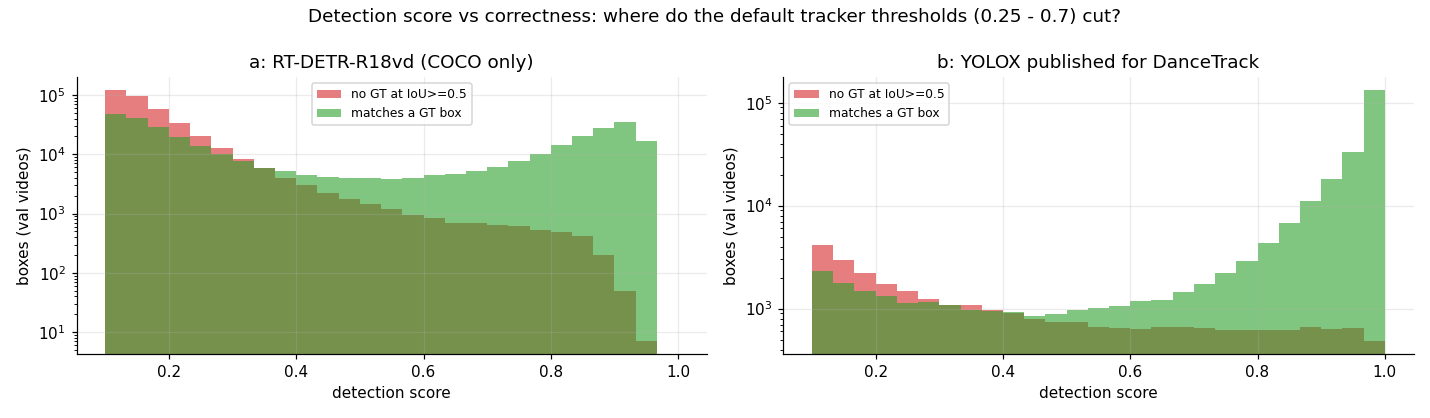

In [9]:
# ---- detection diagnostics: how good are the fixed detections themselves? (IoU 0.5 against GT, by score threshold) ----
THRESHOLDS = (0.1, 0.3, 0.5, 0.7)
DIAG_ROWS = []
SCORE_SPLIT = {s: dict(matched=[], unmatched=[]) for s in SRC}
for source in SRC:
    for seq in VAL + DEV:
        length = SEQ[seq]['length']
        gt = SEQ[seq]['gt']
        gt = gt[gt[:, 6] != 0] if gt.shape[1] > 6 else gt
        gt_f, det_f = ts._split_by_frame(gt, length), tr.dets_by_frame(DETS[source][seq], length)
        acc = {thr: [0, 0, 0] for thr in THRESHOLDS}                 # detections kept, of which matched to GT, GT matched
        for g, d in zip(gt_f, det_f):
            iou = ts.box_iou_xywh(d[:, 2:6], g[:, 2:6])
            best = iou.max(1) if iou.size else np.zeros(len(d))
            if seq in VAL:
                SCORE_SPLIT[source]['matched'] += d[best >= .5, 6].tolist()
                SCORE_SPLIT[source]['unmatched'] += d[best < .5, 6].tolist()
            for thr in THRESHOLDS:
                keep = d[:, 6] >= thr
                acc[thr][0] += int(keep.sum())
                acc[thr][1] += int((best[keep] >= .5).sum())
                acc[thr][2] += int((iou[keep].max(0) >= .5).sum()) if keep.any() and len(g) else 0
        for thr, (n_det, tp_det, tp_gt) in acc.items():
            DIAG_ROWS.append(dict(source=source, seq=seq, split='val' if seq in VAL else 'dev', camera=STRATA[seq]['camera'],
                                  gt_per_frame=len(gt) / length, thr=thr, dets_per_frame=n_det / length,
                                  precision=tp_det / max(n_det, 1), recall=tp_gt / max(len(gt), 1)))
DIAG_DF = pd.DataFrame(DIAG_ROWS)
DIAG_DF.to_csv(OUT / 'tables' / f'{MODE}_det_diagnostics.csv', index=False)
for thr in (0.5,):
    view = DIAG_DF[DIAG_DF.thr == thr].pivot_table(index=['seq', 'split', 'camera', 'gt_per_frame'], columns='source',
                                                   values=['dets_per_frame', 'precision', 'recall'])
    print(f'\nDetections vs GT at score >= {thr} (IoU 0.5), per video:')
    display(view.round(3))
weak = DIAG_DF[(DIAG_DF.thr == 0.5) & (DIAG_DF.recall < 0.5)]
if len(weak):
    print('DETECTOR_WEAK_ON_VIDEO (recall < 0.5 at score >= 0.5):', weak[['source', 'seq', 'recall']].round(3).to_dict('records'))
fig, ax = plt.subplots(1, len(SRC), figsize=(6.5 * len(SRC), 3.8), squeeze=False)
for a, source in zip(ax[0], SRC):
    bins = np.linspace(0.1, 1, 28)
    a.hist(SCORE_SPLIT[source]['unmatched'], bins=bins, alpha=.6, label='no GT at IoU>=0.5', color='#d62728')
    a.hist(SCORE_SPLIT[source]['matched'], bins=bins, alpha=.6, label='matches a GT box', color='#2ca02c')
    a.set_yscale('log'); a.set_xlabel('detection score'); a.set_ylabel('boxes (val videos)'); a.set_title(DATASET_SOURCES[source]['label']); a.legend(fontsize=8)
fig.suptitle('Detection score vs correctness: where do the default tracker thresholds (0.25 - 0.7) cut?')
savefig(fig, 'det_score_calibration.png')

## 5. Tầng B — tuning trên dev
Mỗi (tracker, cấu hình, sequence) lưu track thô và điểm TrackEval (resumable). Chọn cấu hình dev-HOTA trung bình cao nhất; hòa thì chỉ số nhỏ hơn. Val không được đụng tới ở bước này.

In [10]:
STORE = OUT / 'runs'
SCORES = OUT / 'scores'


def run_one(source, fam, ci, seq):
    spec, params = SPECS[fam], CONFIGS[fam][ci]

    def go():
        t0 = time.perf_counter()
        tracker = tr.build_tracker(spec, params, SEQ[seq]['fps'])
        res = tr.run_sequence(tracker, DETS[source][seq], SEQ[seq]['length'], frames=SEQ[seq]['frame'], needs_frame=spec.needs_frame)
        res['wall_seconds'] = time.perf_counter() - t0          # update + frame decode + conversion (the cost the budget needs)
        return res
    return tr.run_or_load(STORE / source, fam, ci, seq, params, DETS[source][seq], go)


def scored(source, fam, ci, seq):
    """(score, run meta) for one (source, tracker, config, sequence); the TrackEval result is cached next to the run."""
    run = run_one(source, fam, ci, seq)
    key = (run.get('params_sha256'), run.get('dets_sha256'))
    cache = SCORES / source / fam / f'cfg{ci:02d}' / f'{seq}.pkl'
    if cache.exists():
        blob = pickle.loads(cache.read_bytes())
        if blob['key'] == key:
            return blob['score'], {**run, 'score_seconds': blob.get('score_seconds')}
    t0 = time.perf_counter()
    score = tr.score_run(SEQ[seq]['gt'], run, SEQ[seq]['length'])
    score_seconds = time.perf_counter() - t0
    cache.parent.mkdir(parents=True, exist_ok=True)
    cache.write_bytes(pickle.dumps(dict(key=key, score=score, score_seconds=score_seconds)))
    return score, {**run, 'score_seconds': score_seconds}


def seq_hota(score):
    return ts.summarize(ts.combine([score['result']]))['HOTA']


# ---- tuning on the dev sequences (train split only; val is never touched here) ----
TUNING, CHOSEN = {}, {}
t_b = time.time()
for source in SRC:
    for fam in SPECS:
        means = {}
        for ci in CFG_IDX:
            per_seq = [scored(source, fam, ci, seq)[0] for seq in DEV]
            means[ci] = float(np.mean([seq_hota(s) for s in per_seq])) if all(s['ok'] for s in per_seq) else float('nan')
            print(f'  tune {source}/{fam} cfg{ci:02d}: dev HOTA {means[ci]:.2f}', end='\r', flush=True)
        valid = {ci: v for ci, v in means.items() if not np.isnan(v)}
        best = min(valid, key=lambda ci: (-valid[ci], ci)) if valid else None      # ties -> lower index
        TUNING[(source, fam)], CHOSEN[(source, fam)] = means, best
        print(f'{source}/{fam}: dev HOTA default {means[0]:.2f} | best cfg {best} = {means.get(best, float("nan")):.2f}')
write_json(OUT / 'tables' / f'{MODE}_tuning.json', {f'{s}|{f}': dict(dev_hota=v, chosen=CHOSEN[(s, f)], params=CONFIGS[f][CHOSEN[(s, f)]] if CHOSEN[(s, f)] is not None else None)
                                                    for (s, f), v in TUNING.items()})
print(f'tuning wall time {(time.time() - t_b) / 60:.1f} min')

a/botsort: dev HOTA default 43.60 | best cfg 0 = 43.60
a/bytetrack: dev HOTA default 42.56 | best cfg 16 = 43.96
a/ocsort: dev HOTA default 39.10 | best cfg 19 = 41.37
a/sort: dev HOTA default 17.89 | best cfg 9 = 23.42
b/botsort: dev HOTA default 72.79 | best cfg 0 = 72.79
b/bytetrack: dev HOTA default 68.60 | best cfg 15 = 71.57
b/ocsort: dev HOTA default 61.81 | best cfg 16 = 64.93
b/sort: dev HOTA default 60.04 | best cfg 9 = 63.44
tuning wall time 169.5 min


## 6. Đánh giá trên val
Mặc định và tuned, mỗi nguồn detections một bảng. Sequence lỗi làm hệ thống đó không có điểm (không tính là 0).

In [11]:
# ---- evaluation on val: published default (cfg 0) and the dev-tuned config, per tracker and detection source ----
SYSTEMS, FPS = {}, {}
for source in SRC:
    for fam in SPECS:
        for variant, ci in (('default', 0), ('tuned', CHOSEN[(source, fam)])):
            if ci is None:
                continue
            pairs = {seq: scored(source, fam, ci, seq) for seq in VAL}
            SYSTEMS[(source, fam, variant)] = dict(ci=ci, scores={seq: p[0] for seq, p in pairs.items()})
            fps = [p[1].get('fps') for p in pairs.values() if p[1].get('fps')]
            FPS[(source, fam, variant)] = float(np.median(fps)) if fps else float('nan')


def summary_table(source):
    rows = []
    for (s, fam, variant), sysd in SYSTEMS.items():
        if s != source:
            continue
        agg = tr.score_config(sysd['scores'])
        base = dict(tracker=fam, variant=variant, cfg=sysd['ci'], fps=FPS[(s, fam, variant)])
        if agg['score'] is None:
            rows.append({**base, 'failed': json.dumps(agg['failed'])})
        else:
            sc = agg['score']
            rows.append({**base, **{k: sc[k] for k in ('HOTA', 'DetA', 'AssA', 'LocA', 'IDF1', 'MOTA', 'IDSW', 'Frag', 'MT', 'ML')}})
    return pd.DataFrame(rows)


TABLES = {}
for source in SRC:
    t = summary_table(source)
    TABLES[source] = t
    print(f'\n=== {DATASET_SOURCES[source]["label"]} {DATASET_SOURCES[source]["flags"]} {"(" + MODE.upper() + ", không công bố)" if MODE != "full" else ""} ===')
    display(t.round(3))
    t.to_csv(OUT / 'tables' / f'{MODE}_summary_{source}.csv', index=False)
    if len(t) and 'failed' in t and t['failed'].notna().any():
        print('CÓ SEQUENCE LỖI: hệ thống tương ứng không có điểm (không tính là 0).')


=== a: RT-DETR-R18vd (COCO only) []  ===


,tracker,variant,cfg,fps,HOTA,DetA,AssA,LocA,IDF1,MOTA,IDSW,Frag,MT,ML
0,botsort,default,0,46.612,40.181,60.621,26.892,86.039,41.631,69.476,1809,4051,113,37
1,botsort,tuned,0,46.612,40.181,60.621,26.892,86.039,41.631,69.476,1809,4051,113,37
2,bytetrack,default,0,1490.091,38.873,58.979,25.939,84.827,40.906,64.683,2991,5360,146,29
3,bytetrack,tuned,16,1755.327,38.735,58.803,25.815,85.076,40.223,64.568,2563,4869,134,35
4,ocsort,default,0,1298.533,34.389,52.011,22.860,88.151,36.883,59.544,1809,5476,47,52
5,ocsort,tuned,19,1275.760,36.238,55.908,23.636,87.494,37.996,64.112,2290,8041,72,43
6,sort,default,0,713.588,16.894,33.703,8.706,83.743,11.153,-32.715,16566,6927,215,3
7,sort,tuned,9,1084.835,22.352,45.081,11.282,83.696,17.908,27.565,9666,6884,177,21



=== b: YOLOX published for DanceTrack ['DETECTOR_TRAIN_DATA_UNVERIFIED']  ===


,tracker,variant,cfg,fps,HOTA,DetA,AssA,LocA,IDF1,MOTA,IDSW,Frag,MT,ML
0,botsort,default,0,45.070,51.070,77.891,33.618,90.580,49.786,88.099,2518,3300,253,3
1,botsort,tuned,0,45.070,51.070,77.891,33.618,90.580,49.786,88.099,2518,3300,253,3
2,bytetrack,default,0,1397.613,48.032,74.736,31.038,90.404,45.483,83.664,3493,3534,256,3
3,bytetrack,tuned,15,1522.804,48.977,77.178,31.227,90.536,46.140,86.997,2763,3443,249,3
4,ocsort,default,0,914.900,48.944,77.857,30.905,91.181,46.618,87.261,2706,4215,222,3
5,ocsort,tuned,16,963.130,49.378,78.060,31.360,90.904,47.959,87.916,3241,4458,235,3
6,sort,default,0,1551.474,42.674,73.687,24.898,90.461,36.793,80.655,4880,4051,256,3
7,sort,tuned,9,1583.330,44.536,73.821,27.047,90.326,40.169,82.412,3856,3995,254,3


## 7. So sánh cặp
Bootstrap theo video; kết luận chỉ khi CI cặp loại trừ 0 và |ΔHOTA| ≥ 2.0, ngược lại là *indistinguishable*.

In [12]:
# ---- paired video bootstrap: same resamples for every system; each system resampled once and reused ----
MULT = pb.cluster_multiplicities(len(VAL), None, N_BOOT, SEED)
DECISIONS, CI = {}, {}
for source in SRC:
    series = {}
    for key, sysd in SYSTEMS.items():
        if key[0] != source or any(not s['ok'] for s in sysd['scores'].values()):
            continue
        per_seq = [sysd['scores'][seq]['result'] for seq in VAL]
        series[key] = pb.metric_series(ts.metric_on_resample(per_seq, 'HOTA'), MULT)
        CI[key] = (float(np.nanquantile(series[key][1], .025)), float(np.nanquantile(series[key][1], .975)))
    pairs = []
    fams = list(SPECS)
    for variant in ('default', 'tuned'):
        for i in range(len(fams)):
            for j in range(i + 1, len(fams)):
                pairs.append((f'{variant}: {fams[i]} vs {fams[j]}', (source, fams[i], variant), (source, fams[j], variant)))
    for fam in fams:
        pairs.append((f'{fam}: tuned vs default', (source, fam, 'tuned'), (source, fam, 'default')))
    out = []
    for name, ka, kb in pairs:
        if ka not in series or kb not in series or SYSTEMS[ka]['ci'] == SYSTEMS[kb]['ci'] and ka[1] == kb[1]:
            continue
        res = pb.paired_from_series(series[ka], series[kb])
        out.append(dict(comparison=name, HOTA_a=res['a'], HOTA_b=res['b'], delta=res['delta'], ci_lo=res['delta_lo'], ci_hi=res['delta_hi'],
                        verdict=pb.decide_difference(res, tr.PRACTICAL_HOTA_THRESHOLD)))
    df = pd.DataFrame(out)
    DECISIONS[source] = df.to_dict('records')
    print(f'\n=== paired comparison, {DATASET_SOURCES[source]["label"]} (unit: video, {N_BOOT} resamples, threshold {tr.PRACTICAL_HOTA_THRESHOLD} HOTA) ===')
    display(df.round(3))
    df.to_csv(OUT / 'tables' / f'{MODE}_pairs_{source}.csv', index=False)
write_json(OUT / 'tables' / f'{MODE}_decisions.json', DECISIONS)


=== paired comparison, a: RT-DETR-R18vd (COCO only) (unit: video, 10000 resamples, threshold 2.0 HOTA) ===


,comparison,HOTA_a,HOTA_b,delta,ci_lo,ci_hi,verdict
0,default: botsort vs bytetrack,40.181,38.873,1.309,-1.161,3.497,indistinguishable
1,default: botsort vs ocsort,40.181,34.389,5.793,4.589,7.136,a_better
2,default: botsort vs sort,40.181,16.894,23.287,20.019,26.519,a_better
3,default: bytetrack vs ocsort,38.873,34.389,4.484,2.367,6.865,a_better
4,default: bytetrack vs sort,38.873,16.894,21.978,19.070,25.159,a_better
5,default: ocsort vs sort,34.389,16.894,17.494,14.243,20.525,a_better
6,tuned: botsort vs bytetrack,40.181,38.735,1.446,-1.249,4.029,indistinguishable
7,tuned: botsort vs ocsort,40.181,36.238,3.943,2.608,5.486,a_better
8,tuned: botsort vs sort,40.181,22.352,17.829,14.054,21.442,a_better
9,tuned: bytetrack vs ocsort,38.735,36.238,2.497,-0.395,5.503,indistinguishable



=== paired comparison, b: YOLOX published for DanceTrack (unit: video, 10000 resamples, threshold 2.0 HOTA) ===


,comparison,HOTA_a,HOTA_b,delta,ci_lo,ci_hi,verdict
0,default: botsort vs bytetrack,51.070,48.032,3.038,0.877,5.031,a_better
1,default: botsort vs ocsort,51.070,48.944,2.126,0.160,3.976,a_better
2,default: botsort vs sort,51.070,42.674,8.396,5.959,10.798,a_better
3,default: bytetrack vs ocsort,48.032,48.944,-0.912,-2.698,0.919,indistinguishable
4,default: bytetrack vs sort,48.032,42.674,5.358,3.446,7.459,a_better
5,default: ocsort vs sort,48.944,42.674,6.270,4.555,8.129,a_better
6,tuned: botsort vs bytetrack,51.070,48.977,2.093,0.149,3.793,a_better
7,tuned: botsort vs ocsort,51.070,49.378,1.692,0.015,3.540,indistinguishable
8,tuned: botsort vs sort,51.070,44.536,6.534,4.335,8.686,a_better
9,tuned: bytetrack vs ocsort,48.977,49.378,-0.401,-1.835,1.045,indistinguishable


## 8. Phân tầng (mô tả)
Theo mật độ, gián đoạn ID, tốc độ và camera (ngưỡng đã đóng băng trên train).

In [13]:
# ---- descriptive breakdown by the frozen strata (tuned configs, pooled over the val videos in each group) ----
STRAT_ROWS = []
for source in SRC:
    for fam in SPECS:
        sysd = SYSTEMS.get((source, fam, 'tuned'))
        if sysd is None or any(not s['ok'] for s in sysd['scores'].values()):
            continue
        for axis in ('tier_density', 'tier_id_gaps', 'tier_speed', 'camera'):
            for level in sorted({STRATA[s][axis] for s in VAL}):
                members = [s for s in VAL if STRATA[s][axis] == level]
                sc = ts.score_sequences([sysd['scores'][s]['result'] for s in members])
                STRAT_ROWS.append(dict(source=source, tracker=fam, axis=axis, level=level, n_videos=len(members),
                                       HOTA=sc['HOTA'], DetA=sc['DetA'], AssA=sc['AssA'], IDSW=sc['IDSW'],
                                       note='CAMERA_DESCRIPTIVE_ONLY' if axis == 'camera' else ('n<3: very wide' if len(members) < 3 else '')))
STRAT_DF = pd.DataFrame(STRAT_ROWS)
if len(STRAT_DF):
    display(STRAT_DF[STRAT_DF.source == SRC[0]].round(2))
    STRAT_DF.to_csv(OUT / 'tables' / f'{MODE}_strata.csv', index=False)
print('Mô tả, không kiểm định: mỗi nhóm chỉ vài video.')

,source,tracker,axis,level,n_videos,HOTA,DetA,AssA,IDSW,note
0,a,botsort,tier_density,high,12,38.45,54.37,27.52,1107,
1,a,botsort,tier_density,low,6,46.39,74.70,28.93,173,
2,a,botsort,tier_density,mid,7,40.68,67.20,24.84,529,
3,a,botsort,tier_id_gaps,high,9,35.37,58.06,21.76,886,
4,a,botsort,tier_id_gaps,low,6,50.09,65.92,38.31,298,
5,a,botsort,tier_id_gaps,mid,10,37.41,59.89,23.65,625,
6,a,botsort,tier_speed,high,3,30.42,61.09,15.18,164,
7,a,botsort,tier_speed,low,14,42.54,63.66,28.74,978,
8,a,botsort,tier_speed,mid,8,38.57,55.28,27.15,667,
9,a,botsort,camera,moving,3,36.83,56.54,24.01,164,CAMERA_DESCRIPTIVE_ONLY


Mô tả, không kiểm định: mỗi nhóm chỉ vài video.


## 9. Trực quan hóa

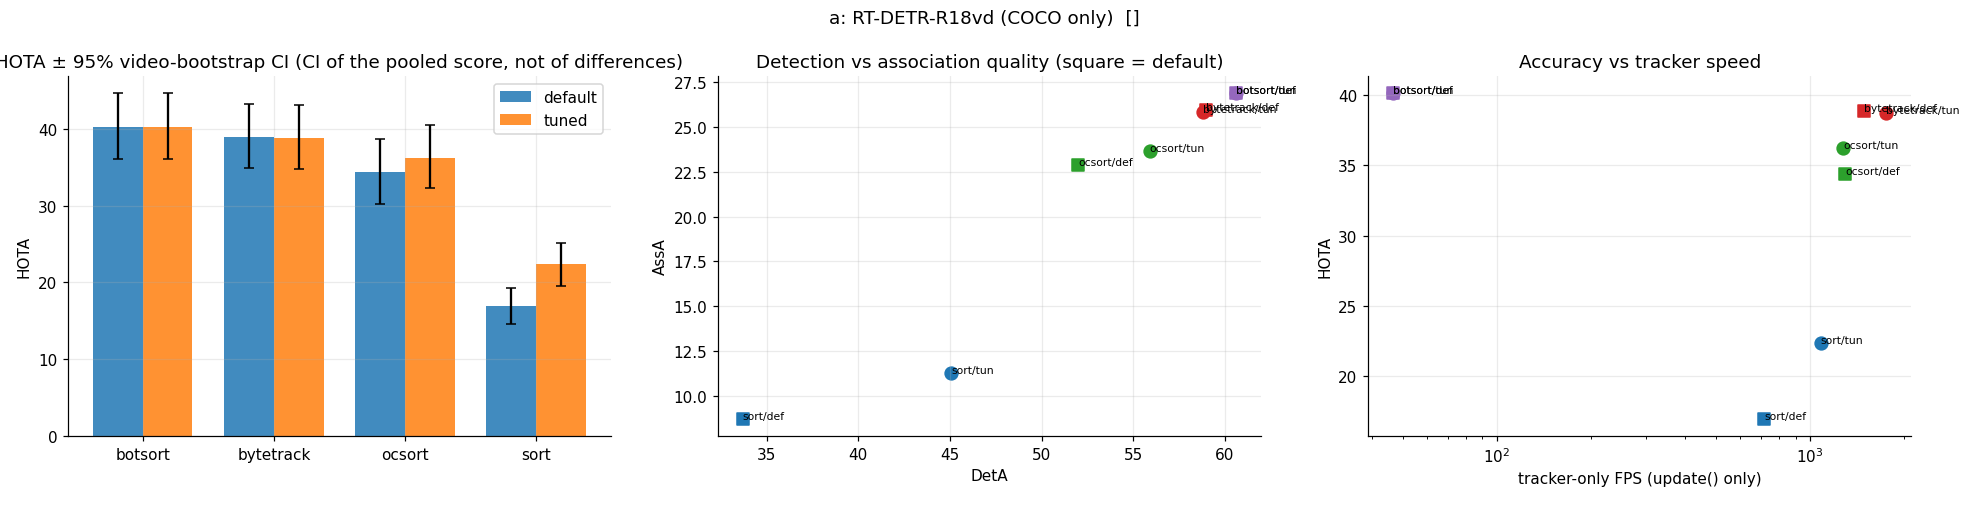

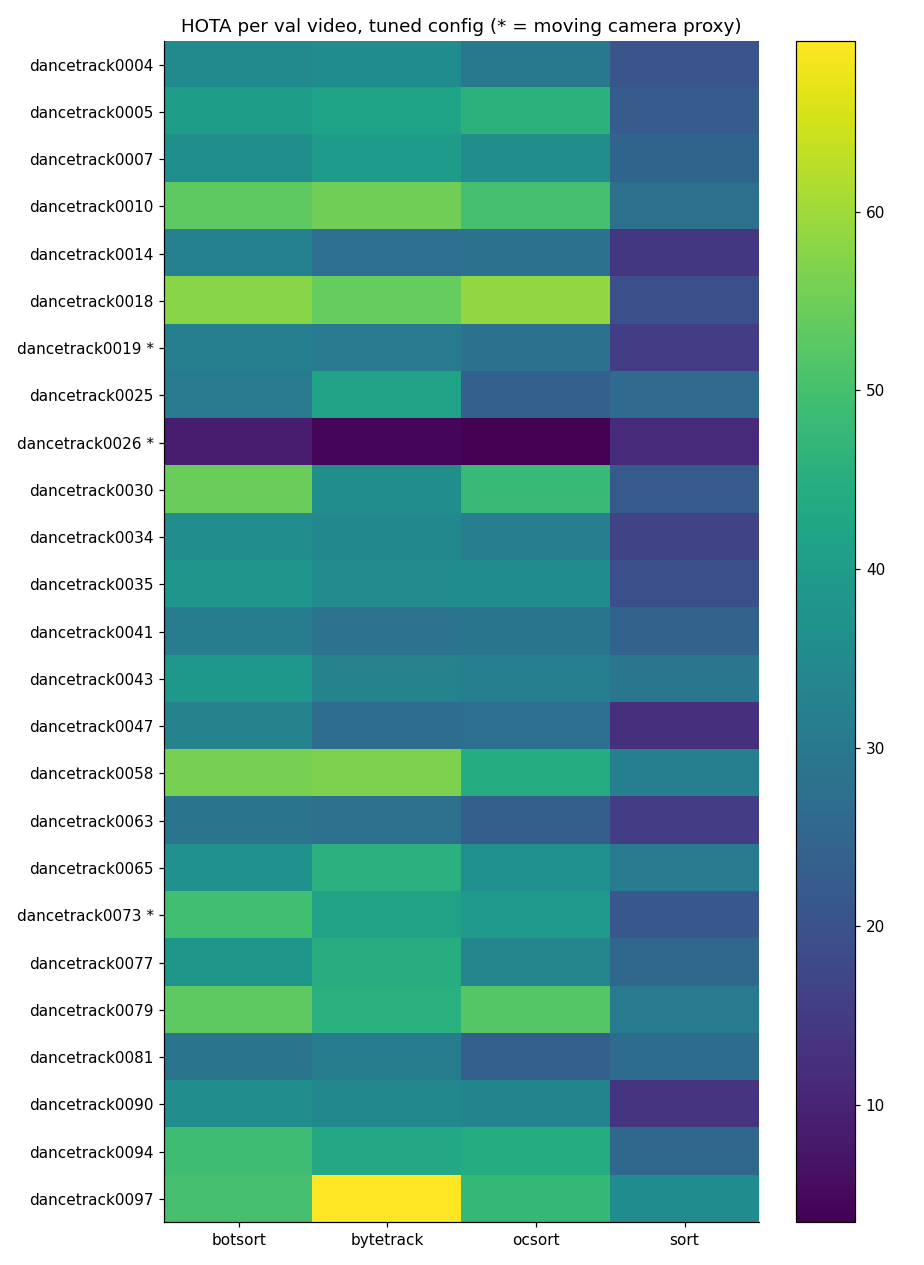

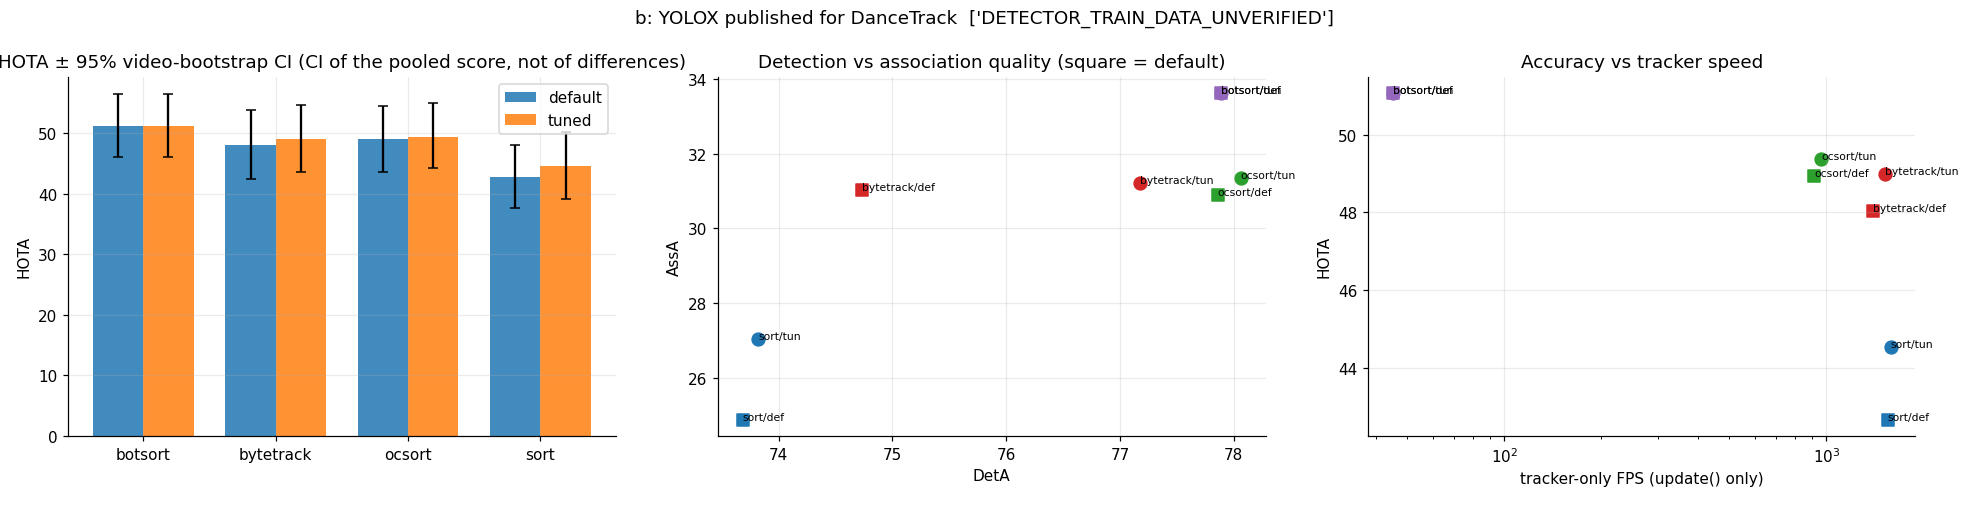

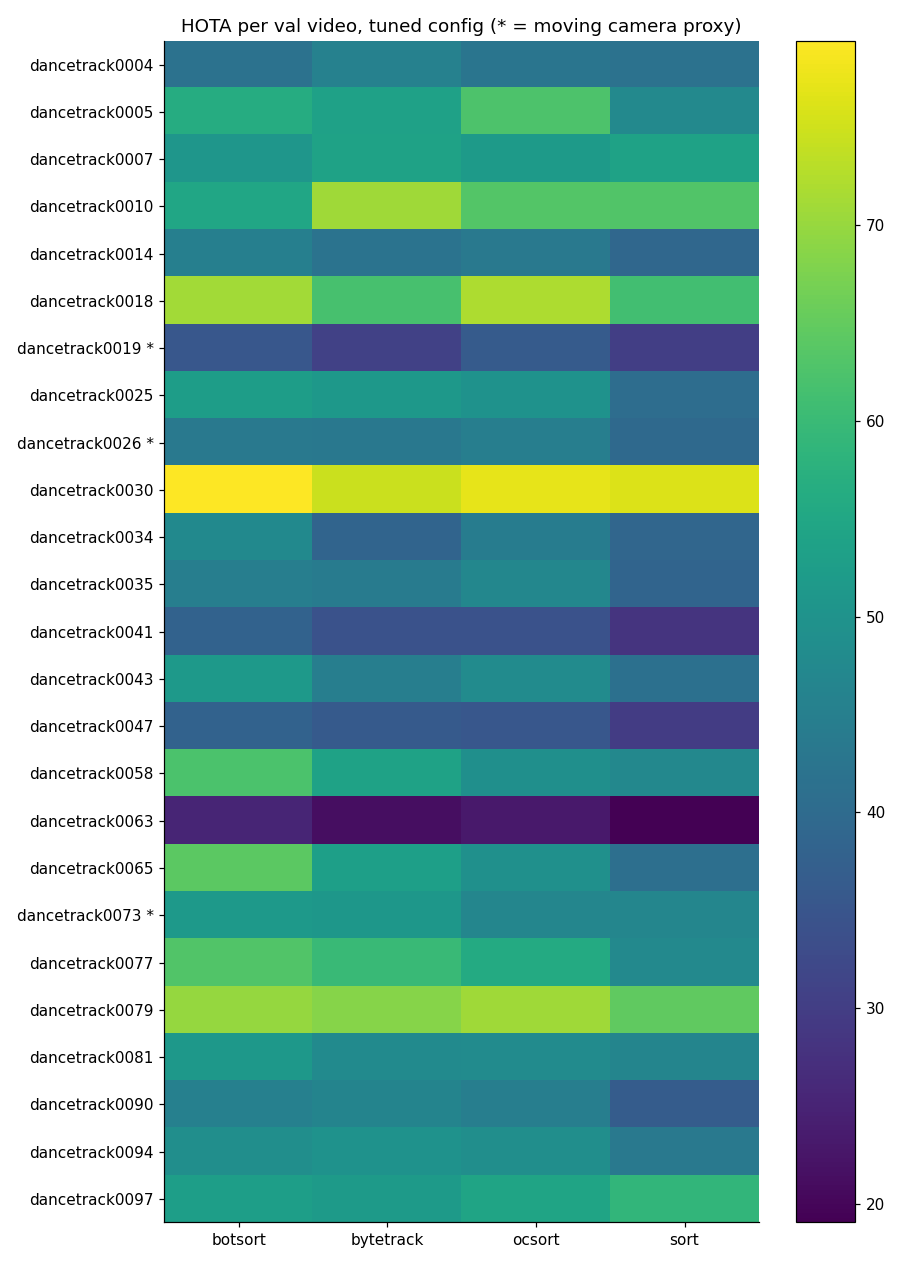

In [14]:
COLORS = dict(sort='#1f77b4', bytetrack='#d62728', ocsort='#2ca02c', botsort='#9467bd')
for source in SRC:
    t = TABLES[source]
    if 'HOTA' not in t or t.HOTA.isna().all():
        continue
    # 1. HOTA with video-bootstrap CI, default vs tuned
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
    fams = list(SPECS)
    x = np.arange(len(fams)); w = .38
    for k, variant in enumerate(('default', 'tuned')):
        vals = [t[(t.tracker == f) & (t.variant == variant)].HOTA.iloc[0] if len(t[(t.tracker == f) & (t.variant == variant)]) else np.nan for f in fams]
        err = np.array([[v - CI[(source, f, variant)][0], CI[(source, f, variant)][1] - v] if (source, f, variant) in CI and not np.isnan(v) else [0, 0]
                        for f, v in zip(fams, vals)]).T
        ax[0].bar(x + (k - .5) * w, vals, w, yerr=err, capsize=3, label=variant, alpha=.85)
    ax[0].set_xticks(x, fams); ax[0].set_ylabel('HOTA'); ax[0].legend(); ax[0].set_title('HOTA ± 95% video-bootstrap CI (CI of the pooled score, not of differences)')
    # 2. AssA vs DetA
    for _, r in t.dropna(subset=['HOTA']).iterrows():
        ax[1].scatter(r.DetA, r.AssA, color=COLORS[r.tracker], marker='o' if r.variant == 'tuned' else 's', s=70)
        ax[1].annotate(f'{r.tracker}/{r.variant[:3]}', (r.DetA, r.AssA), fontsize=7)
    ax[1].set_xlabel('DetA'); ax[1].set_ylabel('AssA'); ax[1].set_title('Detection vs association quality (square = default)')
    # 3. FPS vs HOTA
    for _, r in t.dropna(subset=['HOTA']).iterrows():
        ax[2].scatter(r.fps, r.HOTA, color=COLORS[r.tracker], marker='o' if r.variant == 'tuned' else 's', s=70)
        ax[2].annotate(f'{r.tracker}/{r.variant[:3]}', (r.fps, r.HOTA), fontsize=7)
    ax[2].set_xscale('log'); ax[2].set_xlabel('tracker-only FPS (update() only)'); ax[2].set_ylabel('HOTA'); ax[2].set_title('Accuracy vs tracker speed')
    fig.suptitle(f'{DATASET_SOURCES[source]["label"]}  {DATASET_SOURCES[source]["flags"]}  {BANNER if MODE != "full" else ""}')
    savefig(fig, f'headline_{source}.png')
    # 4. per-video HOTA heatmap (tuned)
    mat = pd.DataFrame({f: {s: seq_hota(SYSTEMS[(source, f, 'tuned')]['scores'][s]) if SYSTEMS[(source, f, 'tuned')]['scores'][s]['ok'] else np.nan for s in VAL}
                        for f in fams if (source, f, 'tuned') in SYSTEMS})
    fig, ax = plt.subplots(figsize=(1.1 * len(mat.columns) + 4, 0.38 * len(mat) + 2))
    im = ax.imshow(mat.values, aspect='auto', cmap='viridis')
    ax.set_xticks(range(mat.shape[1]), mat.columns); ax.set_yticks(range(mat.shape[0]), [s + (' *' if STRATA[s]['camera'] == 'moving' else '') for s in mat.index]); ax.grid(False)
    fig.colorbar(im); ax.set_title('HOTA per val video, tuned config (* = moving camera proxy)')
    savefig(fig, f'heatmap_{source}.png')

## 10. Chi phí và cổng ngân sách
Thời gian CMC của BoT-SORT; ước tính full từ chi phí đo được. `full` từ chối chạy nếu thiếu cổng hợp lệ.

In [15]:
# ---- BoT-SORT: how much of its update time is camera-motion compensation? (one val video, first 200 frames) ----
seq = VAL[0]
n = min(200, SEQ[seq]['length'])
sub = DETS[SRC[0]][seq]
sub = sub[sub[:, 0] <= n]
cmc = {}
for label, over in (('cmc_on', {}), ('cmc_off', {'enable_cmc': False})):
    params = {**CONFIGS['botsort'][0], **over}
    res = tr.run_sequence(tr.build_tracker(SPECS['botsort'], params, SEQ[seq]['fps']), sub, n, frames=SEQ[seq]['frame'], needs_frame=True)
    cmc[label] = res['median_update_ms']
cmc['cmc_ms_per_frame'] = cmc['cmc_on'] - cmc['cmc_off']
print('BoT-SORT median update ms:', cmc)

BoT-SORT median update ms: {'cmc_on': 12.225978998685605, 'cmc_off': 0.8772399996814784, 'cmc_ms_per_frame': 11.348738999004127}


In [16]:
# ---- budget gate: extrapolate measured costs to the full cohorts ----
smoke_update_ms, smoke_ms = {}, {}
for fam in SPECS:
    runs = [scored(source, fam, 0, seq)[1] for source in SRC for seq in VAL]
    smoke_update_ms[fam] = float(np.median([r['median_update_ms'] for r in runs if r.get('median_update_ms')] or [np.nan]))
    # cost per frame of one (config, sequence) job: tracker update + frame decode + TrackEval scoring
    per_frame = [(r['wall_seconds'] + r['score_seconds']) / r['n_frames'] * 1000 for r in runs
                 if r.get('wall_seconds') is not None and r.get('score_seconds') is not None]
    smoke_ms[fam] = float(np.median(per_frame)) if per_frame else float('nan')
dev_frames = sum(FULL_LEN[s] for s in FULL_DEV)
val_frames = sum(FULL_LEN[s] for s in FULL_VAL)
cfgs_full = {f: N_RANDOM + 1 for f in SPECS}
b_dev = tr.estimate_budget(smoke_ms, dev_frames, cfgs_full)
b_val = tr.estimate_budget(smoke_ms, val_frames, {f: 2 for f in SPECS})
tier_b_hours = 2 * (b_dev['total_hours'] + b_val['total_hours'])
spf = {s: float(np.mean([m['seconds_per_frame'] for m in DET_META[s].values()])) for s in SRC}
tier_a_hours = sum(spf[s] * (dev_frames + val_frames) * tr.BUDGET_OVERHEAD / 3600 for s in SRC if s != 'dry')
print(pd.DataFrame(dict(update_ms=smoke_update_ms, job_ms_per_frame=smoke_ms)).round(3))
print(f'Ước tính full: tầng A {tier_a_hours:.2f} GPU-giờ (trần {GPU_BUDGET_HOURS}) | tầng B {tier_b_hours:.2f} giờ CPU (trần {TIER_B_MAX_HOURS})')
gate = dict(tier_a_gpu_hours=tier_a_hours, tier_b_cpu_hours=tier_b_hours, update_ms=smoke_update_ms, job_ms_per_frame=smoke_ms, seconds_per_frame_tier_a=spf, bot_sort_cmc=cmc,
            gpu=GPU, tier_a_on_gpu=(GPU is not None and MODE != 'dry'), mode=MODE,
            over_budget=bool(tier_a_hours > GPU_BUDGET_HOURS or tier_b_hours > TIER_B_MAX_HOURS),
            valid=bool(MODE == 'smoke' and GPU is not None), finished_utc=datetime.now(timezone.utc).isoformat())
if MODE in ('dry', 'smoke'):
    write_json(OUT / ('smoke-budget-gate.json' if MODE == 'smoke' else 'dry-budget-gate.json'), gate)
    if MODE == 'dry':
        print('Gate của dry không bao giờ hợp lệ cho full.')
    elif GPU is None:
        print('Ước tính KHÔNG hợp lệ: smoke chạy không có GPU. Chạy lại smoke trên Colab GPU trước khi chạy full.')
    elif gate['over_budget']:
        print('DỪNG: ước tính vượt trần. Báo kết quả này cho người duyệt ngân sách; không tự cắt phạm vi.')
    else:
        print('Trong ngân sách. Có thể đặt MODE = "full" và chạy lại từ đầu notebook.')

           update_ms  job_ms_per_frame
botsort       20.123            29.147
bytetrack      0.672             1.222
ocsort         0.878             1.473
sort           0.881             1.596
Ước tính full: tầng A 5.45 GPU-giờ (trần 12.0) | tầng B 5.45 giờ CPU (trần 10.0)


## 11. Lưu kết quả

In [17]:
import importlib.metadata as md


def ver(n):
    try:
        return md.version(n)
    except Exception:
        return None


manifest = dict(
    run_id=RUN_ID, mode=MODE, finished_utc=datetime.now(timezone.utc).isoformat(), gpu=GPU, python=platform.python_version(),
    libraries={n: ver(n) for n in ('trackers', 'supervision', 'numpy', 'scipy', 'opencv-python-headless', 'torch', 'transformers', 'TrackEval')},
    trackeval_commit=ts.PINNED_TRACKEVAL_COMMIT, source_digests=DIGESTS,
    frozen=dict(sequence_ids_sha256=MOT['sequence_ids_sha256'], stratification_status=STRAT['status'], search_space_status=SPACE['status'],
                dev_sequences=DEV, val_sequences=VAL, configs_per_tracker=len(CFG_IDX), seed_configs=SEED_CFG),
    detection_sources={s: dict(**DATASET_SOURCES[s], meta={q_: v for q_, v in DET_META[s].items()}) for s in SRC},
    source_a_choice=SOURCE_A, source_b_info=SOURCE_B_INFO,
    chosen_configs={f'{s}|{f}': dict(cfg=c, params=CONFIGS[f][c] if c is not None else None) for (s, f), c in CHOSEN.items()},
    botsort_cmc=cmc, decisions=DECISIONS,
    sequence_frame_rates={s_: SEQ[s_]['fps'] for s_ in VAL + DEV},     # frame_rate actually passed to every tracker (the config files show the library default 30)
    detection_diagnostics=f'tables/{MODE}_det_diagnostics.csv',
    weak_detector_videos=weak[['source', 'seq', 'recall']].round(4).to_dict('records'),     # recall < 0.5 at score >= 0.5: tracker gaps there are detection-limited
    reportable=(MODE == 'full'),
    note={'dry': 'synthetic data: validates the notebook only', 'smoke': 'smoke results validate the pipeline and costs only',
          'full': 'frozen protocol; source (b) results carry DETECTOR_TRAIN_DATA_UNVERIFIED'}[MODE])
write_json(OUT / f'{MODE}_manifest.json', manifest)
bundle = OUT / f'bundle_{MODE}.zip'
with zipfile.ZipFile(bundle, 'w', zipfile.ZIP_DEFLATED) as zf:
    for path in sorted(OUT.rglob('*')):
        if path.is_file() and path.suffix in {'.json', '.csv', '.png'} and not path.name.startswith('bundle_') and 'runs' not in path.parts and 'scores' not in path.parts and 'dets' not in path.parts:
            zf.write(path, path.relative_to(OUT))
print('Bundle:', bundle, f'{bundle.stat().st_size / 1e6:.2f} MB (chỉ JSON/CSV/PNG; track thô và detections ở', OUT, ')')

Bundle: /content/drive/MyDrive/DetTrack/track-03b-261027-v1/bundle_full.zip 0.59 MB (chỉ JSON/CSV/PNG; track thô và detections ở /content/drive/MyDrive/DetTrack/track-03b-261027-v1 )
